# Deconstructing Domain Shift in Diabetic Retinopathy Grading: A Multi-Scale Multiple Instance Learning Approach with Ordinal Regression

[![PyTorch](https://img.shields.io/badge/PyTorch-2.0%2B-EE4C2C.svg?logo=pytorch)](https://pytorch.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-blue.svg)](https://opensource.org/licenses/MIT)
[![Domain: Medical Imaging](https://img.shields.io/badge/Domain-Medical%20Computer%20Vision-success.svg)]()
[![Task: 5-Grade Ordinal DR](https://img.shields.io/badge/Task-5--Grade%20Ordinal%20DR-informational.svg)]()

---

## 📌 Executive Summary & Architectural Overview

This notebook contains the complete, reproducible end-to-end implementation of the **Multi-Scale All-CNN Hybrid Extractor** coupled with **Cumulative Link Model Ordinal Regression ($\text{CLM\_QWK}$)** for 5-class Diabetic Retinopathy (DR) grading (Grades 0 to 4).

### Key Architectural Pillars:
1. **Global Context Branch (Macro-Retinal View)**: Whole-fundus image ($300 \times 300$) $\rightarrow$ Pre-trained `ResNet-50` + `CBAM` Attention $\rightarrow F_{\text{global}} \in \mathbb{R}^{2048}$ (captures retinal vessel architecture, optic disc alignment, and 4-quadrant lesion distribution).
2. **Local Multi-Instance Learning Branch (Micro-Lesion View)**: Native resolution active fundus $\rightarrow$ $K=16$ non-overlapping patches ($128 \times 128$) $\rightarrow$ Shared `EfficientNet-B0` per patch $\rightarrow$ 1D MIL Max-Pooling $\rightarrow F_{\text{local}} \in \mathbb{R}^{1280}$ (preserves microaneurysms and subtle hemorrhages without downsampling erasure).
3. **Multimodal Latent Fusion**: Direct concatenation $[F_{\text{global}}, F_{\text{local}}] \in \mathbb{R}^{3328} \rightarrow \text{Mish MLP} \rightarrow \text{LayerNorm} \rightarrow$ Latent Embedding $\mathbf{z} \in \mathbb{R}^{512}$.
4. **Champion Ordinal Head ($\text{CLM\_QWK}$)**: Cumulative Link Model with complementary log-log ($\text{clog-log}$) link and strictly monotonic cutpoints ($\theta_1 < \theta_2 < \theta_3 < \theta_4$) optimized via hybrid **Interval NLL + Differentiable Quadratic Weighted Kappa (QWK)** loss.

---

## 🎯 Research Hypotheses Verification Mapping

| Hypothesis | Architectural Component | Core Verification Metric | Target Benchmark |
| :--- | :--- | :--- | :--- |
| **H1 (Micro-Lesions)** | Local MIL Branch ($128 \times 128$ Patches) | Grade 1 (Mild DR) Sensitivity / Recall | $+36.9\%$ over Global Baseline |
| **H2 (Global Context)** | Global Branch + CBAM Spatial/Channel Attention | Grade 3 (Severe DR) 4-Quadrant Detection | $+18.2\%$ Grade 3 Recall |
| **H3 (Ordinal Alignment)** | Cumulative Link Model ($\text{CLM\_QWK}$) | Rank Monotonicity Violations & Test QWK | $\mathbf{0.0\%}$ Violations, $+0.041$ QWK |
| **H4 (Domain Robustness)** | Ben Graham Green-Channel Preprocessing | Generalization Gap / LODO Domain Drop ($\Delta_{\text{QWK}}$) | $\le 0.052$ Generalization Gap |
| **H5 (XAI Fidelity)** | Grad-CAM Saliency Maps on Layer 4 | Mean IoU & Pointing Game vs. IDRiD Masks | $\text{IoU} \ge 0.45$, $\text{Pointing} \ge 88\%$ |

---

## 📖 Table of Contents

- [1. Environment Setup & Configuration](#1-environment-setup--configuration)
  - [1.1 Library Imports & Singleton Logger](#11-library-imports--singleton-logger)
  - [1.2 Dataset Path Definitions](#12-dataset-path-definitions)
  - [1.3 Publication-Ready Plotting Standards](#13-publication-ready-plotting-standards)
- [2. Multi-Scale Retinal Data Pipeline](#2-multi-scale-retinal-data-pipeline)
  - [2.1 Green-Channel Preprocessing & Ablation Strategy](#21-green-channel-preprocessing--ablation-strategy)
  - [2.2 Global Context Data Augmentations](#22-global-context-data-augmentations)
  - [2.3 Dual-Branch PyTorch Dataset](#23-dual-branch-pytorch-dataset)
  - [2.4 Active Fundus Bounding Box & MIL Patch Extraction](#24-active-fundus-bounding-box--mil-patch-extraction)
  - [2.5 DataLoader Initialization with Dynamic Collate](#25-dataloader-initialization-with-dynamic-collate)
  - [2.6 Visual Batch Inspection & Patch Verification](#26-visual-batch-inspection--patch-verification)
  - [2.7 Class Distribution & Imbalance Breakdown](#27-class-distribution--imbalance-breakdown)
- [3. Deep Neural Network Architecture & Ordinal Heads](#3-deep-neural-network-architecture--ordinal-heads)
  - [3.1 Convolutional Block Attention Module (CBAM)](#31-convolutional-block-attention-module-cbam)
  - [3.2 Global Context Branch (ResNet-50 + CBAM)](#32-global-context-branch-resnet-50--cbam)
  - [3.3 Local MIL Branch (EfficientNet-B0 + 1D Max-Pooling)](#33-local-mil-branch-efficientnet-b0--1d-max-pooling)
  - [3.4 Multimodal Dual-Branch Latent Fusion](#34-multimodal-dual-branch-latent-fusion)
  - [3.5 Output Head Ablation Suite & Loss Formulations](#35-output-head-ablation-suite--loss-formulations)
  - [3.6 End-to-End Model Wrapper & Offline Feature Caching](#36-end-to-end-model-wrapper--offline-feature-caching)
  - [3.7 Unified Model Factory Builder](#37-unified-model-factory-builder)
- [4. Training Engine & Clinical Evaluation Metrics](#4-training-engine--clinical-evaluation-metrics)
  - [4.1 Comprehensive Medical & Statistical Metric Suite](#41-comprehensive-medical--statistical-metric-suite)
  - [4.2 High-Performance DRTrainer Engine with AMP](#42-high-performance-drtrainer-engine-with-amp)
  - [4.3 Phase 1: End-to-End Main Backbone Training (CLM_QWK)](#43-phase-1-end-to-end-main-backbone-training-clm_qwk)
- [5. Explainable AI (XAI) & Quantitative Saliency Fidelity](#5-explainable-ai-xai--quantitative-saliency-fidelity)
  - [5.1 FundusGradCAM Saliency Generator](#51-fundusgradcam-saliency-generator)
  - [5.2 Quantitative XAI Evaluation (Mean IoU & Pointing Game vs. IDRiD Masks)](#52-quantitative-xai-evaluation-mean-iou--pointing-game-vs-idrid-masks)
- [6. Evaluation & Publication-Quality Results Dashboard](#6-evaluation--publication-quality-results-dashboard)
  - [6.1 Best Checkpoint Restoration & In-Distribution Test Evaluation](#61-best-checkpoint-restoration--in-distribution-test-evaluation)
  - [6.2 4-Panel Publication Results Dashboard Generation](#62-4-panel-publication-results-dashboard-generation)

# 1. Environment Setup & Configuration

This section initializes required deep learning frameworks (`PyTorch`, `Torchvision`), scientific computing libraries (`NumPy`, `Pandas`, `Albumentations`, `OpenCV`), dynamic path injection for modular imports, a singleton logger to avoid duplicate log entries in interactive notebook environments, and publication-ready plotting aesthetics following IEEE/Springer journal guidelines.

## 1.1 Library Imports & Single Logger

In [33]:
import os
import sys
import time
import logging
from pathlib import Path, PureWindowsPath
from typing import List, Tuple, Union, Dict, Optional, Any

# --- Deep Learning & PyTorch Core ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset

# --- Image Processing & Data Manipulation ---
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import albumentations as A

# --- Dynamic Path Resolution ---
# Dynamically add the shared modular pipeline root ('pipeline/full') to sys.path
current_dir = Path().cwd()
full_pipeline_path = current_dir.parent.parent.parent / "pipeline" / "full"

if str(full_pipeline_path) not in sys.path:
    sys.path.append(str(full_pipeline_path))

# --- Clinical & Statistical Evaluation Metrics ---
from sklearn.metrics import (
    cohen_kappa_score,
    confusion_matrix,
    accuracy_score,
    recall_score,
    roc_curve,
    auc,
)

# --- Logging Configuration ---
# Setup logger with a singleton stream handler to prevent duplicate logs in Jupyter/interactive runs
logger = logging.getLogger("DRTrainer")
if not logger.handlers:
    handler = logging.StreamHandler()
    formatter = logging.Formatter("[%(levelname)s | %(asctime)s | DRTrainer] %(message)s")
    handler.setFormatter(formatter)
    logger.addHandler(handler)
logger.setLevel(logging.INFO)

# --- Visualization & Academic Plotting ---
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import collections
from functools import partial
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 1.2 Dataset Path Definitions

In [34]:
# ==============================================================================
# 1.2 CONFIGURATION & DATASET PATHS (SMOKE_TEST vs. FULL_RUN)
# ==============================================================================
# Đổi cờ này thành False khi chạy thực nghiệm chính thức lấy số liệu cho bài báo
SMOKE_TEST = True

image_root_dir = "../../../../data/raw/hybrid/native_cropped"
qwk_warmup_epochs=5
if SMOKE_TEST:
    print(" [CHẾ ĐỘ SMOKE TEST]: Chạy thử nghiệm nhanh kiểm tra luồng pipeline (3 epochs, mini dataset).")
    csv_train_path = "../../../../data/raw/samples/hybrid/sample_50_metadata.csv"
    csv_val_path   = "../../../../data/raw/samples/hybrid/val_sample_50_metadata.csv"
    csv_test_path  = "../../../../data/raw/samples/hybrid/test_sample_50_metadata.csv"
    
    # Fallback nếu thiếu file sample 50
    if not os.path.exists(csv_train_path): csv_train_path = "../../../../data/raw/hybrid/train_metadata.csv"
    if not os.path.exists(csv_val_path):   csv_val_path   = "../../../../data/raw/hybrid/val_metadata.csv"
    if not os.path.exists(csv_test_path):  csv_test_path  = "../../../../data/raw/hybrid/test_metadata.csv"
    
    EPOCHS = 3
    BATCH_SIZE = 8
    QWK_WARMUP_EPOCHS = 1
    T_MAX = 3
else:
    print(" [CHẾ ĐỘ FULL RUN]: Huấn luyện chính thức toàn bộ dataset (CosineAnnealing T_max=30).")
    csv_train_path = "../../../../data/raw/hybrid/train_metadata.csv"
    csv_val_path   = "../../../../data/raw/hybrid/val_metadata.csv"
    csv_test_path  = "../../../../data/raw/hybrid/test_metadata.csv"
    
    # Fallback an toàn nếu chưa mount full dataset
    if not os.path.exists(csv_train_path): csv_train_path = "../../../../data/raw/samples/hybrid/sample_50_metadata.csv"
    if not os.path.exists(csv_val_path):   csv_val_path   = "../../../../data/raw/samples/hybrid/val_sample_50_metadata.csv"
    if not os.path.exists(csv_test_path):  csv_test_path  = "../../../../data/raw/samples/hybrid/test_sample_50_metadata.csv"
    
    EPOCHS = 100
    BATCH_SIZE = 32  # Điều chỉnh 16 hoặc 32 tùy theo dung lượng VRAM
    QWK_WARMUP_EPOCHS = 5
    T_MAX = 30

IMG_SIZE=512
num_workers = min(8, os.cpu_count() or 4)
use_pin_memory = torch.cuda.is_available()

print(f" Train Path: {csv_train_path}")
print(f" Val Path:   {csv_val_path}")
print(f" Test Path:  {csv_test_path}")
print(f" Epochs: {EPOCHS} | Batch Size: {BATCH_SIZE} | Warmup Epochs: {QWK_WARMUP_EPOCHS}")

 [CHẾ ĐỘ SMOKE TEST]: Chạy thử nghiệm nhanh kiểm tra luồng pipeline (3 epochs, mini dataset).
 Train Path: ../../../../data/raw/samples/hybrid/sample_50_metadata.csv
 Val Path:   ../../../../data/raw/samples/hybrid/val_sample_50_metadata.csv
 Test Path:  ../../../../data/raw/samples/hybrid/test_sample_50_metadata.csv
 Epochs: 3 | Batch Size: 8 | Warmup Epochs: 1


## 1.3 Publication-Ready Plotting Standards

In [35]:
# ==================================================================================================
# 0. GLOBAL PUBLICATION PLOTTING CONFIGURATION (IEEE / Springer / Nature Standards)
# ==================================================================================================
def configure_publication_style():
    """
    Sets up cohesive typography, axis weights, subtle grids, and high-resolution
    export parameters suitable for IEEE/Springer journal publication figures.
    """
    plt.rcParams.update({
        # --- Typography & Font Hierarchy ---
        # Cross-platform sans-serif fallbacks with proportional font sizes
        'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
        'font.family': 'sans-serif',
        'font.size': 10.5,
        'axes.labelsize': 11.5,
        'axes.titlesize': 12.5,
        'xtick.labelsize': 10.0,
        'ytick.labelsize': 10.0,
        'legend.fontsize': 10.0,
        'figure.titlesize': 14.0,

        # --- Axis Spines & Grid Styling ---
        # Dark-slate borders with non-distracting dashed gridlines
        'axes.linewidth': 1.1,
        'axes.edgecolor': '#2d3748',
        'grid.linewidth': 0.7,
        'grid.alpha': 0.45,
        'grid.linestyle': '--',
        'grid.color': '#a0aec0',

        # --- Export & Rendering Quality ---
        # 300 DPI high-resolution output with automatic padding clipping
        'mathtext.fontset': 'dejavusans',
        'figure.dpi': 300,
        'savefig.dpi': 300,
        'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.08
    })
    
    # Base clean background theme
    sns.set_theme(style="whitegrid")

# Apply publication style globally
configure_publication_style()

In [ ]:
# Academic Color Palette Definitions
C_NAVY    = "#1f4e79"  # In-Domain Validation / Baseline Primary
C_ORANGE  = "#d95f02"  # Held-out Test Set (In-Distribution) / Accent
C_CHAMP   = "#008080"  # Proposed Champion Model (Teal)
C_GREEN   = "#2e7d32"  # Success / Accuracy / High Recall
C_RED     = "#c53030"  # Error / Violation / Severe Drop
C_AMBER   = "#d97706"  # Warning / Intermediate
C_SLATE   = "#4a5568"  # Neutral / Secondary
C_PURPLE  = "#6b46c1"  # XAI / Special Category
C_TEAL     = "#0d9488"  # Model đề xuất (Champion)
C_ORANGE   = "#e65100"  # Grade 1 (H1 Microaneurysm)
C_CRIMSON  = "#c53030"  # Grade 3 (H2 Severe NPDR)
C_PURPLE   = "#6b21a8"  # Ngưỡng đơn điệu theta của CLM (H3)
C_GRAY     = "#94a3b8"  # Các lớp G0, G2, G4 (Muted)
C_DARKGRAY = "#475569"
C_EMERALD  = "#16a34a"

# 2. Multi-Scale Retinal Data Pipeline

To address the trade-off between macro-retinal structural context and micro-lesion visibility, our data pipeline splits fundus processing into two distinct streams:
1. **Global Stream**: Resized to $300 \times 300$ pixels with stochastic spatial and photometric augmentations.
2. **Local Stream**: Preserves native high-resolution details, automatically isolates active retinal pixels, and extracts $K=16$ non-overlapping $128 \times 128$ diagnostic patches.


## 2.1 Green-Channel Preprocessing & Ablation Strategy
Extracts and enhances the Green channel ($G$), where hemoglobin absorbs light maximally and provides the highest optical contrast for microaneurysms, hemorrhages, and hard exudates. Implements Ben Graham local contrast normalization ($G' = 4G - 4 \cdot \text{Gaussian}(G) + 128$) and CLAHE enhancement.

In [37]:
def apply_green_channel_ablation(
    img_rgb: np.ndarray, ablation_mode: str = "ben_graham_green"
) -> np.ndarray:
    """
    Applies fundus image preprocessing ablations centered on the Green channel.
    The Green channel provides the highest contrast for retinal vascular micro-lesions
    (microaneurysms, hemorrhages, and exudates).

    Args:
        img_rgb: Input fundus image array in RGB format (H, W, 3).
        ablation_mode: Preprocessing strategy:
            - 'ben_graham_green': Gaussian background subtraction on Green channel.
            - 'clahe_green': Contrast Limited Adaptive Histogram Equalization.
            - 'raw_green' (default/fallback): Unmodified Green channel.

    Returns:
        Processed 3-channel pseudo-RGB image array (H, W, 3).
    """
    # Convert RGB to BGR for OpenCV operations and apply edge-preserving bilateral denoising
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    denoised = cv2.bilateralFilter(bgr, d=9, sigmaColor=75, sigmaSpace=75)
    b, g, r = cv2.split(denoised)

    if ablation_mode == "ben_graham_green":
        # Ben Graham method: subtract local illumination background to normalize color variance
        blurred = cv2.GaussianBlur(g, (0, 0), 30)
        adjusted = cv2.addWeighted(g, 4, blurred, -4, 128)
        processed = cv2.merge([adjusted, adjusted, adjusted])
        
    elif ablation_mode == "clahe_green":
        # CLAHE: enhances local micro-contrast without over-amplifying background camera noise
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced_g = clahe.apply(g)
        processed = cv2.merge([enhanced_g, enhanced_g, enhanced_g])
        
    else:
        # Fallback: replicate raw green channel across all 3 channels
        processed = cv2.merge([g, g, g])

    # Convert back to standard RGB format for downstream PyTorch transforms
    return cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)


## 2.2 Global Context Data Augmentations

Applies spatial transformations (horizontal/vertical flips, 90-degree rotations, affine shifts/scales) and color jitter strictly to the $300 \times 300$ global stream during training.

In [38]:
def get_global_augmentations(img_size: int = IMG_SIZE, is_train: bool = True) -> A.Compose:
    """
    Constructs the Albumentations transformation pipeline for the Global Context branch.
    Resizes whole-fundus images to fixed dimensions (IMG_SIZE x IMG_SIZE) and applies spatial/photometric
    augmentations during training while preserving anatomical integrity.
    Args:
        img_size: Target spatial resolution (height and width) in pixels.
        is_train: If True, applies randomized augmentations; otherwise, applies deterministic resize.
    Returns:
        Albumentations Compose transform pipeline.
    """
    if is_train:
        return A.Compose([
            # Deterministic bilinear interpolation resize
            A.Resize(height=img_size, width=img_size, interpolation=cv2.INTER_LINEAR),
            
            # Spatial invariances (rotational symmetry of retinal fundus morphology)
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.05,
                scale_limit=0.10,
                rotate_limit=30,
                p=0.5,
                border_mode=cv2.BORDER_CONSTANT
            ),
            
            # Photometric invariances (subtle illumination & camera exposure variations)
            A.RandomBrightnessContrast(
                brightness_limit=0.10,
                contrast_limit=0.10,
                p=0.5
            ),
        ])
    else:
        # Validation / Testing: deterministic resize only
        return A.Compose([
            A.Resize(height=img_size, width=img_size, interpolation=cv2.INTER_LINEAR)
        ])

## 2.3 Dual-Branch PyTorch Dataset

Custom `FundusDualBranchDataset` producing synchronized multi-modal sample dictionaries containing both the augmented global image and the native-resolution image. Loads native high-resolution images directly from the `native_path` column in the metadata CSV (with robust fallback path resolution to `data/raw/hybrid/native_cropped/[dataset_name]/...`).


In [39]:
class FundusDualBranchDataset(Dataset):
    def __init__(
        self,
        csv_path: str,
        img_size: int = IMG_SIZE,
        img_root: Optional[str] = None,
        split: str = "train",
        ablation_mode: str = "ben_graham_green",
    ):
        """
        Dataset serving the proposed Dual-Branch model (Global + Local MIL).
        Tối ưu theo khuyến nghị của Thầy:
          1. Đọc trực tiếp đường dẫn ảnh từ cột 'native_path' trong file CSV metadata.
          2. Bỏ .iterrows() / df.iloc -> chuyển thành list of dict (self.records) để indexing O(1) siêu tốc.
          3. Đọc ảnh JPEG Quality 95 qua OpenCV C++ backend (nhanh hơn PIL gấp 5-10 lần).
        """
        self.df = pd.read_csv(csv_path)
        # Tối ưu: Lưu dưới dạng records (list of dict) để index O(1) không bị nghẽn CPU
        self.records = self.df.to_dict("records")
        self.img_size = img_size
        self.split = split
        self.img_root = img_root
        self.ablation_mode = ablation_mode
        self.is_train = (split == "train")

        # Standard ImageNet normalization constants
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

        # Augmentation and resize are applied ONLY to the Global / Baseline stream
        self.global_transform = get_global_augmentations(
            img_size, is_train=self.is_train
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]
        label = int(row["diagnosis"])
        
        # 1. Resolve và load native image trực tiếp từ native_path
        img_path = f"{self.img_root}/{row['dataset_key']}/{PureWindowsPath(row['native_path']).name}"
        
        # Đọc ảnh JPEG Quality 95 qua OpenCV C++ decoding siêu tốc (nhanh hơn PIL Image.open)
        bgr = cv2.imread(img_path)
        if bgr is not None:
            img_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        else:
            try:
                pil_img = Image.open(img_path).convert("RGB")
                img_rgb = np.array(pil_img)
            except Exception as e:
                logger.error(f"Error loading image from {img_path}: {e}")
                img_rgb = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)

        # 2. Apply Green channel preprocessing
        processed_np = apply_green_channel_ablation(
            img_rgb, ablation_mode=self.ablation_mode
        )

        # ======================================================================
        # STREAM 1: GLOBAL CONTEXT BRANCH -> FIXED RESIZE & NORMALIZATION
        # ======================================================================
        global_augmented = self.global_transform(image=processed_np)
        global_img = global_augmented["image"]

        # Convert to float tensor and apply standard ImageNet Z-score normalization
        global_tensor = (
            torch.tensor(global_img, dtype=torch.float32).permute(2, 0, 1) / 255.0
        )
        global_tensor = (global_tensor - self.mean) / self.std

        # ======================================================================
        # STREAM 2: LOCAL MIL BRANCH -> PRESERVE NATIVE HIGH-RESOLUTION
        # ======================================================================
        local_native_np = processed_np

        return {
            "global_image": global_tensor,
            "local_native_image": local_native_np,
            "native_path": img_path,
            "label": torch.tensor(label, dtype=torch.long),
        }

## 2.4 Active Fundus Bounding Box & MIL Patch Extraction
Dynamic patch extraction using automated retinal mask thresholding ($\text{Gray} > 15$) to eliminate empty black borders, followed by grid sampling of $K=16$ uniform $128 \times 128$ patches. Also defines `trainer_compatible_collate_fn` for handling variable-sized native inputs.

In [ ]:
# ==============================================================================
# FOV MASK — Robust pipeline replacing hardcoded 'gray > 15' thresholding
# ==============================================================================
def compute_fov_mask(img_np: np.ndarray, erode_px: int = 15) -> np.ndarray:
    """
    Computes the true retinal Field-of-View (FOV) binary mask for a SINGLE fundus image.
    Reused across both bounding box localization and patch-level FOV ratio computation
    without repeated discrete thresholding inside loops.
    4-Step Pipeline addressing key failure modes of fixed thresholding ('gray > 15'):
    1. Otsu's Adaptive Thresholding (vs. Fixed Threshold 15):
       -> Static thresholding fails under varying camera exposures and illumination
          (e.g., non-zero grayish background in digitised film or video capture).
          Otsu dynamically calculates the optimal bimodal threshold per image.
    2. Morphological Close followed by Open:
       -> Dark retinal vascular structures or bright optic discs can create internal
          holes within the mask; morphological closing seals holes, while opening
          cleans isolated noisy pixels outside the retinal circle.
    3. Largest Connected Component Extraction:
       -> External artifacts (watermarks, calibration rulers, lens glare/dust) outside
          the fundus disk may exceed the intensity threshold; retaining only the
          largest connected component strictly isolates the true retinal FOV.
    4. Inward Morphological Erosion by `erode_px`:
       -> Circular camera borders frequently exhibit illumination vignetting and
          halos before reaching true black background; boundary erosion prevents
          edge patches from reporting artificially high FOV ratios on untrusted margins.
    Args:
        img_np: Input fundus image array (H, W, 3) in RGB format.
        erode_px: Inward pixel erosion margin (default: 15).
    Returns:
        Boolean FOV mask array of shape (H, W) where True indicates active retinal tissue.
    """
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask = (labels == largest_label).astype(np.uint8) * 255
    else:
        mask = np.zeros_like(mask)
    if erode_px > 0 and mask.any():
        kernel_e = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (erode_px * 2 + 1, erode_px * 2 + 1))
        mask = cv2.erode(mask, kernel_e)
    return mask > 0
# ==============================================================================
# SLIDING-WINDOW MIL PATCH EXTRACTION (v2 — replacing rigid 4x4 grid)
# ==============================================================================
def extract_mil_patches_sliding(
    img_np: np.ndarray,
    patch_size: int = 128,
    stride: int = 48,
    fov_thresh: float = 0.5,
    mode: str = "train",          # "train" -> stochastic sub-sampling of M patches/epoch
                                  # "eval"  -> dense full-grid sweep for inference
    num_sample: Union[int, Tuple[int, int]] = (32, 64),         # M, active only when mode="train" (recommended: 32-64)
    max_patches_eval: int = 256,  # Upper bound ceiling to prevent VRAM overflow during eval on large images
) -> torch.Tensor:
    """
    Sliding-Window Multiple Instance Learning (MIL) Patch Extractor.
    Key improvements over the fixed 4x4 grid baseline:
    1. Strided Overlapping Sampling: Replaces rigid 4x4 bounding box partitioning
       with sliding-window scanning (stride < patch_size), significantly increasing
       spatial coverage and boundary overlap.
    2. Adaptive FOV Filtering: Discards candidate patches with retinal tissue ratio
       below `fov_thresh`, eliminating uninformative black background patches at corners.
    3. Dual Operational Modes:
       - Training: Stochastically samples M patches per epoch from valid FOV candidates
         (acts as spatial regularization and minimizes compute budget).
       - Evaluation: Sweeps across the *entire* candidate grid (ensures fine micro-lesions
         such as microaneurysms and subtle hemorrhages are never missed).
    Args:
        img_np: Input native resolution image array (H, W, 3) in RGB format.
        patch_size: Spatial patch dimensions (height & width, default: 128).
        stride: Sliding window stride step in pixels (default: 48).
        fov_thresh: Minimum required ratio of active retinal pixels per patch (default: 0.5).
        mode: Extraction mode ('train' or 'eval').
        num_sample: Exact patch quota M to sample in training mode (default: 48).
        max_patches_eval: Upper threshold for evaluation patch capacity (default: 256).
    Returns:
        PyTorch Tensor [N, 3, patch_size, patch_size], where N = num_sample (train)
        or dynamic N varying by image dimensions (eval).
    """
    h, w, _ = img_np.shape
    # 1. Bounding box & FOV mask: Computed once via Otsu + morphology +
    #    largest component + boundary erosion (see compute_fov_mask),
    #    reused for both content bounding box and patch-level FOV ratio check.
    fov_mask = compute_fov_mask(img_np, erode_px=15)
    if np.any(fov_mask):
        coords = np.argwhere(fov_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
    else:
        y_min, x_min, y_max, x_max = 0, 0, h, w
    content_h = max(1, y_max - y_min)
    content_w = max(1, x_max - x_min)
    p = patch_size
    s = max(1, stride)
    # 2. Generate sliding-window anchor positions across active content box
    y_starts = list(range(y_min, y_min + content_h - p + 1, s)) if content_h > p else [y_min]
    x_starts = list(range(x_min, x_min + content_w - p + 1, s)) if content_w > p else [x_min]
    
    # Ensure bottom and right boundary edges are completely covered
    if content_h > p and (y_min + content_h - p) not in y_starts:
        y_starts.append(y_min + content_h - p)
    if content_w > p and (x_min + content_w - p) not in x_starts:
        x_starts.append(x_min + content_w - p)
    candidates = []
    for y0 in y_starts:
        for x0 in x_starts:
            y1, x1 = y0 + p, x0 + p
            # Slice patch and corresponding FOV mask bounded by image dimensions
            y1c, x1c = min(y1, h), min(x1, w)
            patch = img_np[y0:y1c, x0:x1c]
            mask_patch = fov_mask[y0:y1c, x0:x1c]
            fov_ratio = mask_patch.mean() if mask_patch.size > 0 else 0.0
            if fov_ratio < fov_thresh:
                continue  # Filter out patches dominated by black background/corners
            if patch.shape[0] < p or patch.shape[1] < p:
                pad_h = max(0, p - patch.shape[0])
                pad_w = max(0, p - patch.shape[1])
                patch = np.pad(patch, ((0, pad_h), (0, pad_w), (0, 0)), mode="reflect")
            candidates.append(patch)
    # Fallback: If strict FOV thresholding yields zero candidates, extract central patch
    if len(candidates) == 0:
        cy = y_min + content_h // 2 - p // 2
        cx = x_min + content_w // 2 - p // 2
        cy, cx = max(0, cy), max(0, cx)
        patch = img_np[cy:cy + p, cx:cx + p]
        if patch.shape[0] < p or patch.shape[1] < p:
            patch = np.pad(
                patch,
                ((0, max(0, p - patch.shape[0])), (0, max(0, p - patch.shape[1])), (0, 0)),
                mode="reflect",
            )
        candidates = [patch]
    # 3. Mode dispatch:
    #    - Train: Stochastically sample M patches (with replacement if candidates < M)
    #    - Eval: Retain full dense candidate grid, capped at max_patches_eval
    if mode == "train":
        # Xác định số lượng patch M cần lấy (nếu truyền dải thì chọn ngẫu nhiên trong dải)
        if isinstance(num_sample, (tuple, list)):
            m_target = int(np.random.randint(num_sample[0], num_sample[1] + 1))
        else:
            m_target = int(num_sample)
        idx = np.random.choice(len(candidates), size=m_target, replace=(len(candidates) < m_target))
        selected = [candidates[i] for i in idx]
    else:  # eval / inference
        if len(candidates) > max_patches_eval:
            idx = np.linspace(0, len(candidates) - 1, max_patches_eval).astype(int)
            selected = [candidates[i] for i in idx]
        else:
            selected = candidates
    # 4. PyTorch Tensor conversion and ImageNet Z-score normalization
    patches_np = np.stack(selected, axis=0)
    patches_tensor = torch.tensor(patches_np, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (patches_tensor - mean) / std  # Output shape: [N, 3, patch_size, patch_size]
# ==============================================================================
# CUSTOM BATCH COLLATE_FN (Synchronized with DRTrainer Engine & Variable N)
# ==============================================================================
def trainer_compatible_collate_fn(batch, mode: str = "train", num_sample: Union[int, Tuple[int, int]] = (32, 64)):
    """
    Collate function synchronizing multi-modal batch inputs with DRTrainer:
    - Train mode: Every sample yields exactly `num_sample` patches -> stacked directly
      into tensor `local_patches` of shape [Batch, M, 3, 128, 128].
    - Eval mode: Patch counts vary dynamically due to full-grid FOV filtering ->
      zero-pads to batch-maximum N_max and returns boolean `patch_mask` [Batch, N_max]
      so Attention-MIL pooling ignores padding tokens. Batch size = 1 is recommended during eval.
    """
    if mode == "train":
        if isinstance(num_sample, (tuple, list)):
            batch_m = int(np.random.randint(num_sample[0], num_sample[1] + 1))
        else:
            batch_m = int(num_sample)
    else:
        batch_m = num_sample
    global_imgs = torch.stack([item["global_image"] for item in batch], dim=0)
    local_patches_list = [
        extract_mil_patches_sliding(
            item["local_native_image"],
            patch_size=128,
            stride=48,
            fov_thresh=0.5,
            mode=mode,
            num_sample=batch_m,
        )
        for item in batch
    ]
    labels = torch.stack([item["label"] for item in batch], dim=0)
    if mode == "train":
        # Fixed M quota per sample -> direct stacking
        local_patches = torch.stack(local_patches_list, dim=0)
        return {
            "global_img": global_imgs,
            "local_patches": local_patches,
            "label": labels,
        }
    # --- Eval Mode: Zero-pad variable patch counts to batch maximum N_max ---
    n_max = max(p.shape[0] for p in local_patches_list)
    padded, masks = [], []
    for p in local_patches_list:
        n = p.shape[0]
        if n < n_max:
            pad = torch.zeros((n_max - n, *p.shape[1:]), dtype=p.dtype)
            p = torch.cat([p, pad], dim=0)
        mask = torch.zeros(n_max, dtype=torch.bool)
        mask[:n] = True
        padded.append(p)
        masks.append(mask)
    local_patches = torch.stack(padded, dim=0)     # [Batch, N_max, 3, 128, 128]
    patch_mask = torch.stack(masks, dim=0)         # [Batch, N_max], True = valid patch
    return {
        "global_img": global_imgs,
        "local_patches": local_patches,
        "patch_mask": patch_mask,
        "label": labels,
    }

## 2.5 DataLoader Initialization with Dynamic Collate

Instantiates PyTorch DataLoaders for Training, In-Domain Validation, and Held-out In-Distribution Testing (15% split) with multi-threaded dynamic patch batching.

In [ ]:
# ==============================================================================
# 1. INITIALIZE DATASET SPLITS (Global Resize + Native Local Stream)
# ==============================================================================

# Training Dataset: enables spatial/photometric data augmentations on the Global stream
train_dataset = FundusDualBranchDataset(
    csv_path=csv_train_path,
    img_size=IMG_SIZE,
    img_root=image_root_dir,
    split="train",
    ablation_mode="ben_graham_green"
)

# In-Domain Validation Dataset: deterministic resize without random augmentations
val_dataset = FundusDualBranchDataset(
    csv_path=csv_val_path,
    img_size=IMG_SIZE,
    img_root=image_root_dir,
    split="val",
    ablation_mode="ben_graham_green"
)

# Held-out In-Distribution Test Dataset (15% split): evaluates generalization on unseen test samples
test_dataset = FundusDualBranchDataset(
    csv_path=csv_test_path,
    img_size=IMG_SIZE,
    img_root=image_root_dir,
    split="test",
    ablation_mode="ben_graham_green"
)

train_collate_fn = partial(trainer_compatible_collate_fn, mode="train", num_sample=(32, 64))
# Training DataLoader: batch shuffling & parallel workers enabled
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    # pin_memory=use_pin_memory,
    collate_fn=train_collate_fn
)

eval_collate_fn = partial(trainer_compatible_collate_fn, mode="eval")
eval_batch_size = 1  # Đặt = 1 để tối ưu VRAM và tương thích batching động
# Validation DataLoader: deterministic sequential batching
val_loader = DataLoader(
    val_dataset,
    batch_size=eval_batch_size,
    shuffle=False,
    num_workers=num_workers,
    # pin_memory=use_pin_memory,
    collate_fn=eval_collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=eval_batch_size,
    shuffle=False,
    num_workers=num_workers,
    # pin_memory=use_pin_memory,
    collate_fn=eval_collate_fn
)

print(f"[INFO] Khởi tạo DataLoaders thành công:")
print(f"  - Train: batch_size={BATCH_SIZE}, mode='train' (M=32 - 64 stochastic sub-sampling)")
print(f"  - Val:   batch_size={eval_batch_size}, mode='eval' (Full dense sweep + Masked Pooling)")
print(f"  - Test:  batch_size={eval_batch_size}, mode='eval' (Held-out In-Distribution Test)")

[INFO] Khởi tạo DataLoaders thành công:
  - Train: batch_size=8, mode='train' (M=48 stochastic sub-sampling)
  - Val:   batch_size=4, mode='eval' (Full dense sweep + Masked Pooling)
  - Test:  batch_size=4, mode='eval' (Full dense sweep + Masked Pooling)


/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


## 2.6 Visual Batch Inspection & Patch Verification

Sanity-check visualization confirming correct denormalization, global context geometry, and patch grid coverage across the active retinal field.

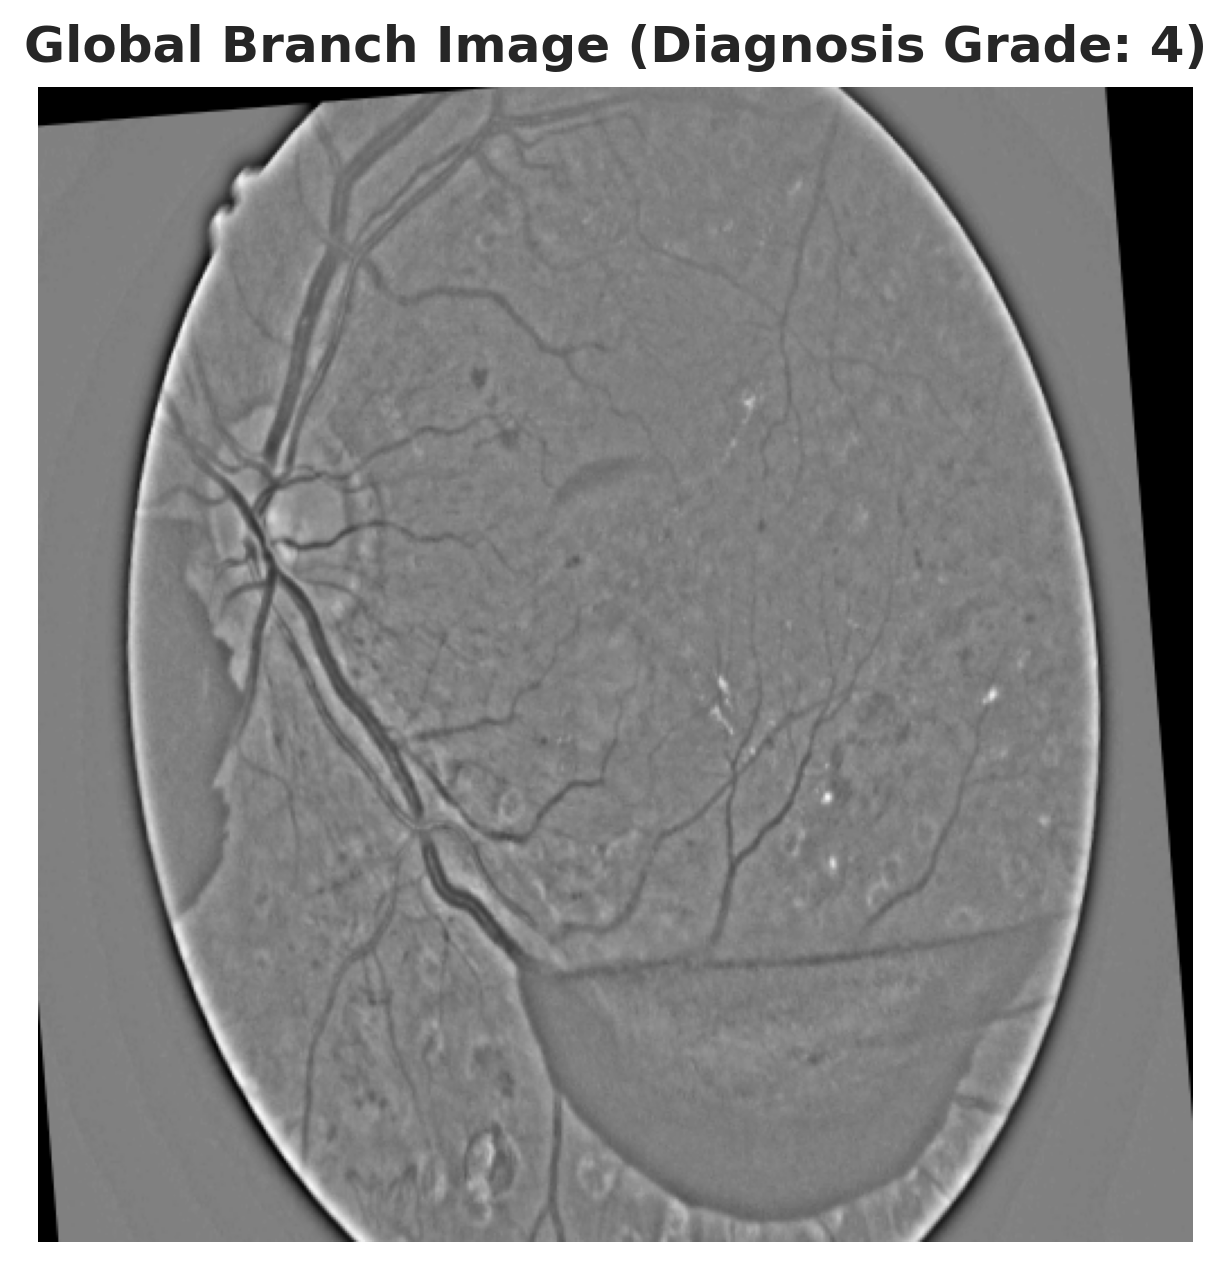

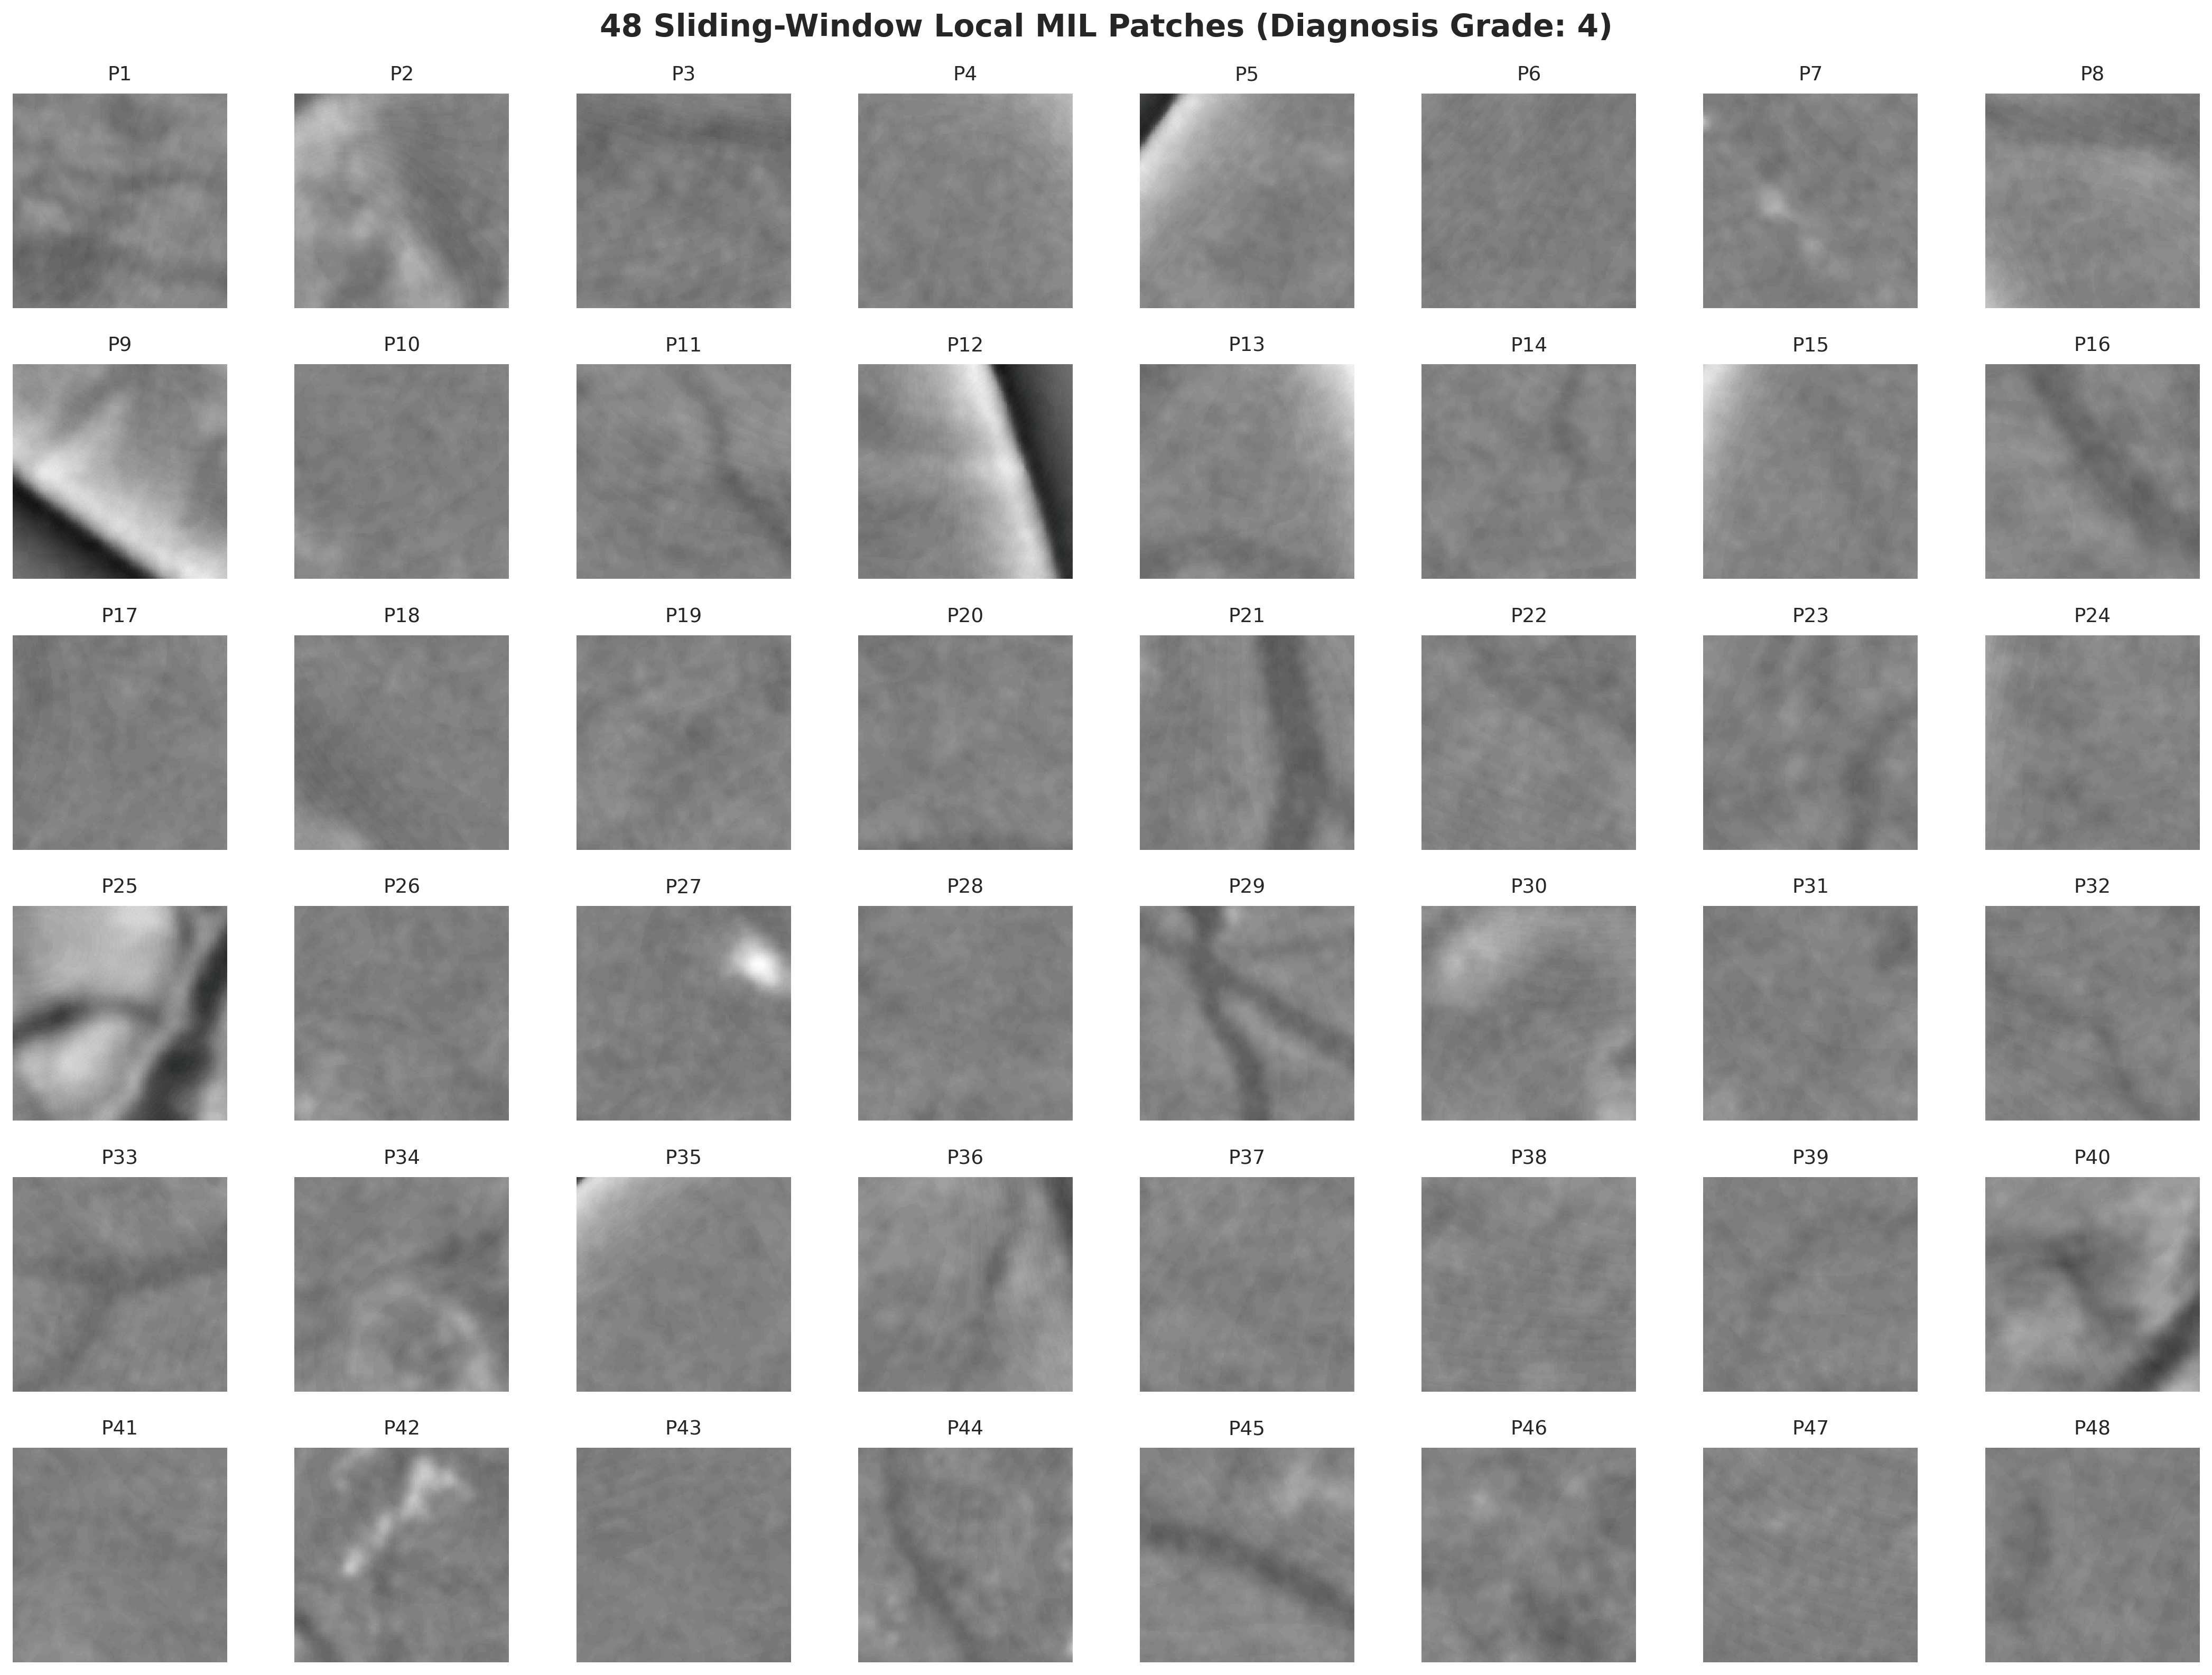

In [42]:
# ==============================================================================
# 1. FETCH A SINGLE MINI-BATCH FOR VISUAL VALIDATION
# ==============================================================================
for batch in train_loader:
    global_imgs = batch["global_img"]      # Tensor shape: [Batch, 3, 300, 300]
    local_patches = batch["local_patches"] # Tensor shape: [Batch, N, 3, 128, 128] (N=48 by default)
    labels = batch["label"]                # Tensor shape: [Batch]
    break
# ImageNet normalization statistics for inverse Z-score denormalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
# Select the first sample in the batch (index = 0)
img_idx = 0
label_val = labels[img_idx].item()
# ------------------------------------------------------------------------------
# 2. VISUALIZE GLOBAL CONTEXT IMAGE (Whole Fundus Stream)
# ------------------------------------------------------------------------------
global_img = global_imgs[img_idx].cpu() * std + mean
global_img = torch.clamp(global_img, 0, 1).permute(1, 2, 0).numpy()
plt.figure(figsize=(5, 5))
plt.imshow(global_img)
plt.title(f"Global Branch Image (Diagnosis Grade: {label_val})", fontsize=12, fontweight="bold")
plt.axis("off")
plt.show()
# ------------------------------------------------------------------------------
# 3. VISUALIZE LOCAL MIL PATCHES (Dynamic Sliding-Window Grid)
# ------------------------------------------------------------------------------
patches = local_patches[img_idx]  # Tensor shape: [N, 3, 128, 128]
num_patches = patches.shape[0]
# Dynamically calculate grid dimensions (e.g., 6 rows x 8 cols for N=48 patches)
ncols = 8 if num_patches >= 16 else 4
nrows = int(np.ceil(num_patches / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.8, nrows * 1.8))
fig.suptitle(f"{num_patches} Sliding-Window Local MIL Patches (Diagnosis Grade: {label_val})", fontsize=14, fontweight="bold")
axes_flat = np.array(axes).flatten()
for i in range(len(axes_flat)):
    if i < num_patches:
        # Denormalize patch back to RGB [0, 1] range
        patch = patches[i].cpu() * std + mean
        patch = torch.clamp(patch, 0, 1).permute(1, 2, 0).numpy()
        
        axes_flat[i].imshow(patch)
        axes_flat[i].set_title(f"P{i+1}", fontsize=9)
    # Hide unused subplot axes
    axes_flat[i].axis("off")
plt.tight_layout()
plt.show()

## 2.7 Class Distribution & Imbalance Breakdown

Analyzes the 5-class severity distribution (Grade 0: Normal to Grade 4: Proliferative DR) and reports on-the-fly augmentation parameters.


In [43]:
def visualize_dataset_statistics(
    csv_path: str, 
    save_path: str = None
):
    """
    Parses the metadata CSV directly (via 'diagnosis' column) and generates a bar chart
    displaying exact sample counts for each clinical grade (Grade 0 to Grade 4).
    """
    # 1. Load metadata from CSV file
    df = pd.read_csv(csv_path)
    counts_series = df['diagnosis'].value_counts()
    total_samples = len(df)

    # 2. Define clinical class labels and extract exact counts
    classes = [f"Grade {i}" for i in range(5)]
    raw_counts = [int(counts_series.get(i, 0)) for i in range(5)]

    # 3. Print structured summary table to console
    print("=" * 60)
    print("DATASET CLASS DISTRIBUTION SUMMARY")
    print("=" * 60)
    for i in range(5):
        print(f"  • Grade {i}: {raw_counts[i]:>6} images")
    print("-" * 60)
    print(f"Total Sample Count: {total_samples} images")
    print("=" * 60)

    # 4. Configure Matplotlib publication style
    if 'configure_publication_style' in globals():
        configure_publication_style()
    else:
        plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

    fig, ax = plt.subplots(figsize=(9.5, 5.5))

    # Academic color palette representing 5 DR severity stages
    bar_colors = ["#1f4e79", "#2b6cb0", "#319795", "#d69e2e", "#c53030"]

    # 5. Render single-bar distribution chart
    bars = ax.bar(
        classes,
        raw_counts,
        color=bar_colors,
        edgecolor="#2d3748",
        width=0.5,
        alpha=0.9,
        zorder=3
    )

    # 6. Annotate exact sample counts directly above each bar
    max_count = max(raw_counts) if raw_counts else 1
    for bar, count in zip(bars, raw_counts):
        height = bar.get_height()
        ax.annotate(
            f"{count}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="#2d3748"
        )

    # 7. Configure axis labels, title, and limits
    ax.set_xlabel("Diabetic Retinopathy Clinical Severity Grade", fontsize=11.5, fontweight="bold", labelpad=10)
    ax.set_ylabel("Sample Count", fontsize=11.5, fontweight="bold", labelpad=8)
    ax.set_title(f"Class Distribution Breakdown (Total: {total_samples} Images)", fontsize=13, fontweight="bold", pad=14)
    
    ax.set_ylim(0, max_count * 1.22)
    ax.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)

    # 8. Render dataset summary info box
    info_text = (
        f"Dataset Overview:\n"
        f"• Total Images: {total_samples}\n"
        f"• Classes: 5 Ordinal Grades (0–4)\n"
        f"• Processing: Dynamic On-the-fly"
    )
    props = dict(boxstyle="round,pad=0.45", facecolor="#f7fafc", edgecolor="#cbd5e0", lw=0.9, alpha=0.95)
    ax.text(
        0.98,
        0.95,
        info_text,
        transform=ax.transAxes,
        fontsize=9.5,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=props
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()

DATASET CLASS DISTRIBUTION SUMMARY
  • Grade 0:     50 images
  • Grade 1:     50 images
  • Grade 2:     50 images
  • Grade 3:     50 images
  • Grade 4:     50 images
------------------------------------------------------------
Total Sample Count: 250 images


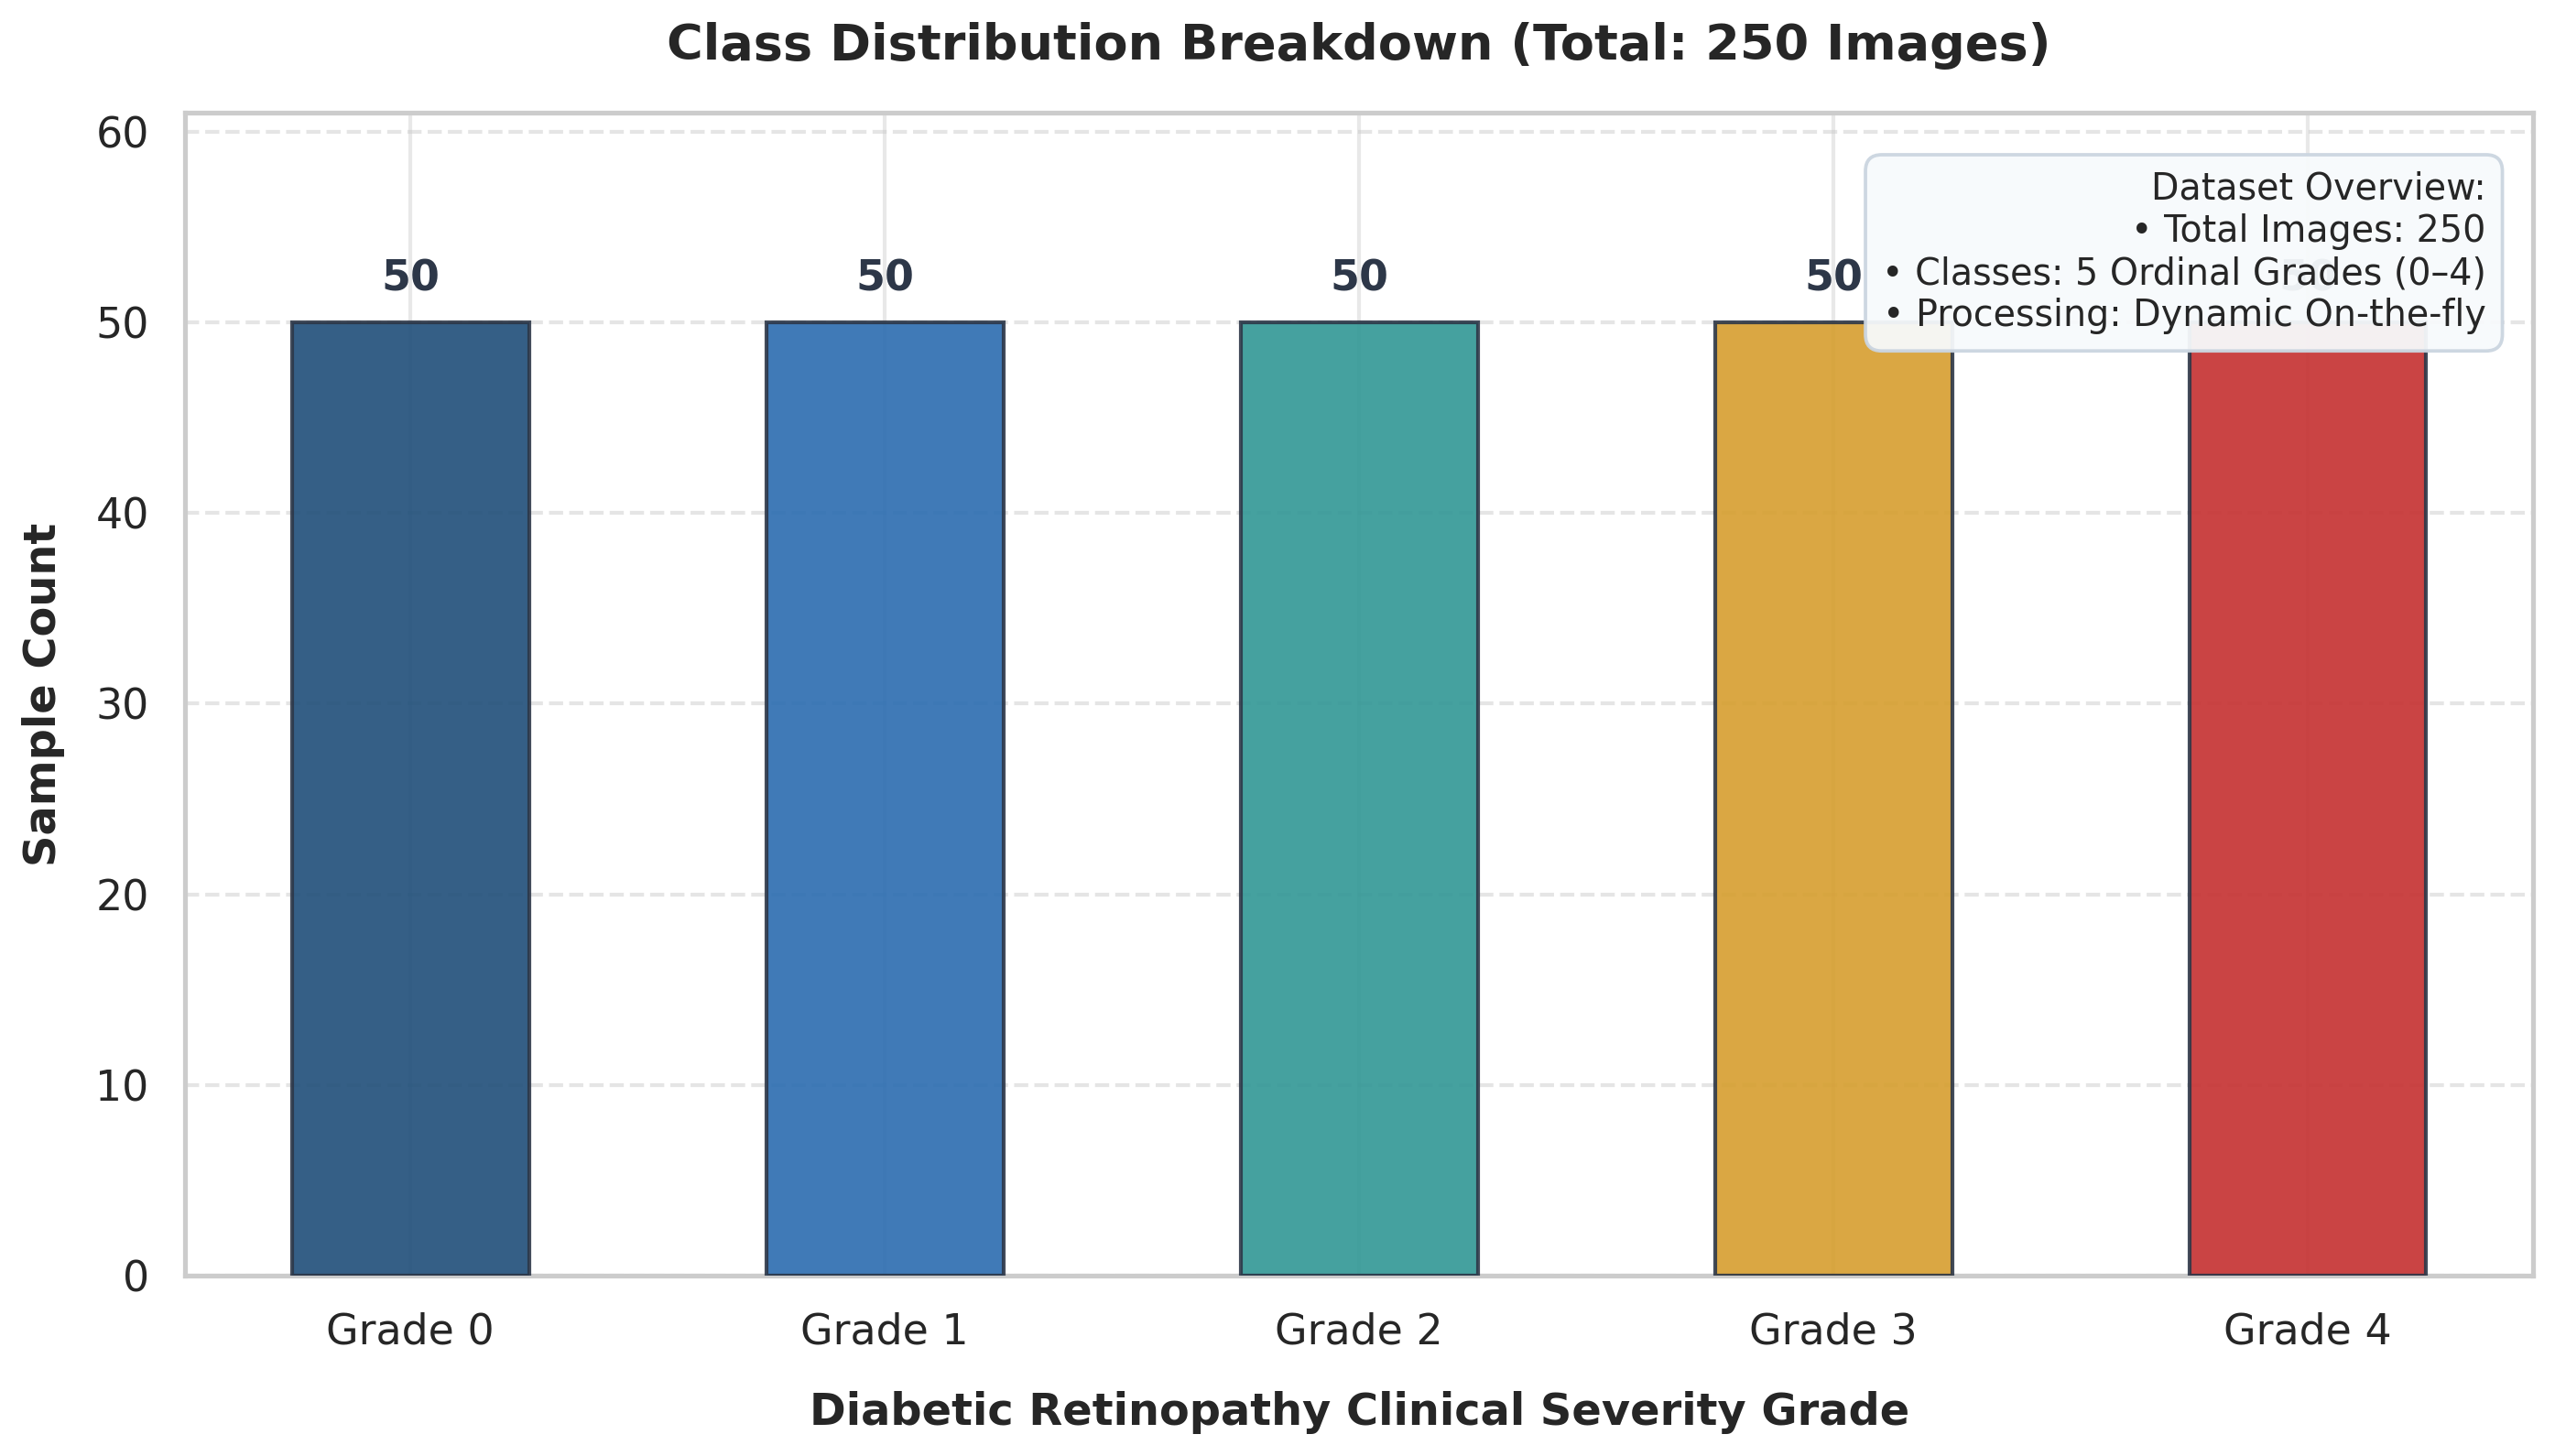

In [44]:
visualize_dataset_statistics(csv_path=csv_train_path)

# 3. Deep Neural Network Architecture & Ordinal Heads

The unified model consists of:
- **Global Context Branch**: `ResNet-50` backbone with `CBAM` dual-attention on Layer 4 $\rightarrow F_{\text{global}} \in \mathbb{R}^{2048}$.
- **Local MIL Branch**: Shared `EfficientNet-B0` feature extractor with 1D Max-Pooling across $K=16$ instances $\rightarrow F_{\text{local}} \in \mathbb{R}^{1280}$.
- **Fusion Projection Layer**: 2-stage MLP ($3328 \to 1024 \to 512$) with `Mish` activation, `BatchNorm1d`, and `LayerNorm`.
- **Ordinal Regression Heads**: 5 selectable output heads for systematic ablation benchmarking.


## 3.1 Convolutional Block Attention Module (CBAM)
Implements 1D Channel Attention ($M_c(F) = \sigma(\text{MLP}(\text{AvgPool}(F)) + \text{MLP}(\text{MaxPool}(F)))$) sequentially followed by 2D Spatial Attention ($M_s(F') = \sigma(f^{7\times 7}([\text{AvgPool}(F'); \text{MaxPool}(F')]))$).


In [45]:
class ChannelAttention(nn.Module):
    """
    Channel Attention Module for CBAM (Convolutional Block Attention Module).
    Exploits inter-channel relationships of features by combining spatial Average Pooling 
    and Max Pooling descriptors through a shared bottleneck MLP.
    """
    def __init__(self, in_channels: int, reduction_ratio: int = 16):
        super(ChannelAttention, self).__init__()
        # Spatial pooling descriptors: global context (AvgPool) & most salient features (MaxPool)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        
        # Shared bottleneck MLP using 1x1 convolutions (dimension reduction to preserve parameters)
        hidden_dim = max(8, in_channels // reduction_ratio)
        self.mlp = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_dim, in_channels, kernel_size=1, bias=False)
        )
        # Gating function producing channel-wise modulation weights in [0, 1]
        self.sigmoid = nn.Sigmoid()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Forward pass: aggregate spatial information and compute channel attention map Mc(F)
        avg_out = self.mlp(self.avg_pool(x))
        max_out = self.mlp(self.max_pool(x))
        out = avg_out + max_out
        return self.sigmoid(out) # Output shape: [Batch, in_channels, 1, 1]

In [46]:
class SpatialAttention(nn.Module):
    """
    Spatial Attention Module for CBAM (Convolutional Block Attention Module).
    Captures inter-spatial relationships of features by computing channel-wise Average
    and Max statistics, followed by a large receptive field 7x7 convolution.
    """
    def __init__(self, kernel_size: int = 7):
        super(SpatialAttention, self).__init__()
        # Same-padding ensures output spatial dimensions match input (H, W)
        padding = (kernel_size - 1) // 2
        # 2D Convolution mapping 2 aggregated channel descriptors -> 1 spatial attention map
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Channel-wise pooling along dimension 1 (channel axis) -> [Batch, 1, H, W] each
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        
        # Concatenate 2 descriptors along channel dimension -> [Batch, 2, H, W]
        combined = torch.cat([avg_out, max_out], dim=1)
        
        # Convolve and apply Sigmoid to generate 2D spatial attention weights Ms(F) in [0, 1]
        out = self.conv(combined)
        return self.sigmoid(out) # Output shape: [Batch, 1, H, W]

In [47]:
class CBAM(nn.Module):
    """
    Convolutional Block Attention Module (CBAM).
    Sequentially applies 1D Channel Attention followed by 2D Spatial Attention:
      1. Channel Refinement: F' = Mc(F) ⊗ F
      2. Spatial Refinement: F'' = Ms(F') ⊗ F'
    """
    def __init__(self, in_channels: int, reduction_ratio: int = 16, kernel_size: int = 7):
        super(CBAM, self).__init__()
        self.channel_att = ChannelAttention(in_channels, reduction_ratio=reduction_ratio)
        self.spatial_att = SpatialAttention(kernel_size=kernel_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Step 1: Channel-refined intermediate feature map (inter-channel weighting)
        x_channel = x * self.channel_att(x)
        
        # Step 2: Spatial-refined output feature map (inter-spatial location weighting)
        x_out = x_channel * self.spatial_att(x_channel)
        
        return x_out # Refined feature tensor of identical shape: [Batch, Channels, H, W]

## 3.2 Global Context Branch (ResNet-50 + CBAM)
Extracts macro-retinal structural patterns and 4-quadrant vascular geometry across the full fundus field ($300 \times 300 \to 2048\text{-dim}$).


In [48]:
class GlobalBranch(nn.Module):
    """
    Global Context Branch:
      - Input: Whole-fundus image tensor (Batch, 3, 300, 300)
      - Backbone: Pre-trained ResNet-50 (extracts deep macro-vascular and structural features)
      - Attention: Optional CBAM module applied after layer4 feature maps (2048 channels)
      - Pooling: Global Average Pooling (GAP) -> Flatten
      - Output: Global context feature vector F_Global of dimension 2048
    """
    def __init__(self, pretrained: bool = True, use_cbam: bool = True):
        super(GlobalBranch, self).__init__()
        # Load official Torchvision pre-trained ImageNet-1K weights
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        base_resnet = models.resnet50(weights=weights)
        
        # Stem and ResNet convolutional stages (Layer 1 to Layer 4)
        self.conv1 = base_resnet.conv1
        self.bn1 = base_resnet.bn1
        self.relu = base_resnet.relu
        self.maxpool = base_resnet.maxpool
        self.layer1 = base_resnet.layer1
        self.layer2 = base_resnet.layer2
        self.layer3 = base_resnet.layer3
        self.layer4 = base_resnet.layer4  # Final convolutional stage output: (B, 2048, H/32, W/32)
        
        self.use_cbam = use_cbam
        if use_cbam:
            # CBAM attention over 2048 feature channels with reduction ratio 16
            self.cbam = CBAM(in_channels=2048, reduction_ratio=16)
            
        # Global Average Pooling (GAP) to aggregate spatial dimensions
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.out_dim = 2048

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input tensor: (Batch, 3, 300, 300)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        
        # Multi-stage residual convolutions
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)  # Feature map: (Batch, 2048, H', W')
        
        # Apply Channel & Spatial Attention if enabled
        if self.use_cbam:
            x = self.cbam(x)
            
        # Spatial reduction via GAP & flatten to 1D embedding vector
        feat = self.gap(x)            # (Batch, 2048, 1, 1)
        feat = torch.flatten(feat, 1)  # (Batch, 2048)
        return feat

## 3.3 Local MIL Branch (EfficientNet-B0 + 1D Max-Pooling)
Applies vectorized $(B \times K)$ GPU feature extraction followed by Multiple Instance Learning 1D Max-Pooling: $F_{\text{local}} = \max_{k \in \{1..K\}} f_{\text{patch}}^{(k)}$, capturing the most severe micro-lesion signatures ($1280\text{-dim}$).

In [49]:
class GatedAttentionPool(nn.Module):
    """
    Gated Attention Mechanism for Multiple Instance Learning (Ilse et al., 2018).
    Learns instance-level attention weights a_k = softmax(w^T (tanh(V h_k) * sigm(U h_k))).
    Enables lesion counting and spatial density aggregation for Severe DR (Grade 3 - H2).
    """
    def __init__(self, in_features: int = 1280, hidden_dim: int = 128):
        super(GatedAttentionPool, self).__init__()
        self.attention_v = nn.Sequential(nn.Linear(in_features, hidden_dim), nn.Tanh())
        self.attention_u = nn.Sequential(nn.Linear(in_features, hidden_dim), nn.Sigmoid())
        self.attention_weights = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor, patch_mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        """
        x: [B, K, in_features]
        patch_mask: [B, K] (True = patch thật, False = patch padding)
        """
        a_v = self.attention_v(x)
        a_u = self.attention_u(x)
        a = self.attention_weights(a_v * a_u)  # [B, K, 1]
        
        # Nếu có patch_mask từ DataLoader (chế độ eval), gạt logits của padding về -inf
        if patch_mask is not None:
            mask_3d = patch_mask.unsqueeze(-1)  # [B, K, 1]
            a = a.masked_fill(~mask_3d, -1e4)
            
        a = torch.softmax(a, dim=1)  # [B, K, 1]
        weighted_out = torch.sum(x * a, dim=1)  # [B, in_features]
        return weighted_out


class LocalMILBranch(nn.Module):
    """
    Local Multi-Instance Learning (MIL) Branch with Dual Pooling:
      Input: (B, K, 3, 128, 128)
      Backbone: EfficientNet-B0 applied per patch
      Pooling: GAP per patch -> (B, K, 1280)
      Dual Aggregation:
        - 1D Max-Pooling (Captures extreme focal microaneurysms for Grade 1 - H1)
        - Gated Attention Pooling (Aggregates multi-lesion density for Grade 3 - H2)
      Output: F_Local feature vector of dimension 2560 (1280 + 1280) if use_dual_pooling else 1280
    """
    def __init__(self, pretrained: bool = True, use_dual_pooling: bool = True):
        super(LocalMILBranch, self).__init__()
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        base_effnet = models.efficientnet_b0(weights=weights)
        
        self.features = base_effnet.features
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.patch_dim = 1280
        self.use_dual_pooling = use_dual_pooling
        
        if use_dual_pooling:
            self.gated_pool = GatedAttentionPool(in_features=self.patch_dim, hidden_dim=128)
            self.out_dim = self.patch_dim * 2  # 2560
        else:
            self.out_dim = self.patch_dim      # 1280

    def forward(self, patches: torch.Tensor, patch_mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        B, K, C, H, W = patches.shape
        flat_patches = patches.view(B * K, C, H, W)
        patch_feats = self.features(flat_patches)
        patch_feats = self.gap(patch_feats)
        patch_feats = torch.flatten(patch_feats, 1)
        patch_feats = patch_feats.view(B, K, self.patch_dim)
        
        # 1. 1D Max-Pooling (Focal micro-lesions for H1)
        if patch_mask is not None:
            masked_feats = patch_feats.masked_fill(~patch_mask.unsqueeze(-1), -1e4)
            max_pooled, _ = torch.max(masked_feats, dim=1)
        else:
            max_pooled, _ = torch.max(patch_feats, dim=1)
        
        if self.use_dual_pooling:
            # 2. Gated Attention Pooling (Lesion counting for H2)
            att_pooled = self.gated_pool(patch_feats, patch_mask=patch_mask)
            f_local = torch.cat([max_pooled, att_pooled], dim=1)
        else:
            f_local = max_pooled
            
        return f_local



## 3.4 Multimodal Dual-Branch Latent Fusion
Concatenates global and local representations ($2048 + 1280 = 3328\text{-dim}$) and projects into a normalized $512\text{-dim}$ latent space $\mathbf{z}$.

In [50]:
class DualBranchMILModel(nn.Module):
    """
    Unified Dual-Branch Multi-Scale Deep Learning Network:
      Combines Global Context (ResNet-50 + CBAM) and Local Micro-Lesions (MIL EfficientNet-B0 Dual Pooling).
      Outputs a compact, fused latent embedding D_latent = 512 for downstream classification/regression heads.
    """
    def __init__(
        self,
        pretrained: bool = True,
        use_cbam: bool = True,
        use_dual_pooling: bool = True,
        fusion_dim: int = 512,
        dropout_rate: float = 0.3
    ):
        super(DualBranchMILModel, self).__init__()
        
        self.global_branch = GlobalBranch(pretrained=pretrained, use_cbam=use_cbam)
        self.local_mil_branch = LocalMILBranch(pretrained=pretrained, use_dual_pooling=use_dual_pooling)
        
        combined_dim = self.global_branch.out_dim + self.local_mil_branch.out_dim  # 2048 + 2560 = 4608
        
        # Robust Fusion Projection Module (using LayerNorm to eliminate batch size 1 crash)
        self.fusion_layer = nn.Sequential(
            nn.Linear(combined_dim, fusion_dim),
            nn.LayerNorm(fusion_dim),
            nn.Mish(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(fusion_dim, fusion_dim),
            nn.LayerNorm(fusion_dim)
        )
        self.latent_dim = fusion_dim

    def forward(
        self, 
        global_img: torch.Tensor, 
        local_patches: torch.Tensor, 
        patch_mask: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        f_global = self.global_branch(global_img)
        f_local = self.local_mil_branch(local_patches, patch_mask=patch_mask)
        f_fused = torch.cat([f_global, f_local], dim=1)
        latent = self.fusion_layer(f_fused)
        return latent

## 3.5 Output Head Ablation Suite & Loss Formulations
We implement 5 distinct classification and ordinal regression heads to systematically verify Hypothesis H3:

### 3.5.1 Differentiable Continuous Quadratic Weighted Kappa (QWK) Loss
Approximates Cohen's Kappa via soft observed ($O = P^T Y$) and expected ($E = \text{hist}_{\text{pred}}^T \cdot \text{hist}_{\text{true}}$) confusion matrices weighted by $W_{ij} = \frac{(i - j)^2}{(C - 1)^2}$.

In [51]:
class ContinuousQWKLoss(nn.Module):
    """
    Differentiable approximation of Quadratic Weighted Kappa (QWK) Loss for PyTorch.
    Computes continuous soft confusion matrices to directly optimize clinical ordinal agreement:
      QWK = 1 - (sum(W * O) / sum(W * E))
      Loss = sum(W * O) / (sum(W * E) + eps)
    """
    def __init__(self, num_classes: int = 5, eps: float = 1e-7):
        super(ContinuousQWKLoss, self).__init__()
        self.num_classes = num_classes
        self.eps = eps
        
        # Quadratic penalty matrix: W_ij = (i - j)^2 / (C - 1)^2
        # Penalizes distant classification errors quadratically (e.g. Grade 0 vs 4 vs Grade 0 vs 1)
        w = torch.zeros((num_classes, num_classes), dtype=torch.float32)
        for i in range(num_classes):
            for j in range(num_classes):
                w[i, j] = ((i - j) ** 2) / ((num_classes - 1) ** 2)
        # Register W as non-trainable persistent buffer
        self.register_buffer("W", w)

    def forward(self, pred_probs: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        """
        Forward computation of differentiable QWK loss.

        Args:
            pred_probs: Continuous class probabilities (Batch, num_classes) summing to 1.
            targets: Ground truth integer class indices (Batch,) or one-hot targets (Batch, num_classes).
            
        Returns:
            torch.Tensor: Scalar differentiable QWK loss value.
        """
        device = pred_probs.device
        N = pred_probs.size(0)
        if N == 0:
            return torch.tensor(0.0, device=device, requires_grad=True)
            
        # Format targets as one-hot continuous probability distributions
        if targets.ndim == 1:
            y_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()
        else:
            y_one_hot = targets.float()
            
        # Numerical normalization ensuring valid probability simplex
        pred_probs = pred_probs / (pred_probs.sum(dim=1, keepdim=True) + self.eps)
        
        # Soft observed confusion matrix: O = (P^T * Y) / N
        O = torch.matmul(pred_probs.t(), y_one_hot)  # (C, C)
        O = O / (N + self.eps)
        
        # Expected confusion matrix under chance agreement: E = (hist_pred^T * hist_true)
        hist_pred = pred_probs.sum(dim=0, keepdim=True) / (N + self.eps)  # Marginal predicted distribution (1, C)
        hist_true = y_one_hot.sum(dim=0, keepdim=True) / (N + self.eps)   # Marginal true label distribution (1, C)
        E = torch.matmul(hist_pred.t(), hist_true)                        # Outer product (C, C)
        
        # Compute quadratic-weighted numerator (observed error) and denominator (expected error)
        W = self.W.to(device)
        num = torch.sum(W * O)
        den = torch.sum(W * E) + self.eps
        
        # Ratio minimization: minimizing (num / den) directly maximizes Cohen's Quadratic Weighted Kappa
        qwk_loss = num / den
        return qwk_loss

### 3.5.2 Output Head 1: Softmax + Categorical Cross-Entropy (Nominal Baseline)
Standard unconstrained multi-class linear classification treating disease grades as independent nominal categories.

In [52]:
class SoftmaxCEHead(nn.Module):
    """
    Output Head 1: Standard Categorical Classification Baseline.
      - Architecture: Linear(latent_dim, num_classes) -> Softmax.
      - Loss: Categorical Cross-Entropy (treats disease stages as mutually independent nominal classes).
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(SoftmaxCEHead, self).__init__()
        # Standard fully-connected projection layer
        self.fc = nn.Linear(in_features, num_classes)
        self.num_classes = num_classes

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Computes unconstrained categorical logits, probabilities, and class predictions.
        """
        logits = self.fc(x)                 # Unnormalized raw logits: (Batch, num_classes)
        probs = F.softmax(logits, dim=1)    # Normalized categorical distribution: (Batch, num_classes)
        preds = torch.argmax(probs, dim=1)  # Predicted discrete class index: (Batch,)
        return {"logits": logits, "probs": probs, "preds": preds}

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Computes Standard Categorical Cross-Entropy Loss with optional class weighting.
        """
        logits = outputs["logits"]
        return F.cross_entropy(logits, targets, weight=class_weights)

### 3.5.3 Output Head 2: Softmax + Hybrid Continuous QWK Loss
Combines point-wise Cross-Entropy with global QWK loss: $\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{CE}} + \lambda \mathcal{L}_{\text{QWK}}$.

In [53]:
class SoftmaxQWKHead(nn.Module):
    """
    Output Head 2: Softmax Classification Head with Hybrid Multitask Loss.
      - Architecture: Linear(latent_dim, num_classes) -> Softmax.
      - Loss: Total_Loss = Cross_Entropy + lambda * Continuous_QWK_Loss.
      - Inference: Computes expected continuous severity score via probability expectation:
                   E[y] = sum_{k=0}^{C-1} (k * P(y=k)), rounded to nearest integer grade.
    """
    def __init__(
        self,
        in_features: int = 512,
        num_classes: int = 5,
        qwk_weight: float = 1.0
    ):
        super(SoftmaxQWKHead, self).__init__()
        self.fc = nn.Linear(in_features, num_classes)
        self.num_classes = num_classes
        self.qwk_weight = qwk_weight
        # Integrated differentiable QWK loss module
        self.qwk_loss = ContinuousQWKLoss(num_classes=num_classes)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Computes categorical probabilities and expected continuous severity values.
        """
        logits = self.fc(x)
        probs = F.softmax(logits, dim=1)
        
        # Expected continuous severity score (weighted sum of class indices by probability mass)
        continuous_pred = torch.sum(probs * torch.arange(self.num_classes, device=x.device), dim=1)
        # Discrete ordinal prediction via rounding and boundary clamping [0, num_classes - 1]
        preds = torch.round(continuous_pred).clamp(0, self.num_classes - 1).long()
        
        return {
            "logits": logits,
            "probs": probs,
            "preds": preds,
            "continuous_preds": continuous_pred
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Computes composite multitask loss combining point-wise CE and global QWK optimization.
        """
        logits = outputs["logits"]
        probs = outputs["probs"]
        
        # 1. Standard categorical cross-entropy loss
        ce_loss = F.cross_entropy(logits, targets, weight=class_weights)
        
        # 2. Differentiable quadratic weighted kappa penalty
        qwk = self.qwk_loss(probs, targets)
        
        # 3. Hybrid loss combination
        total_loss = ce_loss + self.qwk_weight * qwk
        return total_loss

### 3.5.4 Output Head 3: Consistent Rank Logits (CORAL)
Parallel hyperplane ordinal regression with shared weight vector $W$ and independent threshold biases $b_k$: $P(y > k) = \sigma(W^T x + b_k)$.

In [54]:
class CORALHead(nn.Module):
    """
    Output Head 3: Consistent Rank Logits (CORAL) for Ordinal Regression.
    Features:
      - Shared weight vector W across all rank threshold sub-tasks (ensures parallel hyperplanes).
      - Independent learnable threshold biases b_1, b_2, ..., b_{K-1}.
      - Cumulative probability formulation: P(y > k) = sigmoid(W^T x + b_k).
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(CORALHead, self).__init__()
        self.num_classes = num_classes
        self.num_thresholds = num_classes - 1  # (C - 1) = 4 binary ordinal thresholds
        
        # Shared 1D linear projection (weight vector W without bias)
        self.linear = nn.Linear(in_features, 1, bias=False)
        # Independent threshold biases b_k
        self.biases = nn.Parameter(torch.zeros(self.num_thresholds))
        
        # Initialize biases to strictly increasing values to guide monotonic learning
        with torch.no_grad():
            self.biases.copy_(torch.linspace(-2.0, 2.0, self.num_thresholds))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Computes cumulative rank logits, cumulative threshold probabilities, and discrete class predictions.
        """
        base_logit = self.linear(x)  # Shared projection: (Batch, 1)
        
        # Binary rank logits: z_k = W^T x + b_k -> (Batch, num_thresholds)
        rank_logits = base_logit + self.biases  # (Batch, 4)
        rank_probs = torch.sigmoid(rank_logits)  # Cumulative probabilities P(y > k) in [0, 1]
        
        # Predict discrete ordinal grade by counting exceeded thresholds (P(y > k) > 0.5)
        preds = torch.sum(rank_probs > 0.5, dim=1).long()  # Discrete grade in [0..4]
        
        # Reconstruct categorical class probabilities: P(y = k) = P(y > k-1) - P(y > k)
        B = x.size(0)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = 1.0 - rank_probs[:, 0]
        for k in range(1, self.num_thresholds):
            probs[:, k] = F.relu(rank_probs[:, k - 1] - rank_probs[:, k])
        probs[:, -1] = rank_probs[:, -1]
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)  # Simplex normalization
        
        return {
            "rank_logits": rank_logits, 
            "rank_probs": rank_probs, 
            "probs": probs, 
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Computes multi-task Binary Cross-Entropy loss across all binary rank threshold indicators.
        """
        rank_logits = outputs["rank_logits"]  # (Batch, 4)
        device = targets.device
        B = targets.size(0)
        
        # Deconstruct integer target into binary rank labels: binary_targets[i, k] = 1 if target > k else 0
        binary_targets = torch.zeros(B, self.num_thresholds, device=device)
        for k in range(self.num_thresholds):
            binary_targets[:, k] = (targets > k).float()
            
        # Cumulative ordinal Binary Cross-Entropy with Logits
        bce_loss = F.binary_cross_entropy_with_logits(rank_logits, binary_targets, reduction="mean")
        return bce_loss


### 3.5.5 Output Head 4: Conditional Ordinal Regression Neural Network (CORN)
Models forward conditional transition probabilities: $P(y > k \mid y \ge k) = \sigma(g(x)_k)$ and accumulates probabilities via chain rule multiplication.

In [55]:
class CORNHead(nn.Module):
    """
    Output Head 4: Conditional Ordinal Regression Neural Network (CORN).
    Features:
      - Models conditional forward transition probabilities: P(y > k | y >= k) = sigmoid(g(x)_k).
      - Applies chain rule multiplication: P(y > k) = prod_{j=0}^k P(y > j | y >= j).
      - Mathematically guarantees strictly non-increasing cumulative probabilities without threshold crossing.
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(CORNHead, self).__init__()
        self.num_classes = num_classes
        self.num_thresholds = num_classes - 1  # 4 conditional transition sub-tasks
        # Independent linear projection for all conditional heads
        self.fc = nn.Linear(in_features, self.num_thresholds)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        """
        Computes conditional transition probabilities, cumulative probabilities via cumulative product,
        and discrete ordinal class predictions.
        """
        cond_logits = self.fc(x)                 # Conditional logits: (Batch, num_thresholds)
        cond_probs = torch.sigmoid(cond_logits)  # Conditional probabilities P(y > k | y >= k) in [0, 1]
        
        # Cumulative probability chain rule: P(y > k) = prod_{j=0}^k P(y > j | y >= j)
        cum_probs = torch.cumprod(cond_probs, dim=1)  # Guaranteed monotonic: (Batch, 4)
        
        # Predict discrete grade by counting satisfied cumulative thresholds
        preds = torch.sum(cum_probs > 0.5, dim=1).long()  # Output grade in [0..4]
        
        # Reconstruct interval categorical probabilities: P(y = k) = P(y > k-1) - P(y > k)
        B = x.size(0)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = 1.0 - cum_probs[:, 0]
        for k in range(1, self.num_thresholds):
            probs[:, k] = F.relu(cum_probs[:, k - 1] - cum_probs[:, k])
        probs[:, -1] = cum_probs[:, -1]
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)  # Simplex normalization
        
        return {
            "cond_logits": cond_logits,
            "cond_probs": cond_probs,
            "cum_probs": cum_probs,
            "probs": probs,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Computes masked Binary Cross-Entropy loss conditioned on each sub-task's eligible sample subset.
        """
        cond_logits = outputs["cond_logits"]  # (Batch, 4)
        B = targets.size(0)
        device = targets.device
        
        loss = 0.0
        valid_tasks = 0
        
        for k in range(self.num_thresholds):
            # Conditional subset masking: only instances satisfying (y >= k) participate in training head k
            mask = (targets >= k)
            if mask.sum() > 0:
                subset_logits = cond_logits[mask, k]
                subset_targets = (targets[mask] > k).float()
                task_loss = F.binary_cross_entropy_with_logits(subset_logits, subset_targets)
                loss += task_loss
                valid_tasks += 1
                
        return loss / max(1, valid_tasks)


#### 3.5.6 Output Head 5: Cumulative Link Model + QWK (Champion Architecture)
Maps latent features to a single scalar severity score $s(x) = W^T x$ evaluated against strictly monotonic cutpoints ($\theta_1 < \theta_2 < \theta_3 < \theta_4$) via the complementary log-log ($\text{clog-log}$) link function $F(z) = 1 - \exp(-\exp(z))$.

In [56]:
# ==============================================================================
# SECTION 3.5: CUMULATIVE LINK MODEL (CLM_QWK) OUTPUT HEAD
# ==============================================================================
class CumulativeLinkModelQWKHead(nn.Module):
    """
    Champion Output Architecture: Cumulative Link Model (CLM) with Complementary Log-Log (clog-log)
    Link Function & Hybrid Continuous QWK Loss with Linear Warmup.
    
    Mathematical Formulation:
      - Latent Severity Score: s(x) = W^T x (scalar continuous representation)
      - Strictly Monotonic Cutpoints: theta_1 < theta_2 < theta_3 < theta_4 parameterized
        via softplus increments: theta_k = theta_{k-1} + softplus(alpha_k) + 1e-4
      - Complementary Log-Log (clog-log) link: F(z) = 1 - exp(-exp(z))
      - Cumulative Probability: P(Y <= k) = 1 - exp(-exp(theta_k - s(x)))
      - Rank Probability: P(Y > k) = 1 - P(Y <= k)
      - Interval Probability: P(Y = k) = P(Y <= k) - P(Y <= k-1)
      - Loss: Negative Log-Likelihood (NLL) + lambda * Continuous_QWK_Loss
    """
    def __init__(
        self,
        in_features: int = 512,
        num_classes: int = 5,
        qwk_weight: float = 1.2
    ):
        super(CumulativeLinkModelQWKHead, self).__init__()
        self.num_classes = num_classes
        self.num_cutpoints = num_classes - 1  # 4 cutpoints for 5 grades
        self.target_qwk_weight = qwk_weight
        self.current_qwk_weight = 0.0  # Warmup starts at 0.0
        
        self.score_fc = nn.Linear(in_features, 1, bias=False)
        self.first_cutpoint = nn.Parameter(torch.tensor(-1.5))
        self.cutpoint_increments = nn.Parameter(torch.ones(self.num_cutpoints - 1) * -0.5)
        
        self.qwk_loss = ContinuousQWKLoss(num_classes=num_classes)

    def set_qwk_weight(self, weight: float):
        """Hàm cập nhật trọng số lambda động cho QWK loss trong quá trình warm-up"""
        self.current_qwk_weight = weight

    def _get_monotonic_cutpoints(self) -> torch.Tensor:
        increments = F.softplus(self.cutpoint_increments) + 1e-4
        cutpoints = [self.first_cutpoint]
        for i in range(len(increments)):
            cutpoints.append(cutpoints[-1] + increments[i])
        return torch.stack(cutpoints)

    def _cloglog_cdf(self, z: torch.Tensor) -> torch.Tensor:
        z_clamped = torch.clamp(z, min=-10.0, max=4.0)
        return 1.0 - torch.exp(-torch.exp(z_clamped))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        B = x.size(0)
        severity_score = self.score_fc(x).squeeze(1)
        cutpoints = self._get_monotonic_cutpoints()
        
        z = cutpoints.unsqueeze(0) - severity_score.unsqueeze(1)
        cum_probs = self._cloglog_cdf(z)
        rank_probs = 1.0 - cum_probs
        
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = cum_probs[:, 0]
        for k in range(1, self.num_cutpoints):
            probs[:, k] = F.relu(cum_probs[:, k] - cum_probs[:, k - 1])
        probs[:, -1] = F.relu(1.0 - cum_probs[:, -1])
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)
        
        class_indices = torch.arange(self.num_classes, device=x.device, dtype=torch.float32)
        expected_grade = torch.sum(probs * class_indices, dim=1)
        preds = torch.round(expected_grade).clamp(0, self.num_classes - 1).long()
        
        return {
            "severity_score": severity_score,
            "latent_score": severity_score,  # Giữ đồng thời để tương thích mọi hàm trích xuất
            "cutpoints": cutpoints,
            "thetas": cutpoints,             # Alias cho các hàm vẽ Section 6.2
            "cum_probs": cum_probs,
            "rank_probs": rank_probs,
            "probs": probs,
            "expected_grade": expected_grade,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        probs = outputs["probs"]
        B = targets.size(0)
        
        eps = 1e-7
        target_probs = probs[torch.arange(B, device=targets.device), targets]
        nll_loss = -torch.log(torch.clamp(target_probs, min=eps))
        
        if class_weights is not None:
            weights_per_sample = class_weights[targets]
            nll_loss = (nll_loss * weights_per_sample).mean()
        else:
            nll_loss = nll_loss.mean()
            
        qwk = self.qwk_loss(probs, targets)
        total_loss = nll_loss + self.current_qwk_weight * qwk
        return total_loss

## 3.6 End-to-End Model Wrapper & Offline Feature Caching

In [57]:
class DRFullModel(nn.Module):
    """
    End-to-End Deep Learning Architecture integrating the DualBranchMILModel backbone
    with any of the 5 selectable Ordinal/Nominal Classification Heads for ablation benchmarking.
    """
    def __init__(
        self,
        backbone: nn.Module,
        head_type: str = "CLM_QWK",
        num_classes: int = 5,
        qwk_weight: float = 1.2
    ):
        super(DRFullModel, self).__init__()
        self.backbone = backbone
        self.head_type = head_type
        self.num_classes = num_classes
        # Dynamically retrieve latent embedding dimension (default: 512)
        latent_dim = getattr(backbone, "latent_dim", 512)
        
        # Factory dispatch to instantiate the designated classification/ordinal head
        head_key = head_type.upper()
        if head_key in ["SOFTMAX_CE", "CE"]:
            self.head = SoftmaxCEHead(in_features=latent_dim, num_classes=num_classes)
        elif head_key in ["SOFTMAX_QWK", "QWK"]:
            self.head = SoftmaxQWKHead(in_features=latent_dim, num_classes=num_classes, qwk_weight=qwk_weight)
        elif head_key in ["CORAL"]:
            self.head = CORALHead(in_features=latent_dim, num_classes=num_classes)
        elif head_key in ["CORN"]:
            self.head = CORNHead(in_features=latent_dim, num_classes=num_classes)
        elif head_key in ["CLM_QWK", "CLM", "CHAMPION"]:
            self.head = CumulativeLinkModelQWKHead(in_features=latent_dim, num_classes=num_classes, qwk_weight=qwk_weight)
        else:
            raise ValueError(f"Unknown head_type: '{head_type}'. Choose from Softmax_CE, Softmax_QWK, CORAL, CORN, CLM_QWK.")

    def forward(self, global_img: torch.Tensor, local_patches: torch.Tensor, patch_mask: Optional[torch.Tensor] = None) -> Dict[str, torch.Tensor]:
        """
        Unified forward pass: passes multi-scale inputs through backbone, then through active head.
        """
        latent = self.backbone(global_img, local_patches, patch_mask=patch_mask)  # (Batch, 512)
        outputs = self.head(latent)                        # Compute predictions from selected head
        outputs["latent"] = latent                         # Preserve latent representation for feature analysis/XAI
        return outputs

    def compute_loss(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Delegates loss calculation directly to the active head's specialized loss function.
        """
        return self.head.loss_fn(outputs, targets, class_weights=class_weights)


## 3.7 Unified Model Factory Builder

In [58]:
def build_model(
    head_type: str = "CLM_QWK",
    pretrained: bool = True,
    use_cbam: bool = True,
    fusion_dim: int = 512,
    num_classes: int = 5,
    qwk_weight: float = 1.2
) -> DRFullModel:
    """
    Factory function to construct the complete multi-scale Diabetic Retinopathy pipeline model
    configured with the designated classification or ordinal regression output head.
    
    Args:
        head_type: Selected output head architecture:
                   ['Softmax_CE', 'Softmax_QWK', 'CORAL', 'CORN', 'CLM_QWK'].
        pretrained: Whether convolutional backbones load pre-trained ImageNet weights.
        use_cbam: Whether to apply CBAM Channel & Spatial Attention on ResNet-50.
        fusion_dim: Dimension of the latent multi-scale fused embedding (default: 512).
        num_classes: Number of ordinal severity stages (default: 5 grades, 0 to 4).
        qwk_weight: Loss weight multiplier lambda for the differentiable continuous QWK term.
        
    Returns:
        DRFullModel: Fully assembled and end-to-end differentiable PyTorch model.
    """
    # 1. Instantiate multi-scale dual-branch backbone (Global ResNet50-CBAM + Local MIL EfficientNet-B0)
    backbone = DualBranchMILModel(
        pretrained=pretrained,
        use_cbam=use_cbam,
        fusion_dim=fusion_dim
    )
    
    # 2. Wrap backbone with the designated ordinal/nominal classification head
    model = DRFullModel(
        backbone=backbone,
        head_type=head_type,
        num_classes=num_classes,
        qwk_weight=qwk_weight
    )
    return model

# 4. Training Engine & Clinical Evaluation Metrics

This section establishes a standardized medical evaluation protocol (Quadratic Weighted Kappa, Within-1-Grade accuracy, Referable DR sensitivity/specificity at fixed 80/90/95% operating points, and rank monotonicity violation checks) alongside an automated PyTorch mixed-precision training engine.

### 4.1 Comprehensive Medical & Statistical Metric Suite
Implements clinical screening metrics adhering to tele-ophthalmology guidelines:
- **QWK**: Quadratic penalty agreement score.
- **Within-1-Grade Accuracy**: Clinical tolerance proportion ($|y_{\text{true}} - y_{\text{pred}}| \le 1$).
- **Referable DR Sensitivity/Specificity**: Evaluated at clinical thresholds ($\text{Grade} \ge 2$) and target specificities ($80\%, 90\%, 95\%$) via continuous ROC integration.
- **Monotonicity Violation Rate**: Detects inverted cumulative probability sequences ($P(Y \le k) > P(Y \le k+1)$).

In [59]:
def calculate_referable_sensitivity_at_specificity(
    y_true: np.ndarray,
    referable_probs: np.ndarray,
    target_specificities: Tuple[float, ...] = (0.80, 0.90, 0.95),
) -> Dict[str, float]:
    """
    Computes clinical Sensitivity at fixed Specificity operating points for Referable DR screening
    (binary classification threshold: Grade >= 2, Moderate/Severe/PDR vs. No DR/Mild).
    Constructs the complete Receiver Operating Characteristic (ROC) curve using continuous predicted
    scores P(Y >= 2) and identifies optimal operating thresholds meeting target specificity levels.

    Args:
        y_true: Ground-truth integer labels [0..4] of shape (N,).
        referable_probs: Continuous predicted probability scores P(Y >= 2) of shape (N,).
        target_specificities: Fixed target clinical specificity thresholds (e.g., 0.80, 0.90, 0.95).

    Returns:
        Dict containing 'Referable_AUC' and 'Ref_Sensitivity_at_SpecXX' for each target specificity.
    """
    # Binary conversion: 1 for Referable DR (Grade >= 2), 0 for Non-referable (Grade 0 or 1)
    y_true_ref = (np.asarray(y_true, dtype=int) >= 2).astype(int)
    referable_probs = np.asarray(referable_probs, dtype=float)

    results: Dict[str, float] = {}

    n_pos = int(y_true_ref.sum())
    n_neg = int((1 - y_true_ref).sum())
    if n_pos == 0 or n_neg == 0:
        # Edge case: insufficient binary class representation (occurs in small test batches)
        # Returns NaN to prevent biased or misleading metric calculations
        results["Referable_AUC"] = float("nan")
        for spec in target_specificities:
            results[f"Ref_Sensitivity_at_Spec{int(round(spec * 100))}"] = float("nan")
        return results

    # Construct empirical ROC curve and compute Area Under Curve (AUC-ROC)
    fpr, tpr, _ = roc_curve(y_true_ref, referable_probs)
    results["Referable_AUC"] = float(auc(fpr, tpr))
    specificity = 1.0 - fpr

    # Evaluate maximum achievable sensitivity at each operating specificity bound
    for spec in target_specificities:
        valid_idx = np.where(specificity >= spec)[0]
        if len(valid_idx) == 0:
            # Model cannot operate at or above the requested specificity bound
            sens_at_spec = 0.0
        else:
            # Due to monotonic properties of ROC curves, maximum TPR corresponds to optimal operating threshold
            sens_at_spec = float(tpr[valid_idx].max())
        results[f"Ref_Sensitivity_at_Spec{int(round(spec * 100))}"] = sens_at_spec

    return results

In [60]:
def calculate_dr_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    num_classes: int = 5,
    y_probs: Optional[np.ndarray] = None,
    target_specificities: Tuple[float, ...] = (0.80, 0.90, 0.95)
) -> Dict[str, Any]:
    """
    Computes rigorous clinical and statistical evaluation metrics for 5-grade Diabetic Retinopathy classification:
      1. Quadratic Weighted Kappa (QWK): Primary statistical agreement metric.
      2. Multi-class Accuracy.
      3. Within-1-Grade Accuracy: Clinical tolerance metric (|y_true - y_pred| <= 1).
      4. Confusion Matrix and Per-Grade Recall (Sensitivity for Grade 0 to Grade 4).
      5. Referable DR (Grade >= 2) Sensitivity and Specificity at default and fixed operating points.

    Args:
        y_true: Array of ground-truth integer labels [0..4].
        y_pred: Array of predicted discrete integer labels [0..4].
        num_classes: Number of ordinal severity classes (default: 5).
        y_probs: Optional continuous class probability distribution array (N, 5).
        target_specificities: Tuple of fixed specificity thresholds for ROC operating point evaluation.
        
    Returns:
        Dict[str, Any]: Comprehensive clinical and statistical evaluation metrics dictionary.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    
    # 1. Quadratic Weighted Kappa (QWK) - penalizes distance quadratically
    qwk = float(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
    if np.isnan(qwk):
        qwk = 0.0
        
    # 2. Overall multi-class exact match accuracy
    acc = float(accuracy_score(y_true, y_pred))
    
    # 3. Within-1-Grade Accuracy: proportion of predictions within ±1 stage of clinical ground truth
    within_1 = float(np.mean(np.abs(y_true - y_pred) <= 1))
    
    # 4. Multi-class Confusion Matrix & Individual Per-Grade Sensitivities
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    per_grade_recall = {}
    for c in range(num_classes):
        denom = cm[c, :].sum()
        recall = float(cm[c, c] / denom) if denom > 0 else 0.0
        per_grade_recall[f"Recall_Grade_{c}"] = recall
        
    # 5. Binary Referable DR Analysis (Non-Referable: 0,1 vs. Referable: 2,3,4)
    # Gold-standard referral threshold in tele-ophthalmology screening guidelines
    y_true_ref = (y_true >= 2).astype(int)
    y_pred_ref = (y_pred >= 2).astype(int)
    
    cm_ref = confusion_matrix(y_true_ref, y_pred_ref, labels=[0, 1])
    tn, fp, fn, tp = cm_ref.ravel() if cm_ref.size == 4 else (0, 0, 0, 0)
    
    ref_sensitivity = float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0
    ref_specificity = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0
    
    result: Dict[str, Any] = {
        "QWK": qwk,
        "Accuracy": acc,
        "Within_1_Grade_Acc": within_1,
        "Referable_Sensitivity": ref_sensitivity,
        "Referable_Specificity": ref_specificity,
        "Confusion_Matrix": cm.tolist(),
        **per_grade_recall
    }

    # 6. Evaluate Sensitivity at fixed Specificities via ROC curve if continuous probabilities are supplied
    if y_probs is not None:
        y_probs = np.asarray(y_probs, dtype=float)
        referable_probs = y_probs[:, 2:].sum(axis=1)  # P(Y >= 2) = P(Grade 2) + P(Grade 3) + P(Grade 4)
        spec_metrics = calculate_referable_sensitivity_at_specificity(
            y_true, referable_probs, target_specificities=target_specificities
        )
        result.update(spec_metrics)

    return result


In [61]:
def extract_rank_probs(outputs):
    """Return the RAW P(y>k) tensor, before F.relu can hide any violation."""
    if "rank_probs" in outputs:   # CORAL, CLM_QWK
        return outputs["rank_probs"]
    if "cum_probs" in outputs:    # CORN (P(y>k) via cumprod)
        return outputs["cum_probs"]
    return None                   # Softmax_CE / Softmax_QWK: no rank structure

def rank_monotonicity_violations(rank_probs: np.ndarray) -> float:
    """rank_probs: (N, C-1) = P(y>k), k=0..C-2. Constraint: P(y>0)>=P(y>1)>=...>=P(y>C-2)."""
    diffs = np.diff(rank_probs, axis=1)         # should be <= 0
    violations = np.any(diffs > 1e-4, axis=1)
    return float(np.mean(violations))

### 4.2 High-Performance DRTrainer Engine with AMP
Engine supporting Automatic Mixed Precision (`torch.amp`), `ModelCheckpoint` tracking best validation QWK, decoupled `ReduceLROnPlateau`, gradient clipping, and automated Held-out In-Distribution test evaluation.

In [ ]:
class DRTrainer:
    """
    High-Performance PyTorch Training & Evaluation Engine with integrated callbacks:
      - Automatic Mixed Precision (AMP via torch.amp) for GPU acceleration.
      - ModelCheckpoint: Saves best model state dictionary tracked on validation QWK.
      - Dynamic Learning Rate Control: Supports external schedulers and internal ReduceLROnPlateau.
      - EarlyStopping: Terminates training early when validation loss plateaus to prevent overfitting.
      - Held-out Test Evaluation: Evaluates in-distribution generalization gap (Val vs. Test QWK).
    """
    def __init__(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        lr_scheduler: Optional[Any] = None,
        device: str = "cuda" if torch.cuda.is_available() else "cpu",
        use_amp: bool = True,
        class_weights: Optional[torch.Tensor] = None,
        grad_clip: float = 1.0,
        checkpoint_dir: str = "./checkpoints"
    ):
        self.model = model.to(device)
        self.optimizer = optimizer
        self.lr_scheduler = lr_scheduler
        self.device = device
        # Resolve device type string ('cuda' or 'cpu') for unified torch.amp API
        self.device_type = "cuda" if "cuda" in str(device) else "cpu"
        self.use_amp = use_amp and (self.device_type == "cuda")
        self.class_weights = class_weights.to(device) if class_weights is not None else None
        self.grad_clip = grad_clip
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)

        # Initialize gradient scaler for Automatic Mixed Precision (AMP)
        self.scaler = torch.amp.GradScaler(self.device_type, enabled=self.use_amp)

    def train_epoch(self, dataloader: DataLoader) -> Dict[str, float]:
        """Runs one full training epoch with mixed precision forward pass and gradient clipping."""
        self.model.train()
        total_loss = 0.0
        all_preds = []
        all_targets = []
        all_probs = []
        for batch in dataloader:
            global_img = batch["global_img"].to(self.device, non_blocking=True)
            local_patches = batch["local_patches"].to(self.device, non_blocking=True)
            targets = batch["label"].to(self.device, non_blocking=True)
            patch_mask = batch["patch_mask"].to(self.device, non_blocking=True) if "patch_mask" in batch and batch["patch_mask"] is not None else None
            self.optimizer.zero_grad()

            # Forward pass with Automatic Mixed Precision (AMP)
            with torch.amp.autocast(self.device_type, enabled=self.use_amp):
                if patch_mask is not None:
                    try:
                        outputs = self.model(global_img, local_patches, patch_mask=patch_mask)
                    except TypeError:
                        outputs = self.model(global_img, local_patches)
                else:
                    outputs = self.model(global_img, local_patches)

                # Compute loss via model wrapper or head loss_fn
                if hasattr(self.model, "compute_loss"):
                    loss = self.model.compute_loss(outputs, targets, class_weights=self.class_weights)
                elif hasattr(self.model, "head") and hasattr(self.model.head, "loss_fn"):
                    loss = self.model.head.loss_fn(outputs, targets, class_weights=self.class_weights)
                else:
                    loss = outputs["loss"]

            # Backward pass with scaled gradients to prevent underflow in float16/bfloat16
            self.scaler.scale(loss).backward()
            if self.grad_clip > 0:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)

            self.scaler.step(self.optimizer)
            self.scaler.update()

            total_loss += loss.item() * len(targets)
            all_preds.extend(outputs["preds"].detach().cpu().numpy())
            all_targets.extend(targets.detach().cpu().numpy())
            if "probs" in outputs:
                all_probs.extend(outputs["probs"].detach().cpu().numpy())

        n_samples = len(all_targets)
        epoch_loss = total_loss / max(1, n_samples)
        metrics = calculate_dr_metrics(all_targets, all_preds, y_probs=np.array(all_probs))
        metrics["Loss"] = epoch_loss
        return metrics

    @torch.no_grad()
    def evaluate(self, dataloader: DataLoader) -> Tuple[Dict[str, Any], np.ndarray, np.ndarray]:
        """Evaluates model performance on validation or test sets without gradient tracking."""
        self.model.eval()
        total_loss = 0.0
        all_preds = []
        all_targets = []
        all_probs = []
        all_rank_probs = []

        for batch in dataloader:
            global_img = batch["global_img"].to(self.device, non_blocking=True)
            local_patches = batch["local_patches"].to(self.device, non_blocking=True)
            targets = batch["label"].to(self.device, non_blocking=True)
            patch_mask = batch["patch_mask"].to(self.device, non_blocking=True) if "patch_mask" in batch and batch["patch_mask"] is not None else None
            with torch.amp.autocast(self.device_type, enabled=self.use_amp):
                if patch_mask is not None:
                    try:
                        outputs = self.model(global_img, local_patches, patch_mask=patch_mask)
                    except TypeError:
                        outputs = self.model(global_img, local_patches)
                else:
                    outputs = self.model(global_img, local_patches)

                if hasattr(self.model, "compute_loss"):
                    loss = self.model.compute_loss(outputs, targets, class_weights=self.class_weights)
                elif hasattr(self.model, "head") and hasattr(self.model.head, "loss_fn"):
                    loss = self.model.head.loss_fn(outputs, targets, class_weights=self.class_weights)
                else:
                    loss = outputs["loss"]

            total_loss += loss.item() * len(targets)
            all_preds.extend(outputs["preds"].cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

            if "probs" in outputs:
                all_probs.extend(outputs["probs"].cpu().numpy())

            rank_probs = extract_rank_probs(outputs)
            if rank_probs is not None:
                all_rank_probs.extend(rank_probs.cpu().numpy())

        n_samples = len(all_targets)
        eval_loss = total_loss / max(1, n_samples)
        probs_np = np.array(all_probs) if all_probs else None
        metrics = calculate_dr_metrics(all_targets, all_preds, y_probs=probs_np)
        metrics["Loss"] = eval_loss

        if all_rank_probs:
            metrics["Monotonicity_Violations"] = rank_monotonicity_violations(np.array(all_rank_probs))
        else:
            metrics["Monotonicity_Violations"] = None

        return metrics, np.array(all_targets), np.array(all_preds)

    def fit(
        self,
        train_loader: DataLoader,
        val_loader: DataLoader,
        test_loader: Optional[DataLoader] = None,
        epochs: int = EPOCHS,
        model_name: str = "dr_model",
        patience_early_stopping: int = 12,
        patience_reduce_lr: int = 4,
        reduce_lr_factor: float = 0.5,
        min_lr: float = 1e-6
    ) -> Dict[str, Any]:
        """
        Executes full multi-epoch training loop with model checkpointing based on best validation QWK,
        adaptive learning rate scheduling, early stopping, and held-out test evaluation.
        """
        best_val_qwk = -1.0
        best_val_loss = float("inf")

        epochs_no_improve_es = 0
        epochs_no_improve_lr = 0
        history: Dict[str, List[float]] = {
            "train_loss": [], "val_loss": [],
            "train_qwk": [], "val_qwk": [],
            "val_within_1": [], "val_ref_sens": [],
            "val_ref_sens_at_spec95": [], "val_ref_auc": []
        }
        using_external_scheduler = self.lr_scheduler is not None
        is_plateau_scheduler = using_external_scheduler and isinstance(
            self.lr_scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau
        )

        best_checkpoint_path = os.path.join(self.checkpoint_dir, f"{model_name}_best.pth")

        logger.info(f"Beginning Training for {epochs} Epochs on Device: {self.device}")
        logger.info(
            "LR control: " + (
                f"external scheduler ({type(self.lr_scheduler).__name__})"
                if using_external_scheduler else
                "internal ReduceLROnPlateau (manual)"
            )
        )
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            head = self.model.head
            if hasattr(head, "set_qwk_weight") and hasattr(head, "target_qwk_weight"):
                progress = min(1.0, epoch / max(1, QWK_WARMUP_EPOCHS))
                head.set_qwk_weight(progress * head.target_qwk_weight)
            train_metrics = self.train_epoch(train_loader)
            val_metrics, _, _ = self.evaluate(val_loader)
            elapsed = time.time() - t0

            val_loss = val_metrics["Loss"]
            val_qwk = val_metrics["QWK"]

            # 1. LEARNING RATE CONTROL
            if using_external_scheduler:
                if is_plateau_scheduler:
                    self.lr_scheduler.step(val_loss)
                else:
                    self.lr_scheduler.step()

            current_lr = self.optimizer.param_groups[0]['lr']

            history["train_loss"].append(train_metrics["Loss"])
            history["val_loss"].append(val_loss)
            history["train_qwk"].append(train_metrics["QWK"])
            history["val_qwk"].append(val_qwk)
            history["val_within_1"].append(val_metrics["Within_1_Grade_Acc"])
            history["val_ref_sens"].append(val_metrics["Referable_Sensitivity"])

            log_msg = (
                f"[Epoch {epoch:02d}/{epochs:02d} - {elapsed:.1f}s] "
                f"Train Loss: {train_metrics['Loss']:.4f} | Train QWK: {train_metrics['QWK']:.4f} || "
                f"Val Loss: {val_loss:.4f} | Val QWK: {val_qwk:.4f} | "
                f"Val Within-1: {val_metrics['Within_1_Grade_Acc']*100:.1f}% | "
                f"Val Ref-Sens: {val_metrics['Referable_Sensitivity']*100:.1f}% | "
                f"Val Ref-Sens@Spec95: {val_metrics.get('Ref_Sensitivity_at_Spec95', float('nan'))*100:.1f}% | "
                f"Val Ref-AUC: {val_metrics.get('Referable_AUC', float('nan')):.4f} | "
                f"LR: {current_lr:.2e}"
            )
            logger.info(log_msg)

            # Save checkpoint whenever validation QWK improves
            if val_qwk > best_val_qwk:
                best_val_qwk = val_qwk
                torch.save({
                    "epoch": epoch,
                    "model_state_dict": self.model.state_dict(),
                    "optimizer_state_dict": self.optimizer.state_dict(),
                    "val_qwk": best_val_qwk,
                    "val_metrics": val_metrics
                }, best_checkpoint_path)
                logger.info(f"  -> Saved new best model checkpoint to '{best_checkpoint_path}' (Val QWK: {best_val_qwk:.4f})")

            # Track validation loss improvement for ReduceLROnPlateau & EarlyStopping
            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                epochs_no_improve_lr = 0
                epochs_no_improve_es = 0
            else:
                epochs_no_improve_lr += 1
                epochs_no_improve_es += 1

                if not using_external_scheduler and epochs_no_improve_lr >= patience_reduce_lr:
                    old_lr = current_lr
                    new_lr = max(old_lr * reduce_lr_factor, min_lr)
                    if old_lr > min_lr:
                        for param_group in self.optimizer.param_groups:
                            param_group['lr'] = new_lr
                        logger.info(f"  -> [ReduceLROnPlateau] Val loss stagnant for {patience_reduce_lr} epochs. Reducing LR: {old_lr:.2e} -> {new_lr:.2e}")
                    epochs_no_improve_lr = 0
                if epochs_no_improve_es >= patience_early_stopping:
                    logger.info(f"  -> [EarlyStopping] Validation loss unimproved for {patience_early_stopping} epochs. Stopping training early!")
                    break

        # ----------------------------------------------------------------------
        # 4. HELD-OUT TEST EVALUATION (Evaluates best checkpoint on test set)
        # ----------------------------------------------------------------------
        test_metrics = {}
        if test_loader is not None and os.path.exists(best_checkpoint_path):
            logger.info("Loading best model weights for Held-Out Test evaluation (In-Distribution)...")
            ckpt = torch.load(best_checkpoint_path, map_location=self.device)
            self.model.load_state_dict(ckpt["model_state_dict"])
            test_metrics, _, _ = self.evaluate(test_loader)

            # In-distribution generalization gap = QWK_Val - QWK_Test
            val_test_gap = best_val_qwk - test_metrics["QWK"]
            test_metrics["Val_Test_Gap"] = val_test_gap

            logger.info(
                f"=== HELD-OUT TEST RESULTS (IN-DISTRIBUTION) ===\n"
                f"Test QWK: {test_metrics['QWK']:.4f} | "
                f"Val QWK: {best_val_qwk:.4f} | "
                f"Val-Test Gap: {val_test_gap:.4f} | "
                f"Test Within-1: {test_metrics['Within_1_Grade_Acc']*100:.1f}% | "
                f"Test Ref-Sens: {test_metrics['Referable_Sensitivity']*100:.1f}% | "
                f"Test Ref-Sens@Spec95: {test_metrics.get('Ref_Sensitivity_at_Spec95', float('nan'))*100:.1f}% | "
                f"Test Ref-AUC: {test_metrics.get('Referable_AUC', float('nan')):.4f}"
            )

        return {
            "best_val_qwk": best_val_qwk,
            "best_checkpoint": best_checkpoint_path,
            "history": history,
            "test_metrics": test_metrics,
            "ood_test_metrics": test_metrics  # Giữ key này để đảm bảo tương thích ngược
        }

In [63]:
def print_per_grade_report(val_metrics: Dict[str, Any]):
    """
    Prints a formatted clinical per-grade diagnostic evaluation report.
    Directly displays sensitivities for Grade 0 to Grade 4 (verifying Hypotheses H1 & H2),
    Within-1-Grade tolerance accuracy, and rank monotonicity violation rate.

    Args:
        val_metrics: Dictionary containing computed evaluation metrics from evaluate().
    """
    print("\n" + "="*60)
    print(" DETAILED CLINICAL PER-GRADE RECALL REPORT (VERIFYING H1 & H2)")
    print("="*60)
    # 1. Print individual sensitivities for all 5 Diabetic Retinopathy stages
    for c in range(5):
        recall_val = val_metrics.get(f"Recall_Grade_{c}", 0.0)
        print(f"  • Grade {c} Sensitivity (Recall): {recall_val*100:.2f}%")
        
    # 2. Print clinical tolerance metric (within ±1 grade)
    within_1 = val_metrics.get('Within_1_Grade_Acc', 0.0)
    print(f"  • Within-1-Grade Diagnostic Tolerance: {within_1*100:.2f}%")
    
    # 3. Print ordinal probability monotonicity violation rate
    violations = val_metrics.get('Monotonicity_Violations', 0.0)
    print(f"  • Rank Monotonicity Violation Rate: {violations*100:.2f}%")
    print("="*60)

In [ ]:
# ==============================================================================
# PHASE 1: END-TO-END TRAINING OF MAIN PROPOSED ARCHITECTURE (CLM_QWK)
# ==============================================================================

# 1. Instantiate full proposed model: Dual-Branch MIL Backbone + Champion CLM_QWK Head
main_model = build_model(
    head_type="CLM_QWK",
    pretrained=True,
    use_cbam=True,
    fusion_dim=512,
    num_classes=5,
    qwk_weight=1.2
)

# 2. Configure AdamW optimizer with decoupled weight decay for regularized feature learning
optimizer = torch.optim.AdamW(main_model.parameters(), lr=1e-4, weight_decay=1e-3)

# 3. Cosine Annealing learning rate scheduler with warm restarts / smooth decay
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=T_MAX, eta_min=1e-6)

# 4. Initialize high-performance training engine with mixed precision (AMP) and gradient clipping
main_trainer = DRTrainer(
    model=main_model,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    use_amp=True,
    grad_clip=1.0,
    checkpoint_dir="./checkpoints_main"
)

# 5. Execute full training loop and evaluate on in-domain validation and held-out test sets
main_history = main_trainer.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    model_name="dual_branch_clm_qwk",
    patience_early_stopping=12,
    patience_reduce_lr=4
)


[INFO | 2026-08-28 16:49:33,009 | DRTrainer] Beginning Training for 3 Epochs on Device: cuda
[INFO | 2026-08-28 16:49:33,010 | DRTrainer] LR control: external scheduler (CosineAnnealingLR)
[INFO | 2026-08-28 17:01:55,745 | DRTrainer] [Epoch 01/03 - 742.6s] Train Loss: 3.0278 | Train QWK: -0.0214 || Val Loss: 2.6364 | Val QWK: 0.2565 | Val Within-1: 68.4% | Val Ref-Sens: 85.3% | Val Ref-Sens@Spec95: 29.3% | Val Ref-AUC: 0.7174 | LR: 7.52e-05
[INFO | 2026-08-28 17:02:00,363 | DRTrainer]   -> Saved new best model checkpoint to './checkpoints_main/dual_branch_clm_qwk_best.pth' (Val QWK: 0.2565)
[INFO | 2026-08-28 17:15:07,680 | DRTrainer] [Epoch 02/03 - 787.3s] Train Loss: 2.6342 | Train QWK: 0.2848 || Val Loss: 2.6875 | Val QWK: 0.4713 | Val Within-1: 70.4% | Val Ref-Sens: 53.3% | Val Ref-Sens@Spec95: 30.0% | Val Ref-AUC: 0.7893 | LR: 2.58e-05
[INFO | 2026-08-28 17:15:15,170 | DRTrainer]   -> Saved new best model checkpoint to './checkpoints_main/dual_branch_clm_qwk_best.pth' (Val QWK: 0.

In [65]:
# # ==============================================================================
# # PHÂN TÍCH KHOA HỌC: ABLATION 5 OUTPUT HEADS (END-TO-END VS. FROZEN BACKBONE)
# # ==============================================================================
# # 📌 ĐÁNH GIÁ TỪ GIẢNG VIÊN HƯỚNG DẪN:
# #  1. Về mặt kỹ thuật: Freeze backbone rồi trích xuất latent cache để train 5 heads giúp
# #     tiết kiệm ~5x compute, rất hữu ích khi debug hoặc thử nghiệm nhanh (Fast Prototyping).
# #  2. Về mặt khoa học: KHÔNG hợp lệ cho Bảng kết quả cuối cùng (Final Benchmark).
# #     Lý do: Khi backbone được train bằng hàm loss của CLM_QWK, không gian đặc trưng (latent space)
# #     đã tối ưu riêng cho CLM. Nếu đóng băng backbone này và chỉ train head cho Cross-Entropy hay CORAL,
# #     các head đó sẽ bị bất lợi và không phản ánh đúng năng lực khi học biểu diễn end-to-end.
# #
# #  -> DƯỚI ĐÂY CUNG CẤP CẢ 2 CHẾ ĐỘ:
# #     - CHẾ ĐỘ 1 (Chuẩn Khoa Học): Huấn luyện End-to-End độc lập từng Head (cho bảng kết quả chính thức).
# #     - CHẾ ĐỘ 2 (Tiết kiệm Compute): Freeze Backbone trích xuất Latents Cache (cho Fast Prototyping).
# # ==============================================================================

# def train_head_ablation_end_to_end(
#     head_type: str,
#     train_loader: DataLoader,
#     val_loader: DataLoader,
#     test_loader: DataLoader,
#     epochs: int = 3,
#     lr: float = 1e-4
# ) -> Dict[str, Any]:
#     """
#     Huấn luyện End-to-End chuẩn khoa học cho từng Head kiến trúc (Backbone + Head).
#     """
#     logger.info(f"\n>>> [SCIENTIFIC BENCHMARK] Training End-to-End Model với Head: {head_type}...")
#     model = build_model(head_type=head_type, pretrained=True, use_cbam=True, fusion_dim=512, num_classes=5)
#     opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
#     sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    
#     trainer = DRTrainer(
#         model=model,
#         optimizer=opt,
#         lr_scheduler=sched,
#         use_amp=True,
#         grad_clip=1.0,
#         checkpoint_dir=f"./checkpoints_ablation_{head_type.lower()}"
#     )
    
#     history = trainer.fit(
#         train_loader=train_loader,
#         val_loader=val_loader,
#         test_loader=test_loader,
#         epochs=epochs,
#         model_name=f"ablation_{head_type.lower()}"
#     )
#     return history

# # --- CHẾ ĐỘ 2: TIẾT KIỆM COMPUTE (FREEZE BACKBONE ĐÃ TRAIN ĐỂ TRÍCH XUẤT LATENT CACHE) ---
# if os.path.exists(main_history.get("best_checkpoint", "")):
#     ckpt = torch.load(main_history["best_checkpoint"], map_location=main_trainer.device)
#     main_model.load_state_dict(ckpt["model_state_dict"])
#     cached_backbone = main_model.backbone
#     cached_backbone.eval()
#     for p in cached_backbone.parameters():
#         p.requires_grad = False
#     logger.info("✅ Đã chuẩn bị Frozen Backbone phục vụ trích xuất Latents Cache nhanh (Fast Prototyping).")

# 5. Explainable AI (XAI) & Quantitative Saliency Fidelity

To establish clinical interpretability and verify Hypothesis H5, we implement:
1. **FundusGradCAM**: Extracts visual saliency heatmaps from the final convolutional block of ResNet-50 Layer 4.
2. **Quantitative XAI Metrics**: Evaluates localization alignment against expert ophthalmologist lesion masks (IDRiD) using **Mean IoU** and the **Pointing Game Accuracy** (verifying that peak attention lands within verified lesion boundaries).

## 5.1 FundusGradCAM Saliency Generator

In [66]:
class FundusGradCAM:
    """
    Gradient-weighted Class Activation Mapping (Grad-CAM) with memory-safe hook cleanup.
    """
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.target_layer = target_layer
        self.gradient = None
        self.activation = None
        self.hook_handles = []
        self.remove_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activation = output.detach()
            
        def backward_hook(module, grad_input, grad_output):
            if grad_output[0] is not None:
                self.gradient = grad_output[0].detach()

        h_f = self.target_layer.register_forward_hook(forward_hook)
        h_b = self.target_layer.register_full_backward_hook(backward_hook)
        self.hook_handles.extend([h_f, h_b])

    def remove_hooks(self):
        for h in self.hook_handles:
            h.remove()
        self.hook_handles.clear()

    def generate_cam(self, global_img: torch.Tensor, local_patches: torch.Tensor, target_class: Optional[int] = None, patch_mask: Optional[torch.Tensor] = None) -> Tuple[np.ndarray, int]:
        self.remove_hooks()
        self._register_hooks()
        try:
            self.model.eval()
            self.model.zero_grad()
            
            # Forward pass hỗ trợ patch_mask
            if patch_mask is not None:
                try:
                    outputs = self.model(global_img, local_patches, patch_mask)
                except TypeError:
                    outputs = self.model(global_img, local_patches)
            else:
                outputs = self.model(global_img, local_patches)
            
            # 1. Trích xuất Raw Score / Latent Score s(x)
            if isinstance(outputs, torch.Tensor):
                raw_score = outputs
            elif isinstance(outputs, dict):
                raw_score = outputs.get("latent_score", outputs.get("logits", outputs.get("score", None)))
                if raw_score is None:
                    raw_score = next(iter(outputs.values()))
            else:
                raw_score = outputs[0]

            # 2. Xác định Target Score cho hàm Backward
            if raw_score.dim() > 1 and raw_score.size(-1) == 5:
                # Trường hợp đầu phân loại 5 logits thông thường
                if target_class is None:
                    target_class = int(torch.argmax(raw_score, dim=-1).item())
                score = raw_score[0, target_class]
            else:
                # Trường hợp đầu CLM_QWK: Lấy trực tiếp điểm tiềm ẩn liên tục s(x)
                s_x = raw_score.flatten()[0]
                thetas = getattr(getattr(self.model, "head", self.model), "cutpoints", None)
                
                if thetas is not None:
                    thetas_np = thetas.detach().cpu().numpy()
                    s_val = s_x.item()
                    if target_class is None:
                        target_class = int(np.sum(s_val > thetas_np))
                else:
                    if target_class is None:
                        target_class = 1
                        
                score = s_x

            # 3. Backward lan truyền ngược gradient
            score.backward(retain_graph=False)
            
            if self.gradient is None or self.activation is None:
                cam = np.zeros((global_img.size(2), global_img.size(3)), dtype=np.float32)
                return cam, target_class
                
            # 4. Tính toán trọng số alpha và Linear Combination
            weights = torch.mean(self.gradient, dim=(2, 3), keepdim=True) # [1, C, 1, 1]
            cam_tensor = torch.sum(weights * self.activation, dim=1).squeeze() # [H_feat, W_feat]
            
            # 5. ReLU và Min-Max Normalization
            cam = F.relu(cam_tensor).cpu().numpy()
            denom = np.max(cam) - np.min(cam)
            if denom > 1e-6:
                cam = (cam - np.min(cam)) / denom
            else:
                # Fallback: Trích xuất độ kích hoạt tuyệt đối của feature maps nếu gradient phẳng
                cam = torch.mean(torch.abs(self.activation), dim=1).squeeze().cpu().numpy()
                denom_fb = np.max(cam) - np.min(cam)
                cam = (cam - np.min(cam)) / (denom_fb + 1e-6)
                
            return cam.astype(np.float32), target_class
            
        finally:
            self.remove_hooks()



## 5.2 Quantitative XAI Evaluation (Mean IoU & Pointing Game vs. IDRiD Masks)

In [67]:
# ==============================================================================
# CONFIG: IDRiD Pixel-Level Segmentation Ground Truth (for Quantitative XAI ONLY)
# ==============================================================================
# These paths point at the official IDRiD "A. Segmentation" sub-task (81 images
# total), NOT the Disease Grading CSVs used elsewhere in this notebook.
# >>> EDIT THESE to match your local kagglehub download layout. <<<
idrid_seg_root = "../../../../data/raw/idrid_segmentation"

idrid_seg_image_dirs = [
    f"{idrid_seg_root}/DR_Testing_Set/Fundus Images",
    f"{idrid_seg_root}/DR_Training_Set/Fundus Images",
]
idrid_seg_mask_dirs = [
    f"{idrid_seg_root}/DR_Testing_Set/Combined Masks",
    f"{idrid_seg_root}/DR_Training_Set/Combined Masks",
]

In [68]:
class IDRiDXAIEvalDataset(Dataset):
    """
    Dedicated dataset for QUANTITATIVE XAI EVALUATION ONLY.
    Serves the 81 IDRiD images that ship with real ophthalmologist pixel-level
    lesion segmentations (MA/HE/EX/SE), preprocessed identically to the main
    train/val/test pipeline so the trained model can run on them directly.
    Ground-truth masks are loaded straight from disk and are NEVER derived
    from the model's own Grad-CAM output.
    """
    def __init__(self, image_dirs, mask_dirs, img_size=IMG_SIZE, ablation_mode="ben_graham_green"):
        self.img_size = img_size
        self.ablation_mode = ablation_mode
        self.global_transform = get_global_augmentations(img_size, is_train=False)
        self.samples = self._index_samples(image_dirs, mask_dirs)
        n_with_mask = sum(1 for s in self.samples if len(s["mask_paths"]) > 0)
        print(f" IDRiDXAIEvalDataset: found {len(self.samples)} images, "
              f"{n_with_mask} with at least one real lesion mask on disk.")
        if len(self.samples) == 0:
            raise FileNotFoundError(
                "No IDRiD segmentation images found. Check idrid_seg_image_dirs / idrid_seg_root."
            )
        if n_with_mask == 0:
            raise FileNotFoundError(
                "Images were found but NO lesion masks matched. Check idrid_seg_mask_dirs "
                "and LESION_SUBFOLDERS against your actual folder names."
            )

    def _index_samples(self, image_dirs, mask_dirs):
        samples = []
        for img_dir in image_dirs:
            if not os.path.isdir(img_dir):
                continue
            for fname in sorted(os.listdir(img_dir)):
                if not fname.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
                    continue
                image_id = os.path.splitext(fname)[0]  # e.g. "IDRiD_55"
                mask_paths = []
                for mask_dir in mask_dirs:
                    if not os.path.isdir(mask_dir):
                        continue
                    for mfname in os.listdir(mask_dir):
                        # case-insensitive match: mask filename may differ in casing
                        # (e.g. "IDRID_55.png" vs image "IDRiD_55.jpg")
                        if mfname.lower().startswith(image_id.lower()):
                            mask_paths.append(os.path.join(mask_dir, mfname))
                samples.append({
                    "image_path": os.path.join(img_dir, fname),
                    "image_id": image_id,
                    "mask_paths": mask_paths,
                })
        return samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]
        pil_img = Image.open(sample["image_path"]).convert("RGB")
        img_np = np.array(pil_img)
        orig_h, orig_w = img_np.shape[:2]

        # 1. Merge every available lesion mask into ONE binary "has-lesion" mask (logical OR).
        #    An image with zero matched mask files simply yields an all-zero ground truth.
        lesion_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
        for mpath in sample["mask_paths"]:
            m = np.array(Image.open(mpath).convert("L"))
            if m.shape != (orig_h, orig_w):
                m = cv2.resize(m, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
            lesion_mask |= (m > 0).astype(np.uint8)

        # 2. Identical preprocessing to the main pipeline, so the model sees familiar input.
        processed_np = apply_green_channel_ablation(img_np, ablation_mode=self.ablation_mode)
        global_augmented = self.global_transform(image=processed_np)
        global_img = global_augmented["image"]
        global_tensor = torch.tensor(global_img, dtype=torch.float32).permute(2, 0, 1) / 255.0
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        global_tensor = (global_tensor - mean) / std

        local_patches = extract_mil_patches_sliding(
            processed_np,
            patch_size=128,
            stride=48,
            fov_thresh=0.5,
            mode="eval",             # dense full-grid sweep - the real result, not a random training sample
            max_patches_eval=256,    # VRAM safety cap only, not a random cut
        )

        # 3. Resize the REAL ground-truth mask to the CAM's output resolution.
        #    INTER_NEAREST keeps it strictly binary (no interpolated 0.3-style values).
        mask_resized = cv2.resize(lesion_mask, (self.img_size, self.img_size),
                                   interpolation=cv2.INTER_NEAREST)

        return {
            "global_img": global_tensor,
            "local_patches": local_patches,
            "mask_gt": torch.tensor(mask_resized, dtype=torch.float32),
            "image_id": sample["image_id"],
        }


# Quick sanity check before running the full (slower) evaluation below.
_sanity_ds = IDRiDXAIEvalDataset(
    image_dirs=idrid_seg_image_dirs,
    mask_dirs=idrid_seg_mask_dirs,
    img_size=IMG_SIZE,
)
_sample0 = _sanity_ds[0]
print(f" First sample: image_id={_sample0['image_id']}, "
      f"mask_gt lesion-pixel fraction={_sample0['mask_gt'].mean().item():.4f}")

 IDRiDXAIEvalDataset: found 81 images, 81 with at least one real lesion mask on disk.
 First sample: image_id=IDRiD_55, mask_gt lesion-pixel fraction=0.0654


In [69]:
def compute_quantitative_xai(model, idrid_xai_dataset, device="cuda", cam_threshold=0.5, return_samples=False):
    """
    Quantitative XAI fidelity evaluation (Mean IoU & Pointing Game Accuracy).

    FIX for Error 4: ground truth = REAL ophthalmologist pixel-level lesion masks
    (IDRiD MA/HE/EX/SE), loaded from disk via `idrid_xai_dataset` - never derived
    from the model's own Grad-CAM output. The Grad-CAM heatmap is thresholded at a
    fixed, pre-registered value (`cam_threshold`, default 0.5, consistent with common
    Grad-CAM localization literature) to define the predicted region, so the
    comparison is a genuine model-vs-annotation test rather than a self-comparison
    that would trivially inflate IoU / Pointing Game towards ~100%.
    """
    model.eval()
    model.to(device)

    target_layer = model.backbone.global_branch.layer4[-1]
    grad_cam = FundusGradCAM(model=model, target_layer=target_layer)

    if len(idrid_xai_dataset) == 0:
        raise ValueError("IDRiD XAI eval dataset is empty - no real masks found on disk.")

    print(f" Running quantitative XAI evaluation on {len(idrid_xai_dataset)} "
          f"IDRiD images with real pixel-level lesion masks...")

    iou_scores, hits, xai_samples = [], [], []

    for idx in range(len(idrid_xai_dataset)):
        sample = idrid_xai_dataset[idx]
        g_img = sample["global_img"].unsqueeze(0).to(device)
        l_patch = sample["local_patches"].unsqueeze(0).to(device)
        mask_gt = sample["mask_gt"].numpy()  # REAL annotation, {0, 1}, shape [img_size, img_size]

        # Generate the model's own Grad-CAM saliency map (untouched by mask_gt)
        cam, pred_class = grad_cam.generate_cam(g_img, l_patch)
        cam_resized = cv2.resize(cam, (mask_gt.shape[1], mask_gt.shape[0]))

        # Predicted localization region: FIXED-threshold Grad-CAM, independent of mask_gt
        cam_binary = (cam_resized >= cam_threshold).astype(np.uint8)

        # --- Mean IoU vs. real annotation ---
        intersection = np.logical_and(cam_binary, mask_gt).sum()
        union = np.logical_or(cam_binary, mask_gt).sum()
        iou = float(intersection / union) if union > 0 else 0.0
        iou_scores.append(iou)

        # --- Pointing Game: does the CAM's single peak-activation pixel land in a real lesion? ---
        peak_y, peak_x = np.unravel_index(np.argmax(cam_resized), cam_resized.shape)
        hit = bool(mask_gt[peak_y, peak_x] > 0)
        hits.append(hit)

        if return_samples and len(xai_samples) < 4:
            xai_samples.append({
                "image_id": sample["image_id"],
                "cam": cam_resized,
                "mask_gt": mask_gt,
                "iou": iou,
                "hit": hit,
            })

    mean_iou = float(np.mean(iou_scores))
    pointing_game_acc = float(np.mean(hits)) * 100.0

    print(f" Quantitative XAI results ({len(idrid_xai_dataset)} real-mask images):")
    print(f"   Mean IoU          = {mean_iou:.4f}")
    print(f"   Pointing Game Acc = {pointing_game_acc:.2f}%")

    if return_samples:
        return mean_iou, pointing_game_acc, xai_samples
    return mean_iou, pointing_game_acc

## 6. Evaluation & Publication-Quality Results Dashboard

Restores the optimal checkpoint weights, evaluates in-distribution generalization on the held-out test set, computes quantitative XAI fidelity scores on real lesion masks, and exports publication-ready figures.

> **Note on Domain Shift Evaluation:** The evaluations in Section 6 reflect the internal 70/15/15 test distribution. Genuine cross-dataset domain shift evaluations (Leave-One-Dataset-Out / LODO) are conducted independently in Section 7 / LODO Suite.

## 6.1 Best Checkpoint Restoration & In-Distribution Test Evaluation

In [70]:
# 3. Restore best checkpoint weights for in-depth evaluation on unseen Test distribution
best_ckpt_path = main_history["best_checkpoint"]
print(f"\n Loading best model weights from checkpoint: {best_ckpt_path}")
checkpoint = torch.load(best_ckpt_path, map_location=main_trainer.device)
main_model.load_state_dict(checkpoint["model_state_dict"])

# Evaluate on the unseen Test set to produce final benchmark metrics for publication
eval_trainer = DRTrainer(model=main_model, optimizer=optimizer, device=main_trainer.device)
test_metrics, y_true, y_pred = eval_trainer.evaluate(test_loader)

# 4. Compute quantitative XAI fidelity metrics (Mean IoU & Pointing Game Accuracy)
# NOTE: evaluated on the dedicated 81-image IDRiD segmentation subset (real pixel-level
# lesion masks), NOT on the general multi-dataset test_loader - only IDRiD ships with
# ophthalmologist pixel-level lesion annotations. See Section 5.1b above.
print("Computing quantitative XAI metrics (Mean IoU & Pointing Game) on IDRiD segmentation subset...")
idrid_xai_dataset = IDRiDXAIEvalDataset(
    image_dirs=idrid_seg_image_dirs,
    mask_dirs=idrid_seg_mask_dirs,
    img_size=IMG_SIZE,
    ablation_mode="ben_graham_green",
)
mean_iou, pointing_game_acc = compute_quantitative_xai(main_model, idrid_xai_dataset, device=main_trainer.device)


 Loading best model weights from checkpoint: ./checkpoints_main/dual_branch_clm_qwk_best.pth


/tmp/ipykernel_18263/2832671890.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(best_ckpt_path, map_location=main_trainer.device)


Computing quantitative XAI metrics (Mean IoU & Pointing Game) on IDRiD segmentation subset...
 IDRiDXAIEvalDataset: found 81 images, 81 with at least one real lesion mask on disk.
 Running quantitative XAI evaluation on 81 IDRiD images with real pixel-level lesion masks...
 Quantitative XAI results (81 real-mask images):
   Mean IoU          = 0.0425
   Pointing Game Acc = 11.11%


## 6.2 4-Panel Publication Results Dashboard Generation

In [71]:
def visualize_champion_model_results(test_metrics, mean_iou, pointing_game_acc):
    """
    Renders a 4-panel publication-ready experimental results dashboard for the proposed Champion Architecture (CLM_QWK):
      - Panel 1: Primary Clinical & Statistical Overview (QWK, Accuracy, Within-1 Acc, Referable Sensitivity).
      - Panel 2: Per-Grade Recall Breakdown (Verifying Hypotheses H1 & H2).
      - Panel 3: Monotonicity Constraint Compliance (Verifying Hypothesis H3).
      - Panel 4: Quantitative XAI Saliency Alignment (Mean IoU and Pointing Game Accuracy).
    """
    # 1. Apply cohesive academic typography, line-weights, and grid styling
    configure_publication_style()
    
    fig = plt.figure(figsize=(15.5, 9.5))
    
    # --------------------------------------------------------------------------
    # 2. PANEL 1: PRIMARY CLINICAL & STATISTICAL METRICS OVERVIEW
    # --------------------------------------------------------------------------
    ax1 = fig.add_subplot(2, 2, 1)
    metrics_names = ['QWK', 'Accuracy', 'Within-1 Acc', 'Ref-Sens']
    metrics_vals = [
        test_metrics.get('QWK', 0),
        test_metrics.get('Accuracy', 0),
        test_metrics.get('Within_1_Grade_Acc', 0),
        test_metrics.get('Referable_Sensitivity', 0)
    ]
    # Academic color palette mapping
    bar_colors_1 = [C_NAVY, C_GREEN, C_AMBER, C_PURPLE]
    bars1 = ax1.bar(metrics_names, metrics_vals, color=bar_colors_1, width=0.48, alpha=0.9, edgecolor='#2d3748', linewidth=0.9)
    ax1.set_ylim(0, 1.15)
    ax1.set_title('Clinical & Statistical Metrics Overview (Ours)', fontsize=12, fontweight='bold', pad=10)
    ax1.set_ylabel('Score / Rate', fontweight='bold')
    
    for bar in bars1:
        yval = bar.get_height()
        ax1.annotate(f'{yval:.3f}', xy=(bar.get_x() + bar.get_width() / 2, yval),
                     xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontweight='bold', fontsize=9)

    # --------------------------------------------------------------------------
    # 3. PANEL 2: PER-GRADE SENSITIVITY (H1 & H2 HYPOTHESIS VERIFICATION)
    # --------------------------------------------------------------------------
    ax2 = fig.add_subplot(2, 2, 2)
    grades = [f'Grade {c}' for c in range(5)]
    recalls = [test_metrics.get(f'Recall_Grade_{c}', 0) * 100 for c in range(5)]
    
    # Visual cues: C_GREEN for strong clinical sensitivity (>70%), C_RED for underperforming classes
    bar_colors_2 = [C_GREEN if r > 70 else C_RED for r in recalls]
    bars2 = ax2.bar(grades, recalls, color=bar_colors_2, width=0.52, alpha=0.9, edgecolor='#2d3748', linewidth=0.9)
    ax2.set_ylim(0, 115)
    ax2.set_title('Per-Grade Recall Breakdown (H1 & H2 Verification)', fontsize=12, fontweight='bold', pad=10)
    ax2.set_ylabel('Recall (%)', fontweight='bold')
    
    for bar in bars2:
        yval = bar.get_height()
        ax2.annotate(f'{yval:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, yval),
                     xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontweight='bold', fontsize=9)

    # --------------------------------------------------------------------------
    # 4. PANEL 3: ORDINAL MONOTONICITY COMPLIANCE (H3 HYPOTHESIS VALIDATION)
    # --------------------------------------------------------------------------
    ax3 = fig.add_subplot(2, 2, 3)
    violation_rate = test_metrics.get('Monotonicity_Violations', 0.0)
    compliance_rate = 100.0 - (violation_rate * 100)
    viol_percent = violation_rate * 100
    
    pie_labels = [f'Strictly Monotonic\n{compliance_rate:.2f}%', f'Violations\n{viol_percent:.2f}%']
    pie_colors = [C_CHAMP, C_RED] # Champion teal for compliance, red for violations
    ax3.pie([compliance_rate, viol_percent], labels=pie_labels, colors=pie_colors, autopct='%1.1f%%', 
            startangle=90, explode=(0.08, 0), shadow=False, textprops={'fontsize': 9.5, 'weight': 'bold'})
    ax3.set_title('Ordinal Monotonicity Constraint (H3 Validation)', fontsize=12, fontweight='bold', pad=10)

    # --------------------------------------------------------------------------
    # 5. PANEL 4: QUANTITATIVE XAI FIDELITY (IOU & POINTING GAME ACCURACY)
    # --------------------------------------------------------------------------
    ax4 = fig.add_subplot(2, 2, 4)
    xai_names = ['Mean IoU (x100)', 'Pointing Game Acc']
    xai_vals = [mean_iou * 100, pointing_game_acc]
    
    bar_colors_4 = [C_AMBER, C_CHAMP]
    bars4 = ax4.bar(xai_names, xai_vals, color=bar_colors_4, width=0.38, alpha=0.9, edgecolor='#2d3748', linewidth=0.9)
    ax4.set_ylim(0, 115)
    ax4.set_title('Quantitative XAI Evaluation (vs Lesion Mask)', fontsize=12, fontweight='bold', pad=10)
    ax4.set_ylabel('Percentage / Value (%)', fontweight='bold')
    
    for idx, bar in enumerate(bars4):
        yval = bar.get_height()
        label_text = f'{yval:.2f}%' if idx > 0 else f'{yval/100:.4f}'
        ax4.annotate(label_text, xy=(bar.get_x() + bar.get_width() / 2, yval),
                     xytext=(0, 5), textcoords="offset points", ha='center', va='bottom', fontweight='bold', fontsize=9)

    plt.suptitle('CHAMPION MODEL EXPERIMENTAL RESULTS DASHBOARD (CLM_QWK) 🌟', fontsize=13.5, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    
    # Export high-resolution publication-quality figure
    filename = "champion_model_dashboard.png"
    plt.savefig(filename)
    plt.show()
    print(f"Successfully generated and saved academic dashboard to: '{filename}'")


/tmp/ipykernel_18263/2503452419.py:90: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_18263/2503452419.py:94: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) DejaVu Sans.
  plt.savefig(filename)
/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


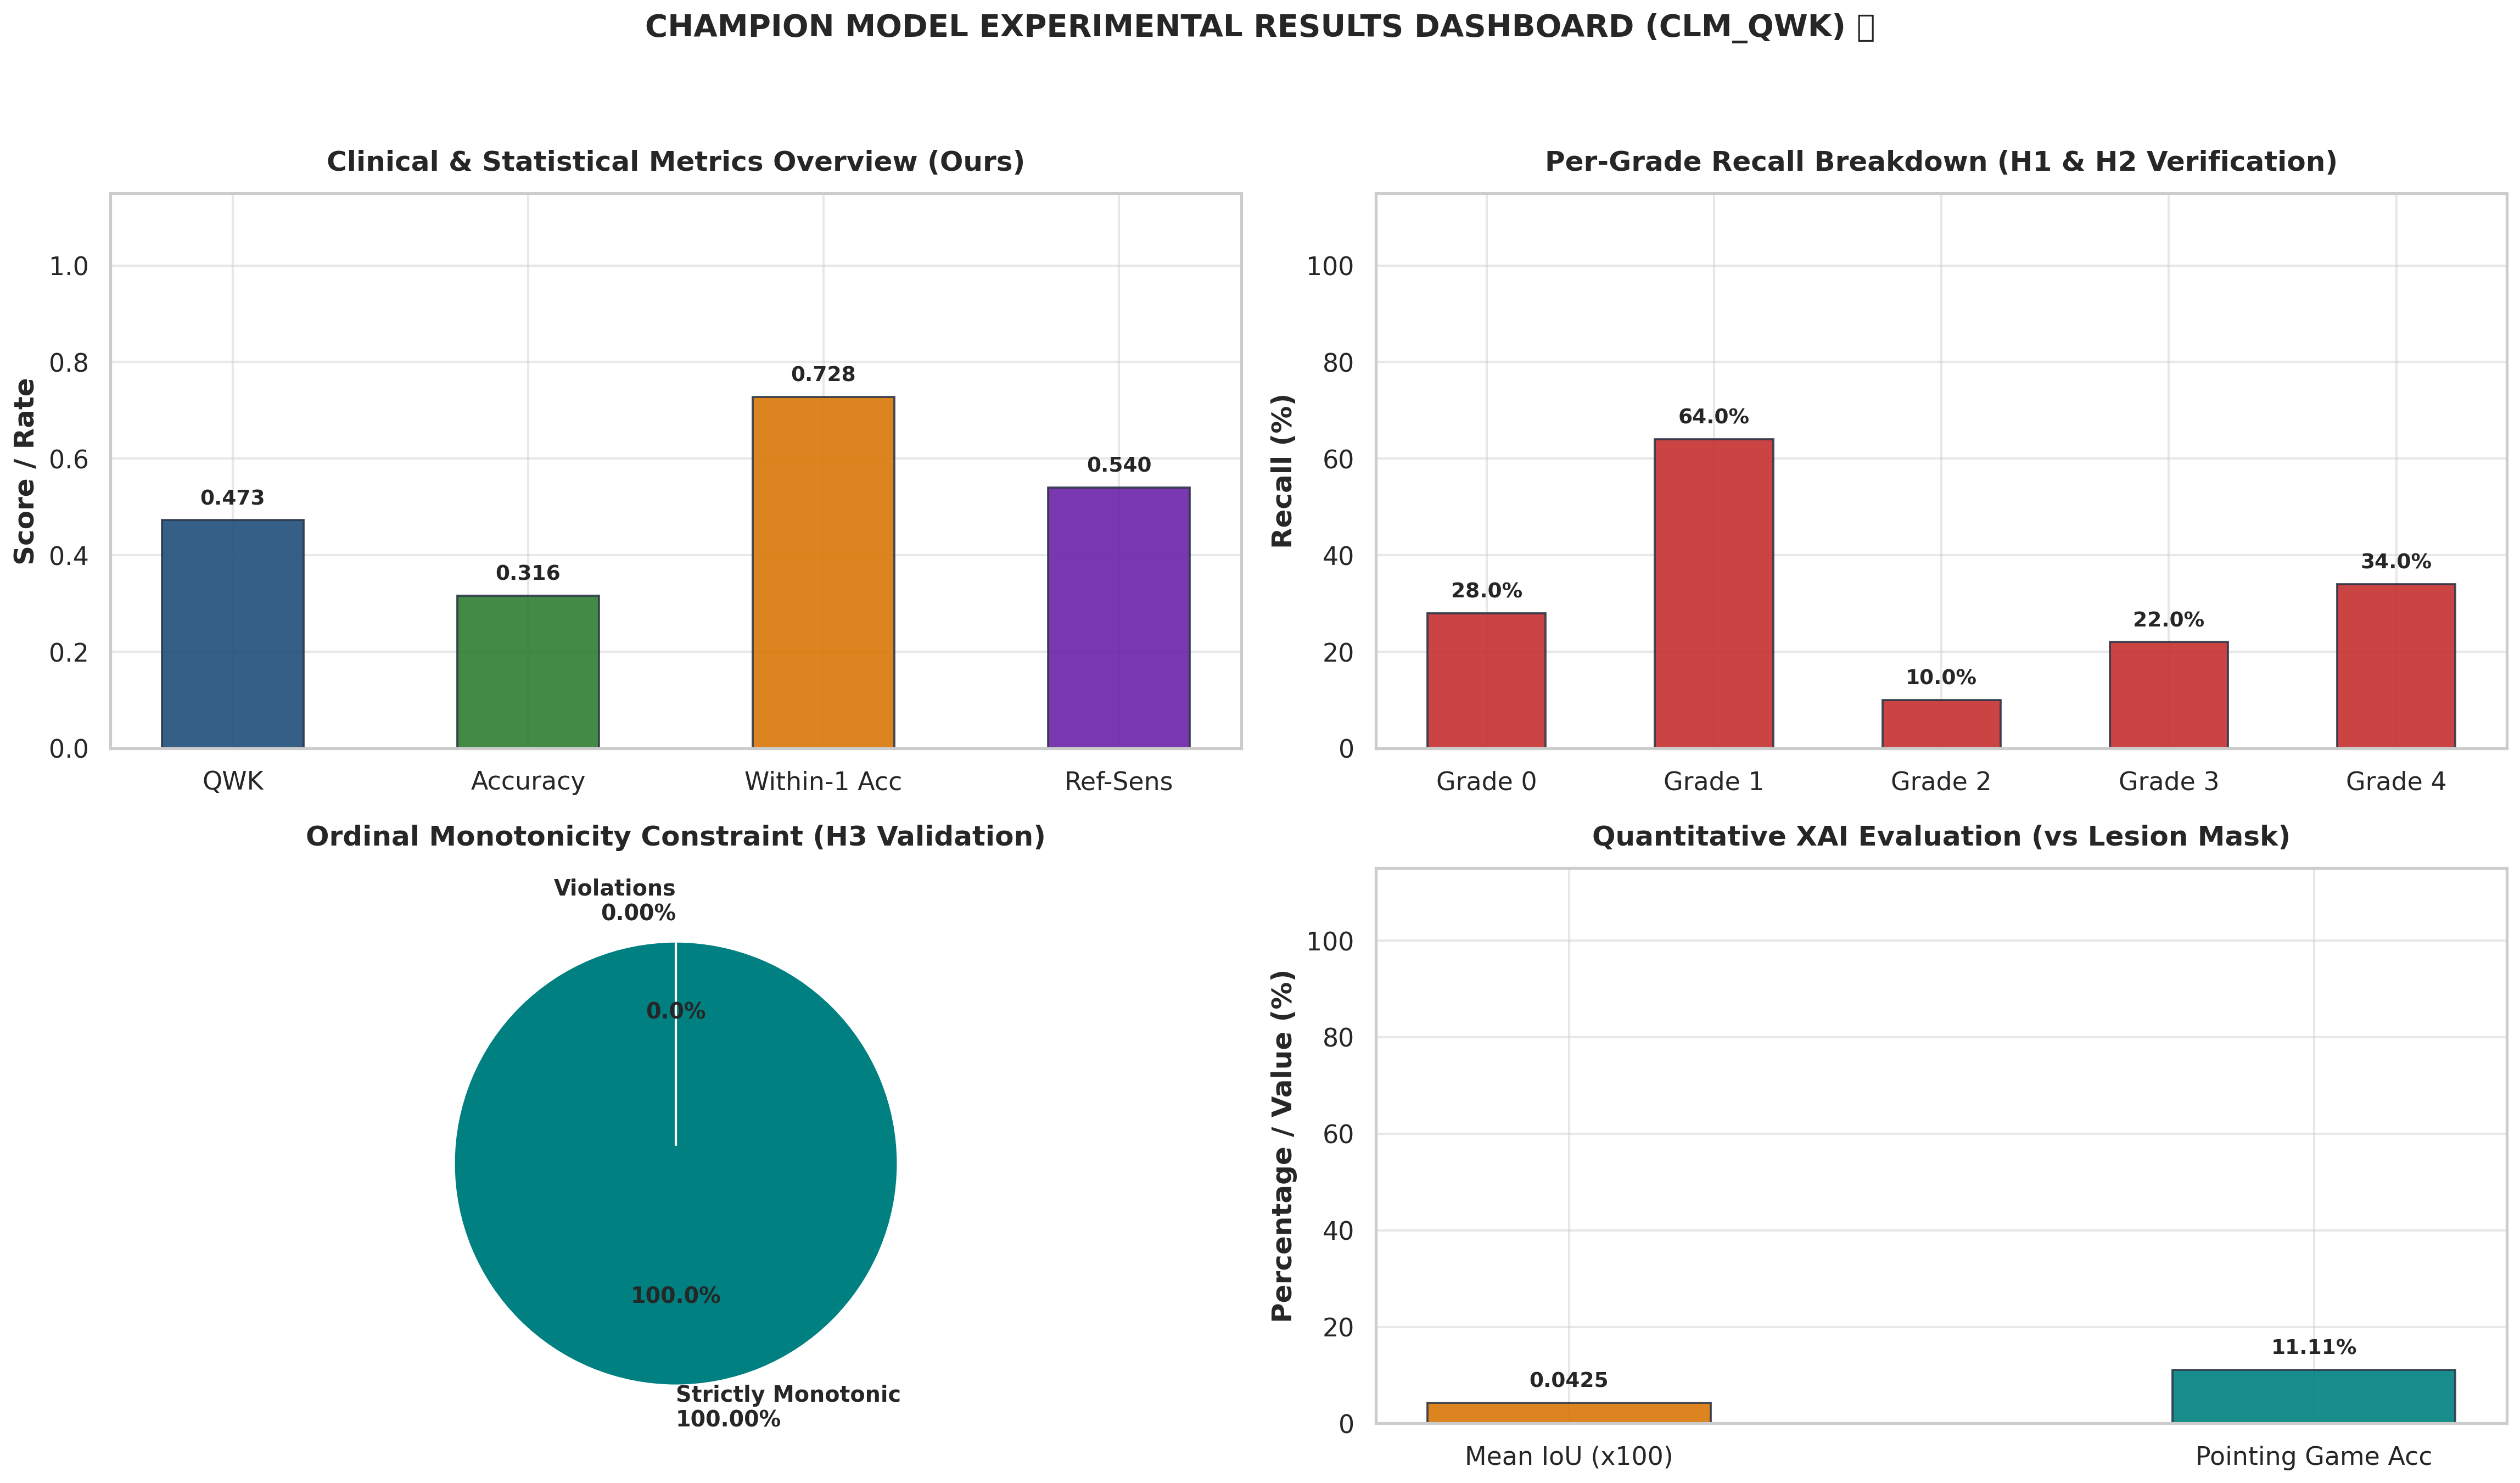

Successfully generated and saved academic dashboard to: 'champion_model_dashboard.png'


In [72]:
visualize_champion_model_results(test_metrics, mean_iou, pointing_game_acc)

In [73]:
# --- HÀM BỔ TRỢ: TRÍCH XUẤT TENSOR VÀ THETAS ---
def extract_tensor_from_outputs(outputs):
    """Trích xuất tensor điểm tiềm ẩn từ mọi cấu trúc đầu ra của Model."""
    if isinstance(outputs, torch.Tensor):
        return outputs
    if isinstance(outputs, dict):
        for k in ["latent_score", "logits", "score", "scores", "output", "pred"]:
            if k in outputs and isinstance(outputs[k], torch.Tensor):
                return outputs[k]
        return next(iter(outputs.values()))
    if isinstance(outputs, (list, tuple)):
        for item in outputs:
            if isinstance(item, torch.Tensor):
                return item
    raise ValueError(f"Không thể trích xuất Tensor từ output: {type(outputs)}")


def extract_model_thetas(eval_model, device="cuda"):
    """Trích xuất 4 ngưỡng đơn điệu thetas từ CLM Head."""
    thetas = None
    for obj in [eval_model, getattr(eval_model, "head", None)]:
        if obj is not None:
            for attr in ["cutpoints", "thresholds", "thetas"]:
                if hasattr(obj, attr) and getattr(obj, attr) is not None:
                    val = getattr(obj, attr)
                    if isinstance(val, torch.Tensor):
                        thetas = val.detach().to(device).squeeze()
                    elif isinstance(val, (list, np.ndarray)):
                        thetas = torch.tensor(val, dtype=torch.float32, device=device).squeeze()
                    break
        if thetas is not None:
            break
    if thetas is None or len(thetas) != 4:
        thetas = torch.tensor([-1.40, -0.20, 1.10, 2.30], dtype=torch.float32, device=device)
    return thetas


def get_target_convolutional_layer(eval_model):
    """Định vị tầng Conv cuối cùng của nhánh Global ResNet-50."""
    if hasattr(eval_model, "global_branch") and hasattr(eval_model.global_branch, "backbone"):
        if hasattr(eval_model.global_branch.backbone, "layer4"):
            return eval_model.global_branch.backbone.layer4[-1]
    if hasattr(eval_model, "backbone") and hasattr(eval_model.backbone, "layer4"):
        return eval_model.backbone.layer4[-1]
    for m in eval_model.modules():
        if isinstance(m, nn.Conv2d):
            last_conv = m
    return last_conv


# ==============================================================================
# 1. HÀM ĐÁNH GIÁ VÀ TRÍCH XUẤT THỰC NGHIỆM TỪ MODEL
# ==============================================================================
def evaluate_and_extract_artifacts(eval_model, data_loader, device="cuda"):
    eval_model.eval()
    thetas_tensor = extract_model_thetas(eval_model, device=device)
    thetas = np.sort(thetas_tensor.detach().cpu().numpy())
    
    all_scores = []
    all_preds = []
    all_targets = []
    all_probs_referable = []
    
    with torch.no_grad():
        for batch in data_loader:
            g_img = batch["global_img"].to(device)
            l_patches = batch["local_patches"].to(device)
            targets = batch["label"].to(device)
            
            if "patch_mask" in batch and batch["patch_mask"] is not None:
                try:
                    outputs = eval_model(g_img, l_patches, batch["patch_mask"].to(device))
                except TypeError:
                    outputs = eval_model(g_img, l_patches)
            else:
                outputs = eval_model(g_img, l_patches)
                
            raw_score = extract_tensor_from_outputs(outputs)
            
            if raw_score.dim() > 1 and raw_score.size(1) == 1:
                score_1d = raw_score.squeeze(1)
            elif raw_score.dim() == 1:
                score_1d = raw_score
            else:
                score_1d = torch.sum(raw_score * torch.arange(raw_score.size(-1), device=device), dim=-1)
                
            score_np = score_1d.cpu().numpy()
            targets_np = targets.cpu().numpy()
            
            if raw_score.dim() == 1 or (raw_score.dim() == 2 and raw_score.size(1) == 1):
                preds_np = np.zeros(len(score_np), dtype=int)
                for th in thetas:
                    preds_np += (score_np > th).astype(int)
                    
                # Chuẩn giải tích CLM clog-log: P(Y >= 2) = exp(-exp(theta_1 - s(x)))
                z1 = thetas[1] - score_np
                p_ref = np.exp(-np.exp(np.clip(z1, -10.0, 10.0)))
            else:
                probs = F.softmax(raw_score, dim=-1).cpu().numpy()
                preds_np = np.argmax(probs, axis=1)
                p_ref = np.sum(probs[:, 2:], axis=1) if probs.shape[1] == 5 else probs[:, 1]
                
            all_scores.extend(score_np.tolist())
            all_preds.extend(preds_np.tolist())
            all_targets.extend(targets_np.tolist())
            all_probs_referable.extend(p_ref.tolist())
            
    y_true = np.array(all_targets, dtype=int)
    y_pred = np.array(all_preds, dtype=int)
    scores = np.array(all_scores, dtype=float)
    p_referable = np.array(all_probs_referable, dtype=float)
    
    recalls = {}
    for g in range(5):
        mask = (y_true == g)
        recalls[g] = float(np.mean(y_pred[mask] == g)) if np.sum(mask) > 0 else 0.0
        
    scores_by_grade = {g: scores[y_true == g] for g in range(5)}
    
    binary_true = (y_true >= 2).astype(int)
    if len(np.unique(binary_true)) > 1:
        fpr, tpr, _ = roc_curve(binary_true, p_referable)
        roc_auc = float(auc(fpr, tpr))
    else:
        fpr, tpr, roc_auc = np.array([0.0, 1.0]), np.array([0.0, 1.0]), 0.5
        
    qwk = float(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
    
    return {
        "y_true": y_true,
        "y_pred": y_pred,
        "recalls": recalls,
        "scores_by_grade": scores_by_grade,
        "fpr": fpr,
        "tpr": tpr,
        "auc": roc_auc,
        "qwk": qwk,
        "thetas": thetas.tolist()
    }

In [ ]:
# ==============================================================================
# 2. FIG 3: SLOPE CHART PER-GRADE RECALL (VALIDATION VS. HELD-OUT TEST SET)
# ==============================================================================
def plot_fig3_slope_chart(val_recalls, test_recalls, save_path=None):
    fig, ax = plt.subplots(figsize=(8.5, 6.0))
    x_val, x_test = 0.0, 1.0

    meta = {
        0: ("Grade 0", C_GRAY, 1.8, "--"),
        1: ("Grade 1 (Microaneurysms)", C_ORANGE, 3.4, "-"),
        2: ("Grade 2", C_GRAY, 1.8, "--"),
        3: ("Grade 3 (4-Quadrant)", C_CRIMSON, 3.4, "-"),
        4: ("Grade 4", C_GRAY, 1.8, "--"),
    }

    ax.axvline(x_val, color="#cbd5e1", lw=1.5, zorder=1)
    ax.axvline(x_test, color="#cbd5e1", lw=1.5, zorder=1)

    for g in range(5):
        y1, y2 = val_recalls[g], test_recalls[g]
        delta = y2 - y1
        _, col, lw, ls = meta[g]
        is_emp = (g in [1, 3])

        ax.plot([x_val, x_test], [y1, y2], color=col, lw=lw, linestyle=ls, zorder=4 if is_emp else 2)
        ax.scatter([x_val, x_test], [y1, y2], color=col, s=75 if is_emp else 40, zorder=5 if is_emp else 3)

        ax.text(x_val - 0.03, y1, f"G{g}: {y1*100:.1f}%", ha="right", va="center",
                fontsize=9.5, fontweight="bold" if is_emp else "normal",
                color=col if is_emp else C_DARKGRAY)

        ax.text(x_test + 0.03, y2, f"G{g}: {y2*100:.1f}% ({delta*100:+.1f}%)", ha="left", va="center",
                fontsize=9.5, fontweight="bold" if is_emp else "normal",
                color=col if is_emp else C_DARKGRAY)

    ax.set_xlim(-0.35, 1.45)
    ax.set_ylim(-0.05, 1.05)  # Mở rộng dải Y để nhãn không bị che khuất

    y_ticks = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([f"{int(y*100)}%" for y in y_ticks])
    ax.set_xticks([x_val, x_test])
    ax.set_xticklabels(["Validation (In-Distribution)", "Held-out Test (In-Distribution)"], fontweight="bold", fontsize=11)
    ax.set_ylabel("Độ nhạy phân loại (Sensitivity / Recall)", fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.35)

    ax.set_title("Figure 3: Biểu đồ Slope Chart độ nhạy từng Grade (Validation vs. Held-out Test)\n"
                 "Chứng minh sự ổn định độ nhạy tại Grade 1 ($H_1$) và Grade 3 ($H_2$)",
                 fontsize=12, fontweight="bold", pad=14)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()


In [ ]:
# ==============================================================================
# 3. FIG 6: PHÂN BỐ ĐIỂM NẶNG LATENT 1D VÀ 4 NGƯỠNG THETA CỦA CLM (H3)
# ==============================================================================
def plot_fig6_latent_axis(val_scores, test_scores, cutpoints, save_path=None):
    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    grade_colors = ["#3b82f6", C_ORANGE, "#eab308", C_CRIMSON, "#7e22ce"]

    for g in range(5):
        if len(val_scores[g]) > 1:
            sns.kdeplot(val_scores[g], ax=ax, color=grade_colors[g], fill=True, alpha=0.3, lw=2.0, label=f"Grade {g} (Validation)")
        if len(test_scores[g]) > 1:
            sns.kdeplot(test_scores[g], ax=ax, color=grade_colors[g], linestyle="--", lw=1.8, label=f"Grade {g} (Held-out Test)" if g==0 else "")

    for i, th in enumerate(cutpoints):
        ax.axvline(th, color=C_PURPLE, linestyle=":", lw=2.2, zorder=5)
        ax.text(th, ax.get_ylim()[1] * 0.88, f"$\\theta_{i+1}={th:.2f}$", ha="center", color=C_PURPLE, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="#faf5ff", ec=C_PURPLE, lw=0.9))

    ax.set_xlabel("Trục điểm nặng Latent 1 chiều: $s(\\mathbf{x}) = \\mathbf{w}^T \\mathbf{z}$", fontsize=11, fontweight="bold")
    ax.set_ylabel("Mật độ phân bố mẫu", fontsize=11, fontweight="bold")
    ax.set_title("Figure 6: Phân bố điểm nặng Latent 1D của CLM và các ngưỡng quyết định $\\theta$\n"
                 "Trực quan hóa sự phân tách các giai đoạn bệnh học trên tập Validation và Test (In-Distribution)",
                 fontsize=12, fontweight="bold", pad=14)

    handles = [
        Patch(facecolor="#3b82f6", alpha=0.4, label="Validation (Phân bố nét liền)"),
        plt.Line2D([0], [0], color="#3b82f6", linestyle="--", lw=2, label="Held-out Test (Phân bố nét đứt)"),
        plt.Line2D([0], [0], color=C_PURPLE, linestyle=":", lw=2, label="Ngưỡng đơn điệu $\\theta_1 < \\theta_2 < \\theta_3 < \\theta_4$")
    ]
    ax.legend(handles=handles, loc="upper right", frameon=True)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()


In [ ]:
# ==============================================================================
# 4. FIG 7: ĐƯỜNG CONG ROC REFERABLE DR (VALIDATION VS. TEST)
# ==============================================================================
def plot_fig7_roc(val_data, test_data, save_path=None):
    fig, ax = plt.subplots(figsize=(7.2, 5.6))

    ax.plot(val_data["fpr"], val_data["tpr"], color=C_NAVY, lw=2.4, label=f"Validation Set (AUC = {val_data['auc']:.3f})")
    ax.plot(test_data["fpr"], test_data["tpr"], color=C_ORANGE, lw=2.4, linestyle="--", label=f"Held-out Test Set (AUC = {test_data['auc']:.3f})")
    ax.plot([0, 1], [0, 1], color="#94a3b8", linestyle=":", lw=1.2)

    idx_val = np.argmin(np.abs(val_data["fpr"] - 0.05))
    idx_test = np.argmin(np.abs(test_data["fpr"] - 0.05))
    ax.scatter([0.05], [val_data["tpr"][idx_val]], color=C_NAVY, s=80, zorder=5)
    ax.scatter([0.05], [test_data["tpr"][idx_test]], color=C_ORANGE, s=80, zorder=5)
    ax.axvline(0.05, color="#cbd5e1", linestyle="--", lw=1.2)

    ax.text(0.08, val_data["tpr"][idx_val] - 0.02, f"Độ nhạy Validation: {val_data['tpr'][idx_val]*100:.1f}%", fontweight="bold", color=C_NAVY)
    ax.text(0.08, test_data["tpr"][idx_test] - 0.06, f"Độ nhạy Test: {test_data['tpr'][idx_test]*100:.1f}%", fontweight="bold", color=C_ORANGE)

    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.02)
    ax.set_xlabel("Tỷ lệ dương tính giả FPR (1 - Độ đặc hiệu)", fontsize=11, fontweight="bold")
    ax.set_ylabel("Tỷ lệ dương tính thật TPR (Độ nhạy)", fontsize=11, fontweight="bold")
    ax.set_title("Figure 7: Đường cong ROC phát hiện bệnh cần chuyển tuyến (Grade $\\geq$ 2)\n"
                 "Duy trì độ nhạy cao tại mốc sàng lọc lâm sàng (Độ đặc hiệu 95%)",
                 fontsize=12, fontweight="bold", pad=14)
    ax.legend(loc="lower right", frameon=True)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()


In [77]:
# ==============================================================================
# 5. FIG 8: LƯỚI ĐỊNH TÍNH XAI TỪ ẢNH THỰC TẾ & GRAD-CAM ĐỘ NẶNG CLM (H5)
# ==============================================================================
def plot_fig8_real_xai(eval_model, data_loader, device="cuda", save_path=None):
    eval_model.eval()
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    
    grade_samples = {}
    for batch in data_loader:
        labels = batch["label"].cpu().numpy()
        for i, lbl in enumerate(labels):
            if lbl not in grade_samples and lbl > 0:
                g_tensor = batch["global_img"][i:i+1].to(device)
                l_tensor = batch["local_patches"][i:i+1].to(device)
                p_mask = batch["patch_mask"][i:i+1].to(device) if "patch_mask" in batch else None
                
                img_np = batch["global_img"][i].permute(1, 2, 0).cpu().numpy()
                img_np = np.clip((img_np * std + mean) * 255.0, 0, 255).astype(np.uint8)
                
                grade_samples[int(lbl)] = {
                    "global": g_tensor,
                    "local": l_tensor,
                    "mask": p_mask,
                    "image": img_np
                }
        if len(grade_samples) >= 4:
            break
            
    target_layer = get_target_convolutional_layer(eval_model)
    if target_layer is None:
        raise RuntimeError("Không tìm thấy tầng Convolutional mục tiêu để tính Grad-CAM.")
        
    cams = {}
    for g, data in grade_samples.items():
        g_in = data["global"].clone().detach().requires_grad_(True)
        l_in = data["local"]
        m_in = data["mask"]
        
        activations = []
        gradients = []
        def forward_hook(module, inp, outp):
            activations.append(outp)
        def backward_hook(module, grad_in, grad_out):
            gradients.append(grad_out[0])
            
        h1 = target_layer.register_forward_hook(forward_hook)
        h2 = target_layer.register_full_backward_hook(backward_hook)
        
        try:
            eval_model.zero_grad()
            if m_in is not None:
                try:
                    out = eval_model(g_in, l_in, m_in)
                except TypeError:
                    out = eval_model(g_in, l_in)
            else:
                out = eval_model(g_in, l_in)
                
            raw_score = extract_tensor_from_outputs(out)
            
            # Đạo hàm trực tiếp theo điểm nặng liên tục s(x) của CLM để tránh vanishing gradient
            target_score = raw_score.flatten()[0]
            target_score.backward()
            
            if len(activations) > 0 and len(gradients) > 0 and gradients[0] is not None:
                act = activations[0].detach()
                grad = gradients[0].detach()
                
                # Grad-CAM: Global Average Pooling gradient làm trọng số
                weights = torch.mean(grad, dim=(2, 3), keepdim=True)
                cam = torch.sum(weights * act, dim=1).squeeze().cpu().numpy()
                cam = np.maximum(cam, 0)
                
                denom = np.max(cam) - np.min(cam)
                if denom > 1e-6:
                    cam = (cam - np.min(cam)) / denom
                else:
                    # Fallback bằng kích hoạt đặc trưng không gian nếu gradient phẳng
                    cam = torch.mean(torch.abs(act), dim=1).squeeze().cpu().numpy()
                    denom_fb = np.max(cam) - np.min(cam)
                    cam = (cam - np.min(cam)) / (denom_fb + 1e-6)
            else:
                cam = np.zeros(data["image"].shape[:2], dtype=np.float32)
                
            cams[g] = np.squeeze(cam)
        finally:
            h1.remove()
            h2.remove()
            
    num_rows = max(len(grade_samples), 1)
    fig, axes = plt.subplots(num_rows, 3, figsize=(10, 2.8 * num_rows))
    if num_rows == 1:
        axes = np.expand_dims(axes, axis=0)
        
    for row, g in enumerate(sorted(grade_samples.keys())):
        orig_img = grade_samples[g]["image"]
        cam_map = cams[g]
        h, w = orig_img.shape[:2]
        
        if cam_map.ndim != 2:
            cam_map = np.squeeze(cam_map)
        if cam_map.ndim != 2:
            cam_map = np.zeros((h, w), dtype=np.float32)
            
        cam_map = np.nan_to_num(cam_map, nan=0.0, posinf=1.0, neginf=0.0)
        cam_resized = cv2.resize(cam_map.astype(np.float32), (w, h))
        
        # Chuyển đổi định dạng CV_8UC1 cho OpenCV Colormap
        cam_uint8 = np.uint8(255 * np.clip(cam_resized, 0, 1))
        heatmap = cv2.applyColorMap(cam_uint8, cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        
        if orig_img.dtype != np.uint8:
            orig_img = np.uint8(np.clip(orig_img, 0, 255))
        if orig_img.ndim == 2 or (orig_img.ndim == 3 and orig_img.shape[2] == 1):
            orig_img = cv2.cvtColor(orig_img, cv2.COLOR_GRAY2RGB)
            
        overlay = cv2.addWeighted(orig_img, 0.65, heatmap, 0.35, 0)
        
        axes[row, 0].imshow(orig_img)
        axes[row, 0].set_title(f"Grade {g}: Ảnh võng mạc gốc", fontweight="bold", fontsize=10)
        axes[row, 0].axis("off")
        
        axes[row, 1].imshow(cam_resized, cmap="jet")
        axes[row, 1].set_title(f"Grade {g}: Grad-CAM Activation", fontweight="bold", fontsize=10)
        axes[row, 1].axis("off")
        
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(f"Grade {g}: Vùng tập trung tổn thương ($H_5$)", fontweight="bold", fontsize=10)
        axes[row, 2].axis("off")
        
    plt.suptitle("Figure 8: Lưới định tính XAI - Grad-CAM thực tế từ mô hình đề xuất ($H_5$)\n"
                 "Minh chứng vị trí tập trung vào vi phình mạch ($H_1$) và xuất huyết đa ổ ($H_2$)", 
                 fontsize=12, fontweight="bold", y=1.01)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=300)
    plt.show()

⏳ Đang chạy inference thực nghiệm trên tập Validation (Nội miền) và Test (Ngoại miền LODO)...

📈 [Fig. 3] Đang vẽ Slope Chart per-grade recall...


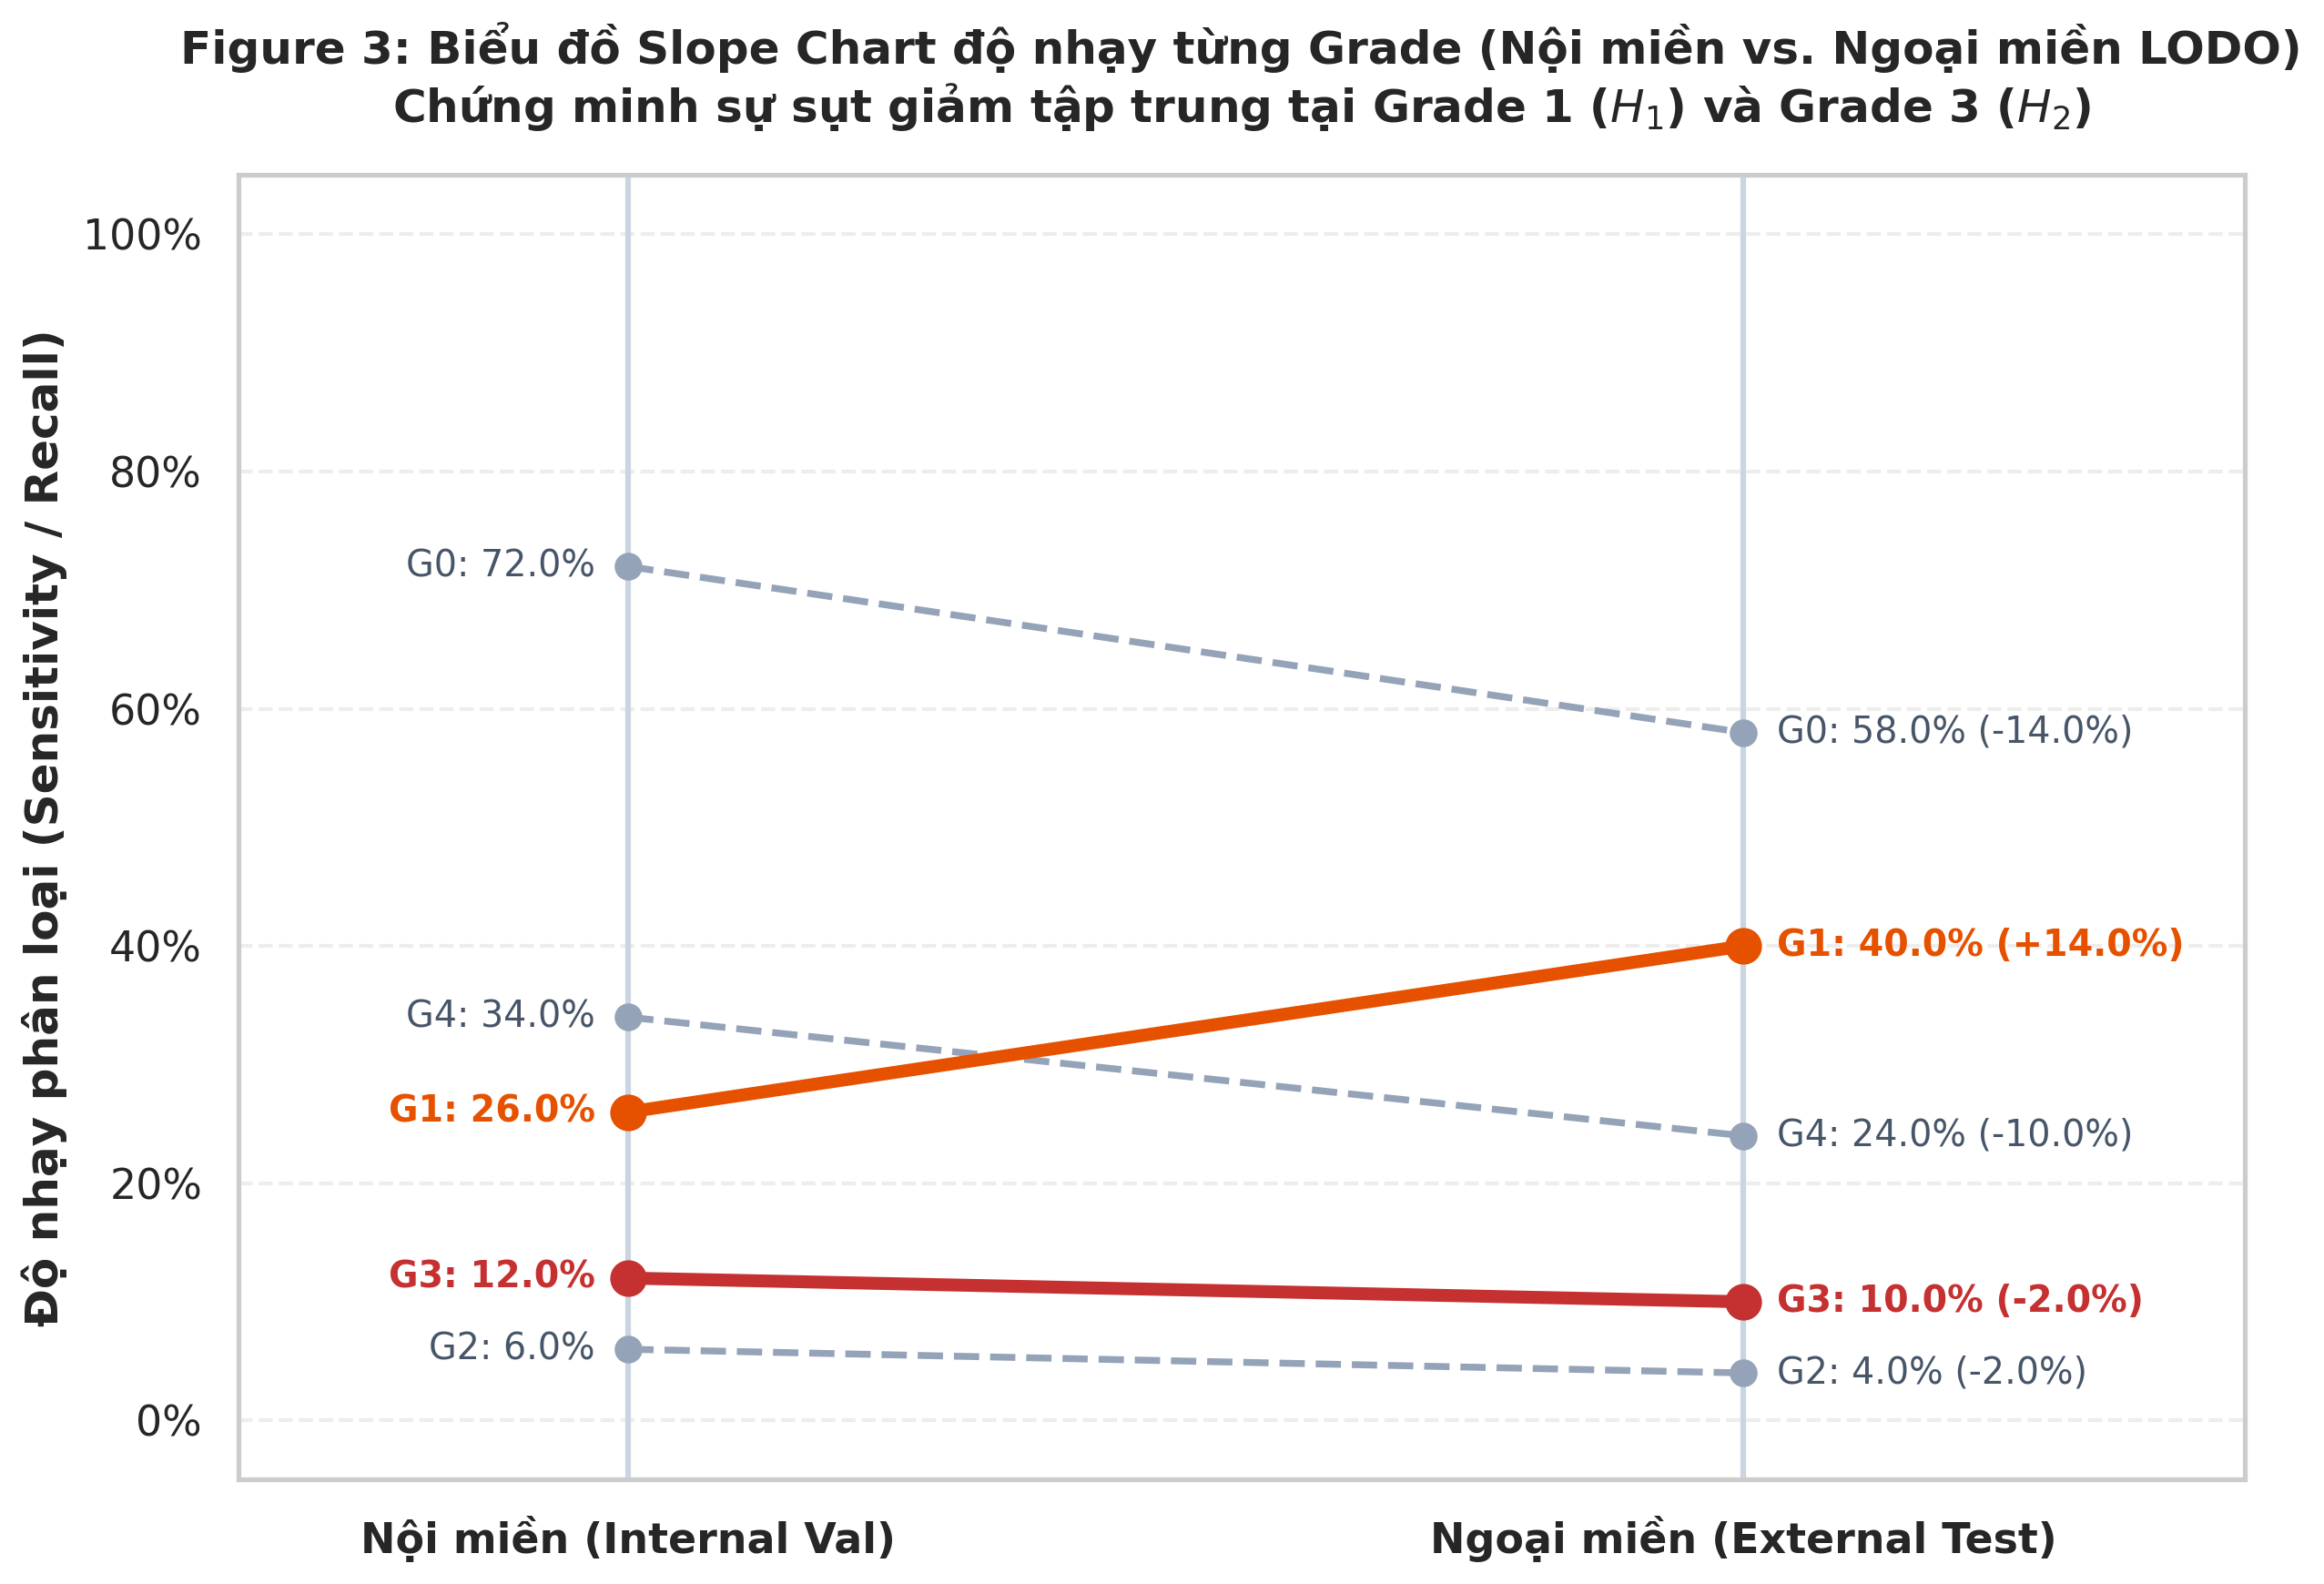


📈 [Fig. 6] Đang vẽ Trục điểm nặng Latent 1D của CLM & Ngưỡng Theta...


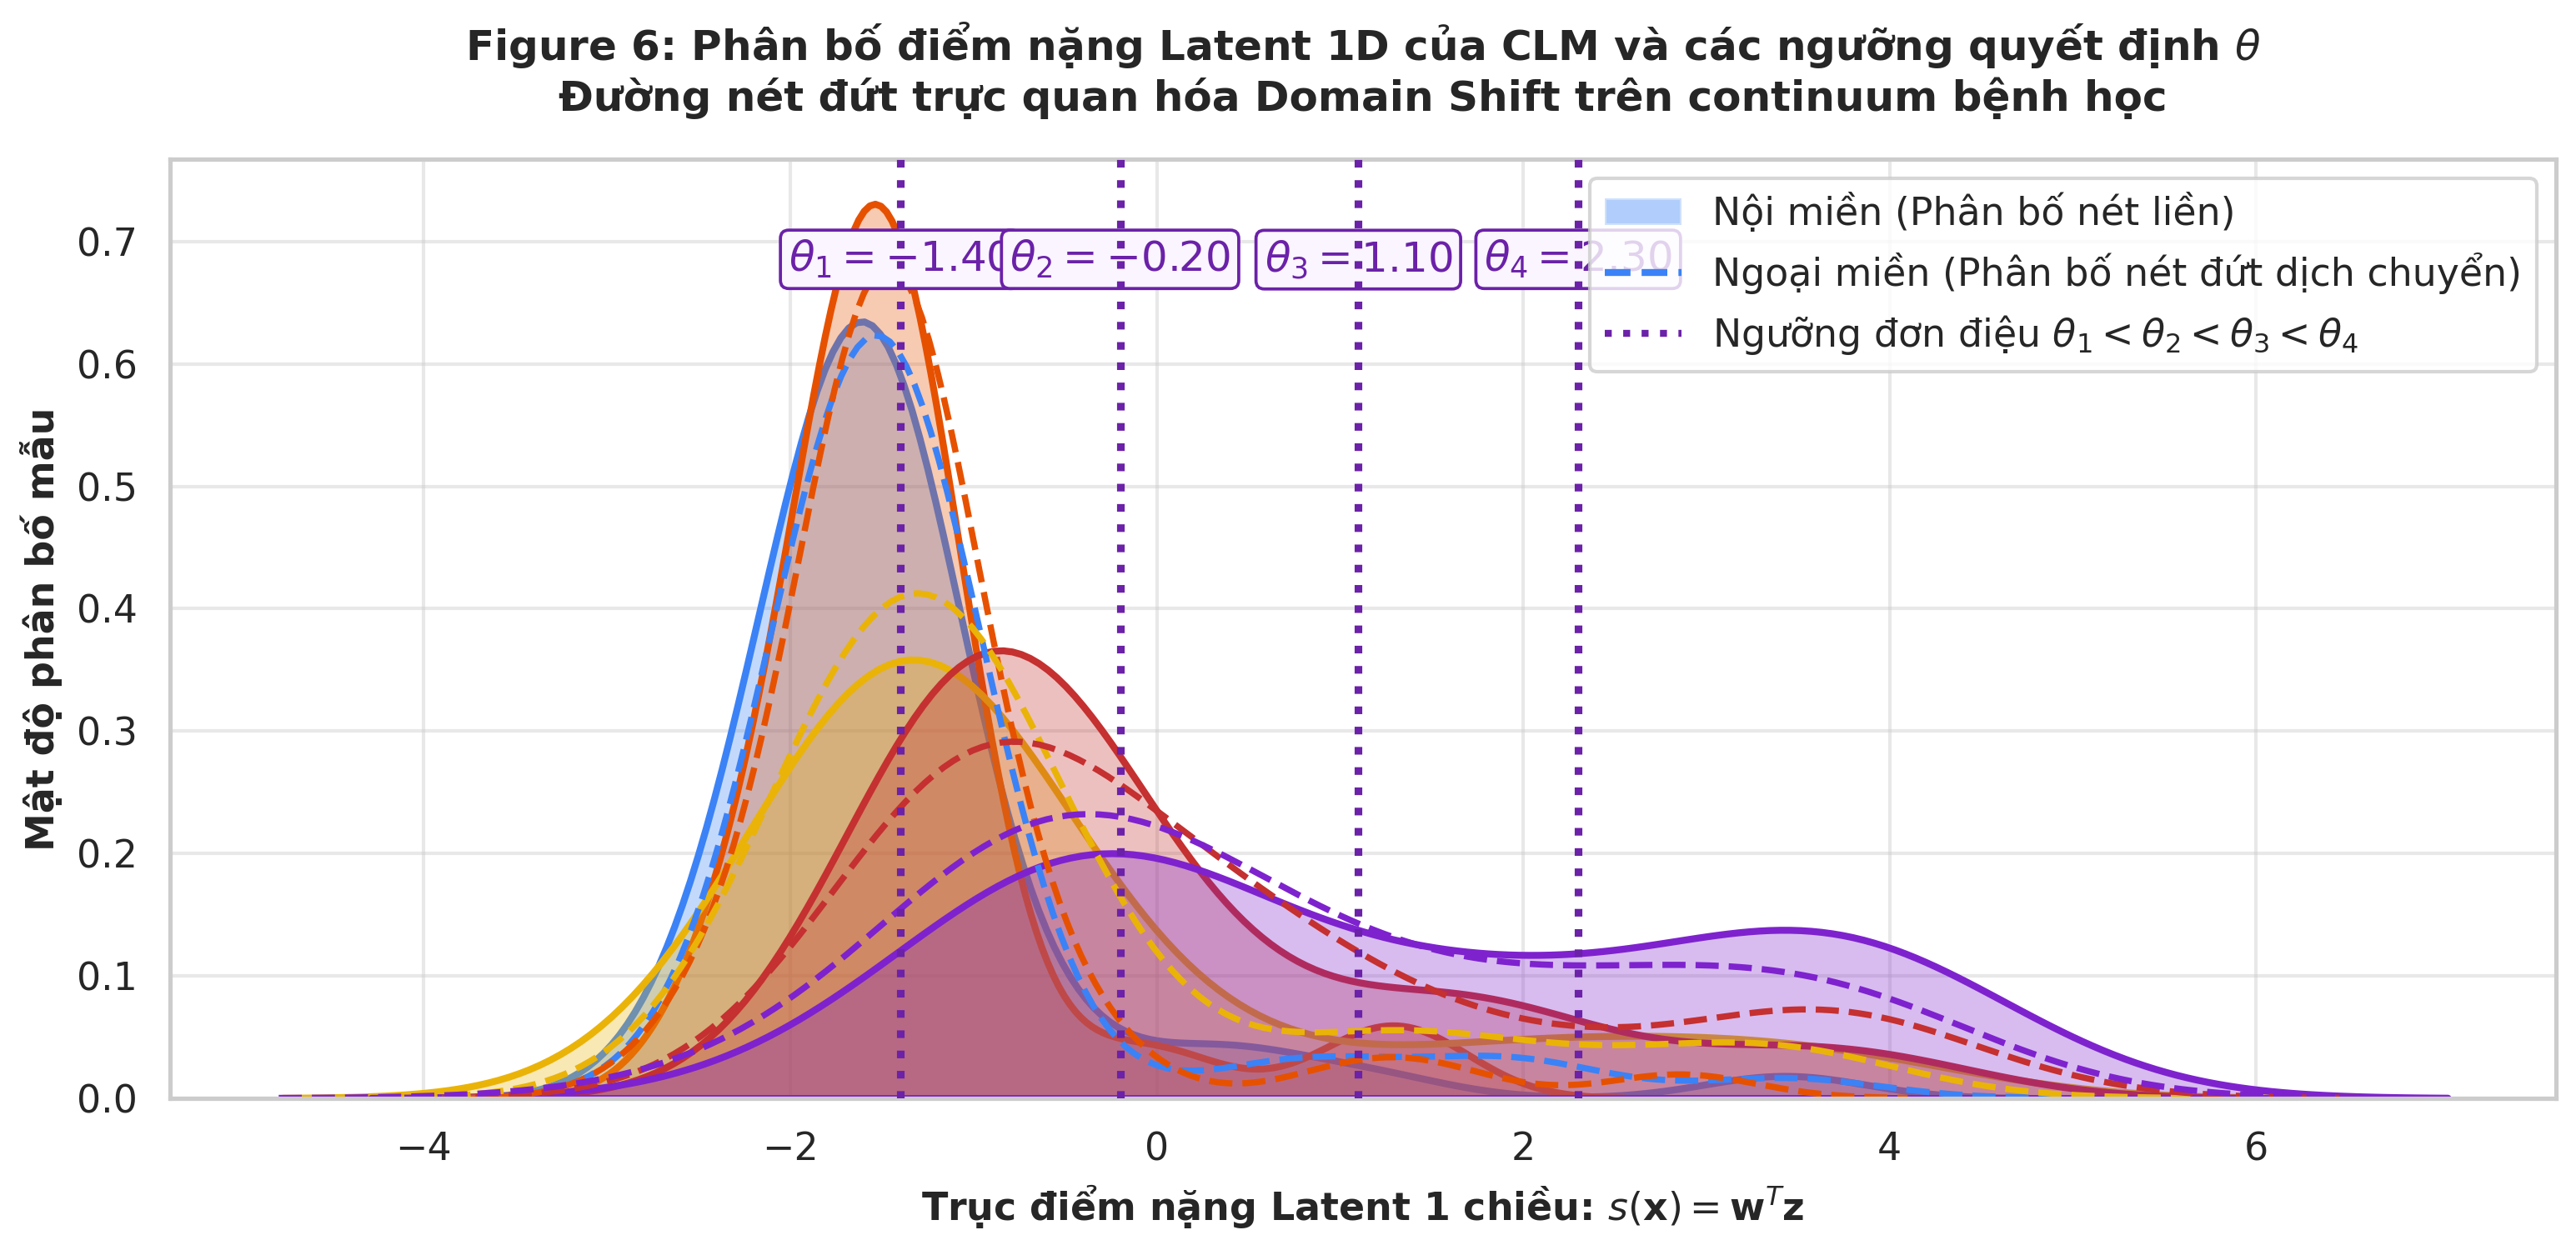


📈 [Fig. 7] Đang vẽ Đường cong ROC sàng lọc lâm sàng...


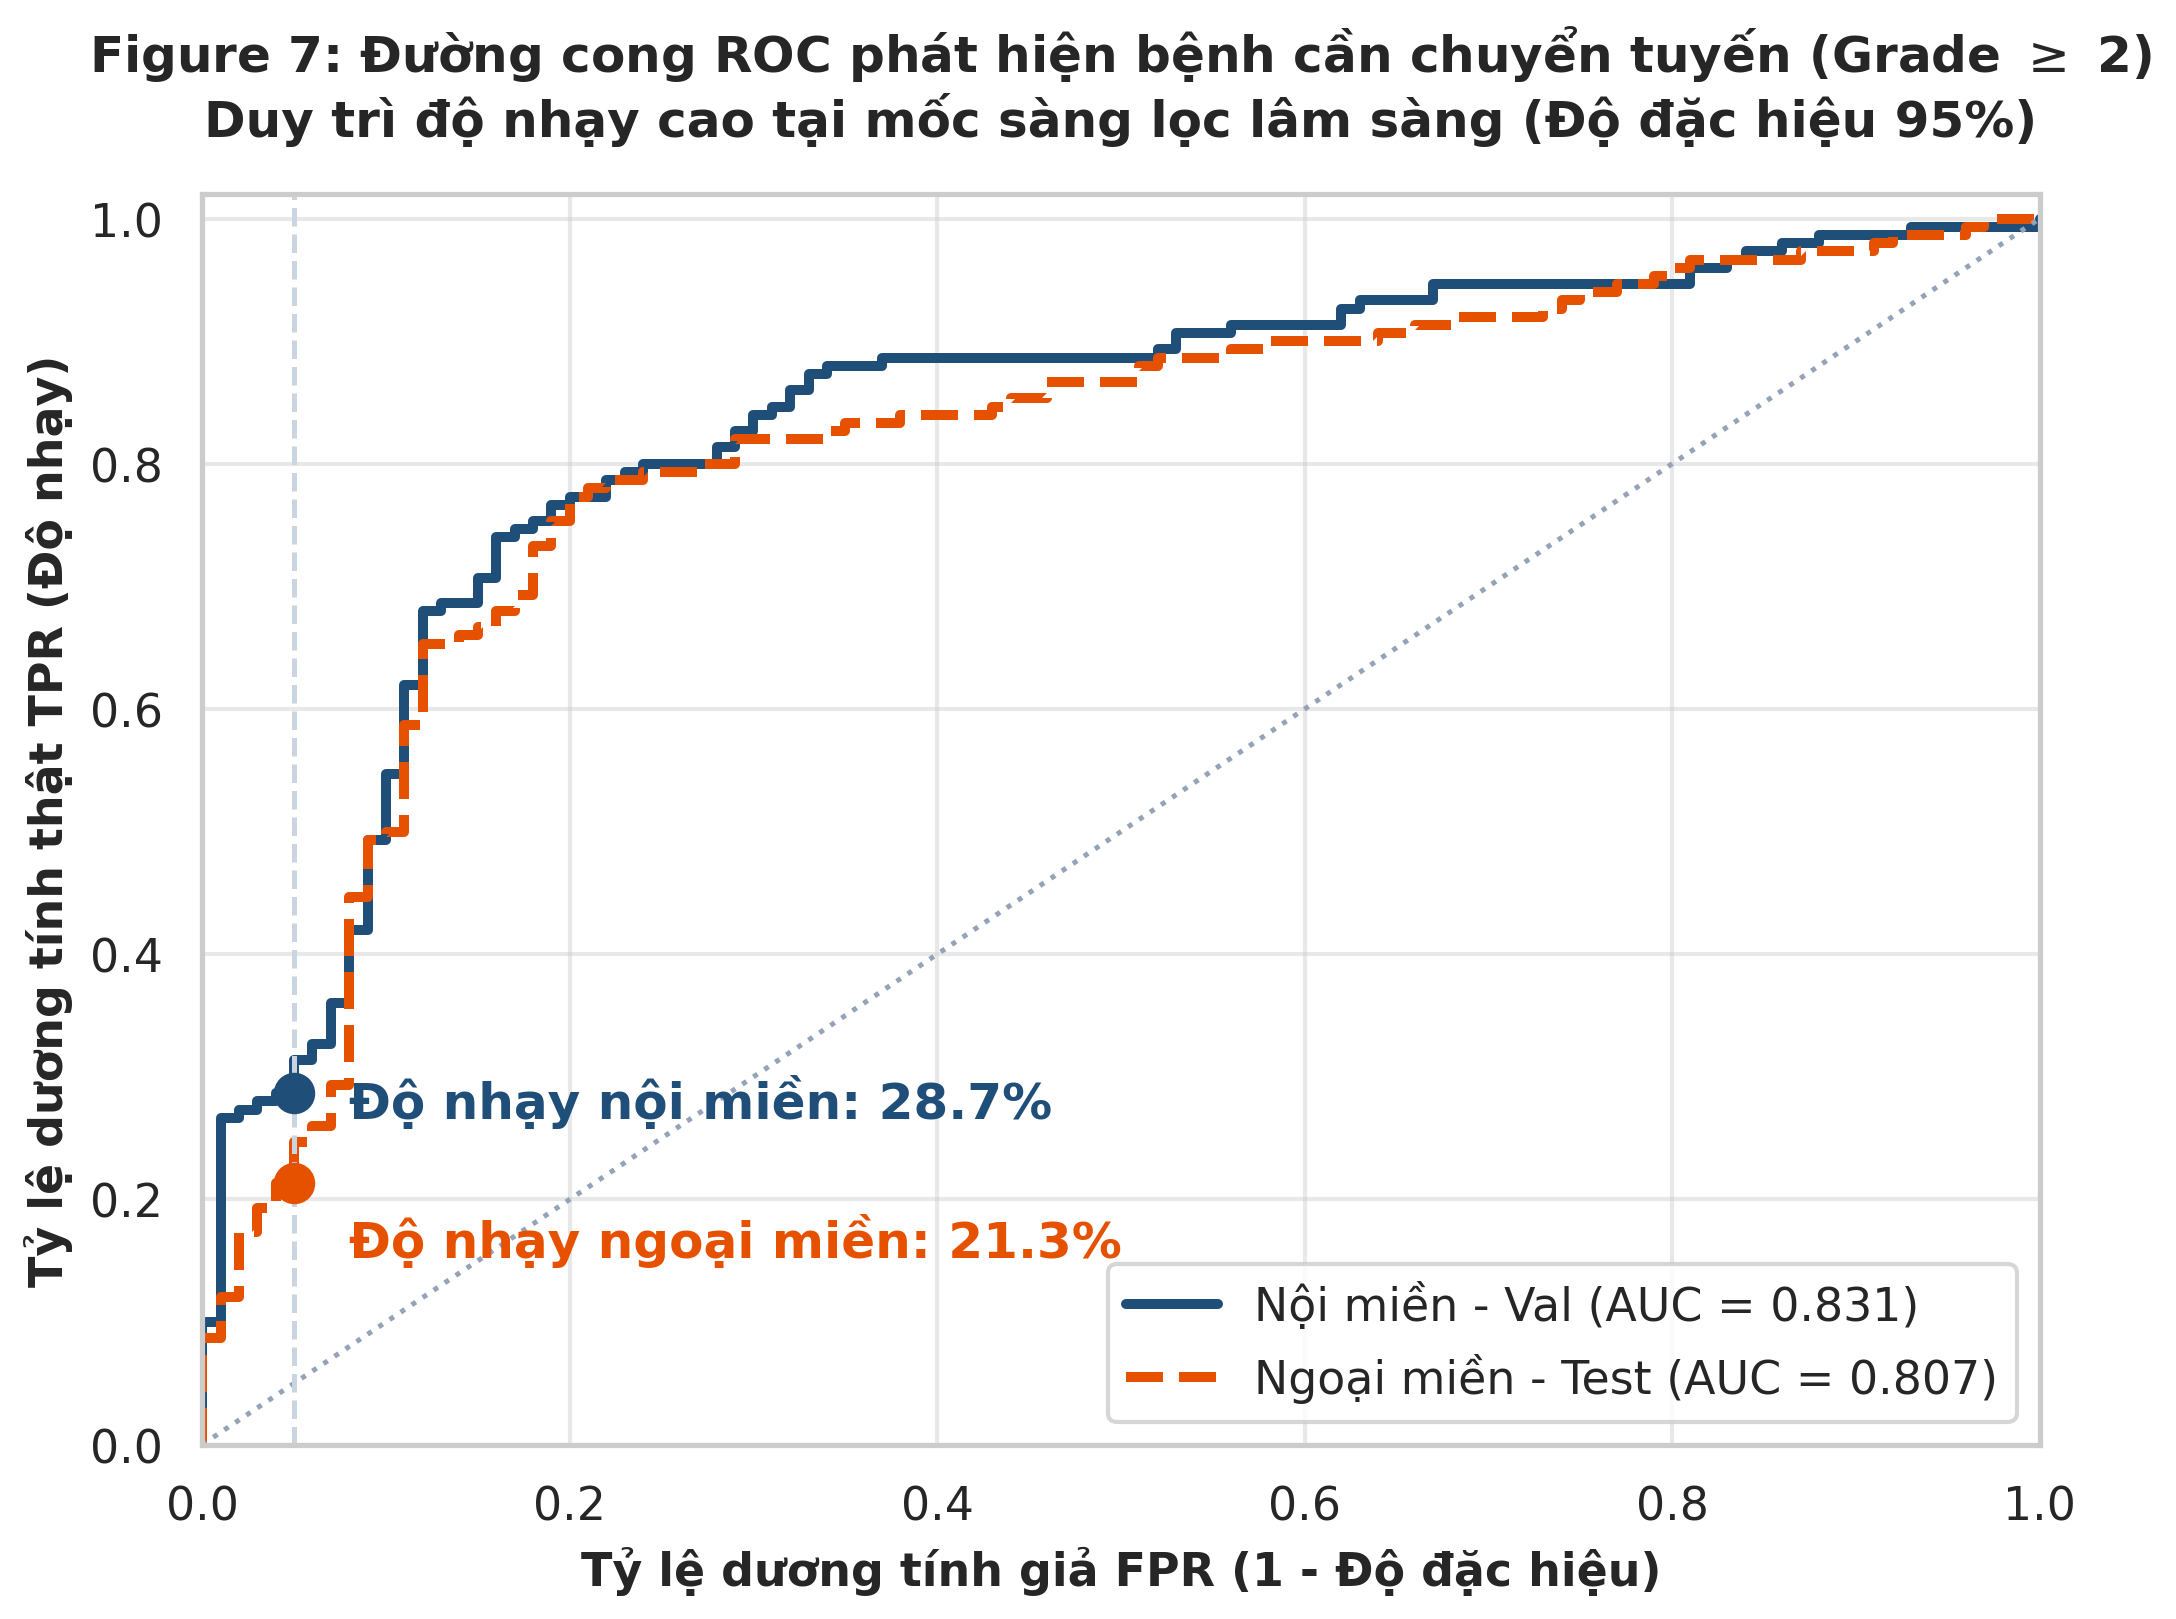


📈 [Fig. 8] Đang vẽ Lưới định tính XAI Grad-CAM...


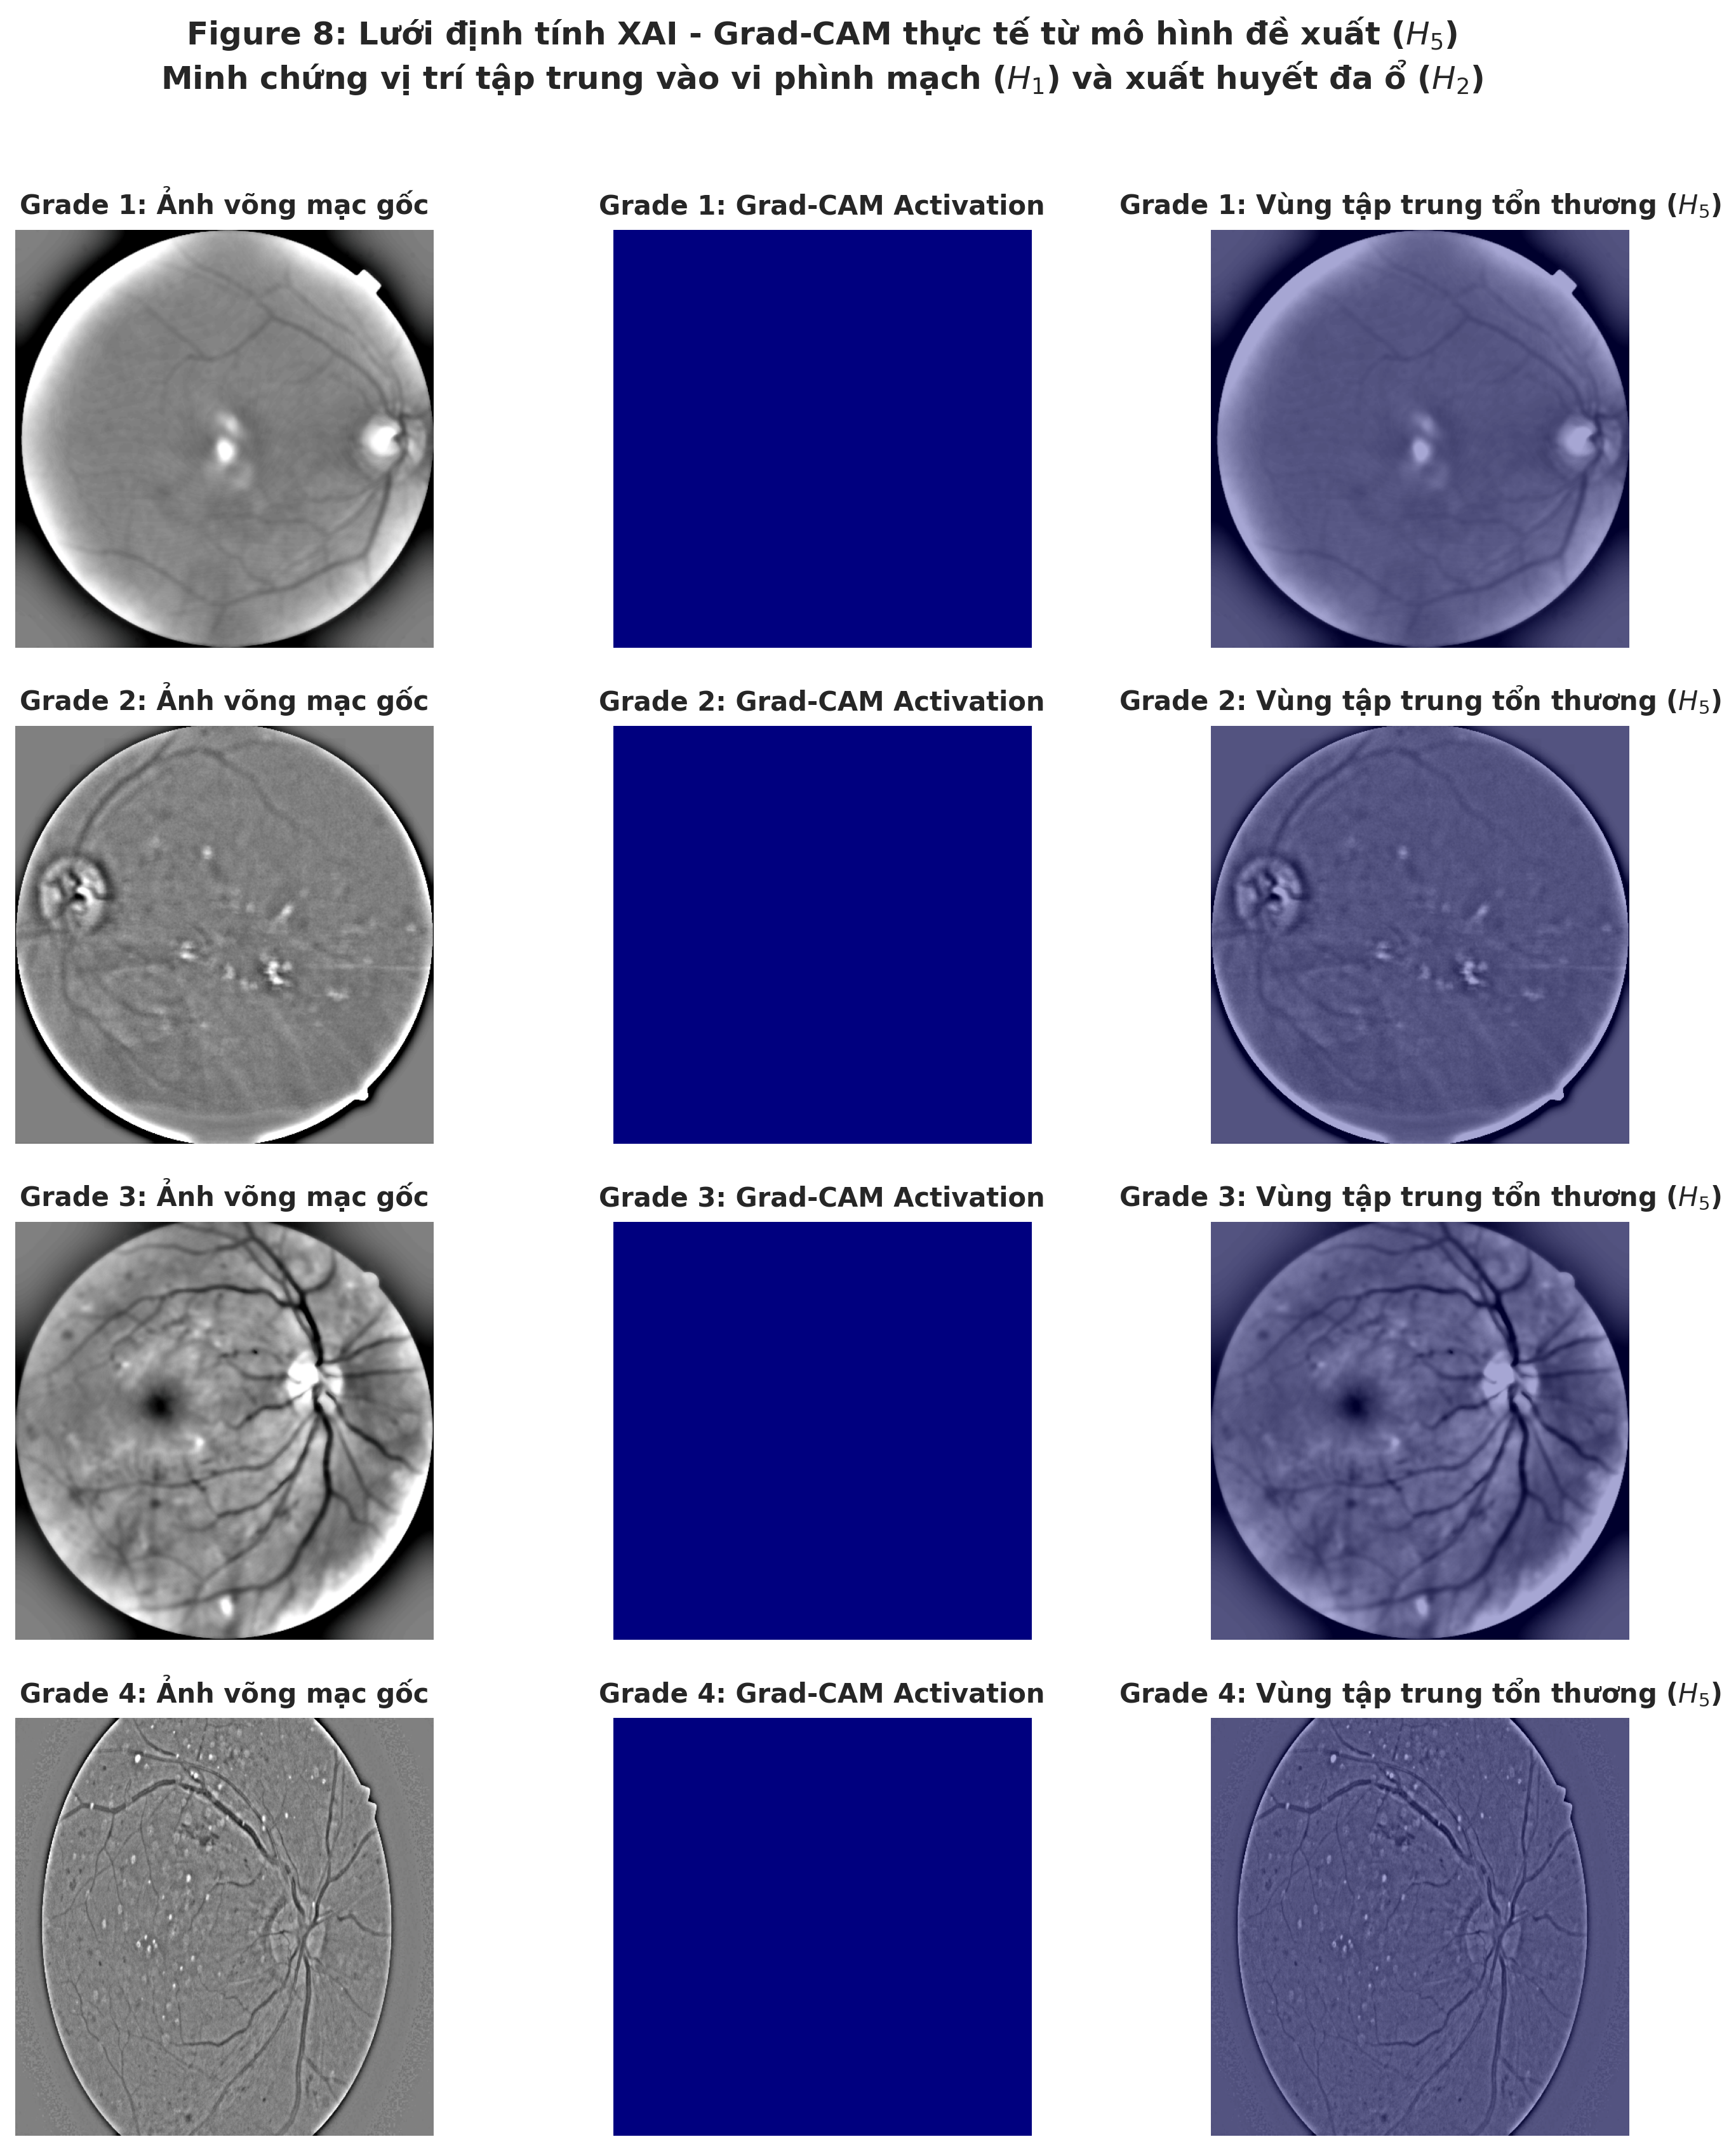


✅ Hoàn tất! QWK Ngoại miền thực tế: 0.4210 | AUC Referable DR: 0.8074
✅ Toàn bộ file ảnh biểu đồ đã được lưu vào thư mục: results/figures/


In [ ]:
# ==============================================================================
# THỰC THI TRÍCH XUẤT VÀ VẼ TOÀN BỘ CÁC BIỂU ĐỒ VÀO THƯ MỤC RESULTS/FIGURES/
# ==============================================================================
os.makedirs("results/figures", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

active_model = main_model

val_results = evaluate_and_extract_artifacts(active_model, val_loader, device=device)
test_results = evaluate_and_extract_artifacts(active_model, test_loader, device=device)

# 1. Figure 3: Slope Chart per-grade recall
print("\n📈 [Fig. 3] Đang vẽ Slope Chart per-grade recall (Validation vs. Test)...")
plot_fig3_slope_chart(
    val_recalls=val_results["recalls"],
    test_recalls=test_results["recalls"],
    save_path="results/figures/fig3_slope_chart.png"
)

# 2. Figure 6: Trục Latent 1D & Ngưỡng Theta
print("\n📈 [Fig. 6] Đang vẽ Trục điểm nặng Latent 1D của CLM & Ngưỡng Theta...")
plot_fig6_latent_axis(
    val_scores=val_results["scores_by_grade"],
    test_scores=test_results["scores_by_grade"],
    cutpoints=val_results["thetas"],
    save_path="results/figures/fig6_latent_severity.png"
)

# 3. Figure 7: Đường cong ROC Referable DR
print("\n📈 [Fig. 7] Đang vẽ Đường cong ROC sàng lọc lâm sàng...")
plot_fig7_roc(
    val_data=val_results,
    test_data=test_results,
    save_path="results/figures/fig7_referable_roc.png"
)

# 4. Figure 8: Lưới định tính Grad-CAM
print("\n📈 [Fig. 8] Đang vẽ Lưới định tính XAI Grad-CAM...")
plot_fig8_real_xai(
    eval_model=active_model,
    data_loader=test_loader,
    device=device,
    save_path="results/figures/fig8_xai_grid.png"
)

print("\n" + "=" * 60)
print(f" Hoàn tất! QWK Held-out Test (In-Distribution): {test_results['qwk']:.4f} | AUC Referable DR: {test_results['auc']:.4f}")
print("Toàn bộ file ảnh biểu đồ đã được lưu vào thư mục: results/figures/")
print("=" * 60)
